
=== Volcanic pulse simulation 1 ===


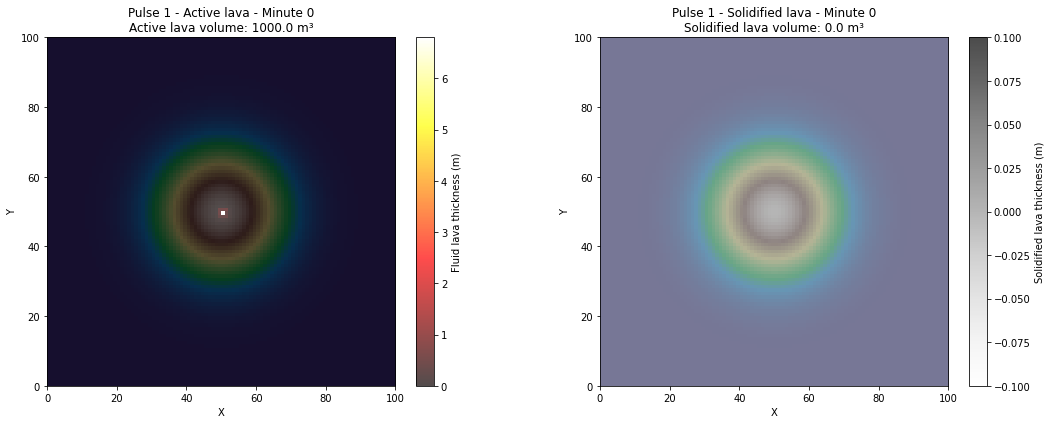

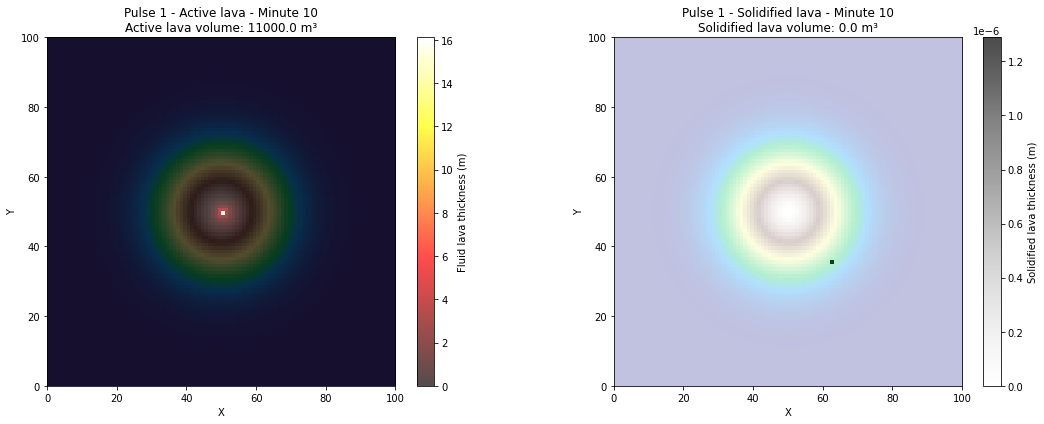

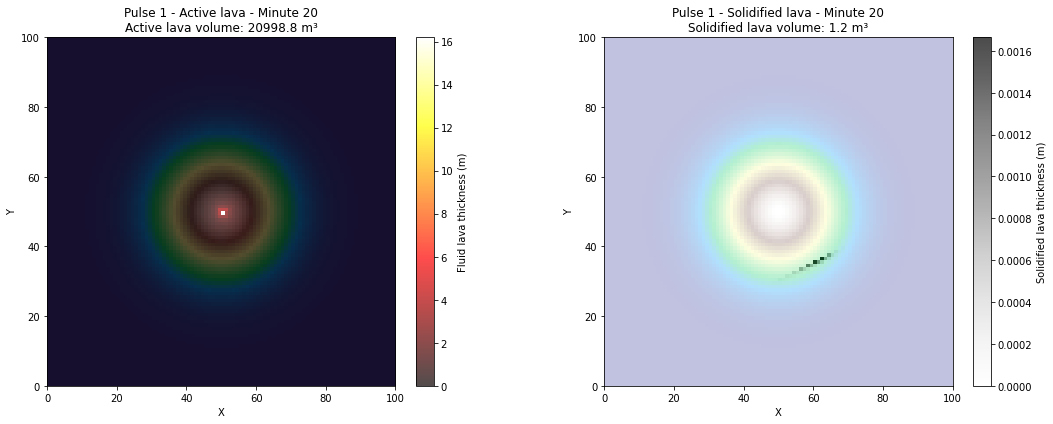

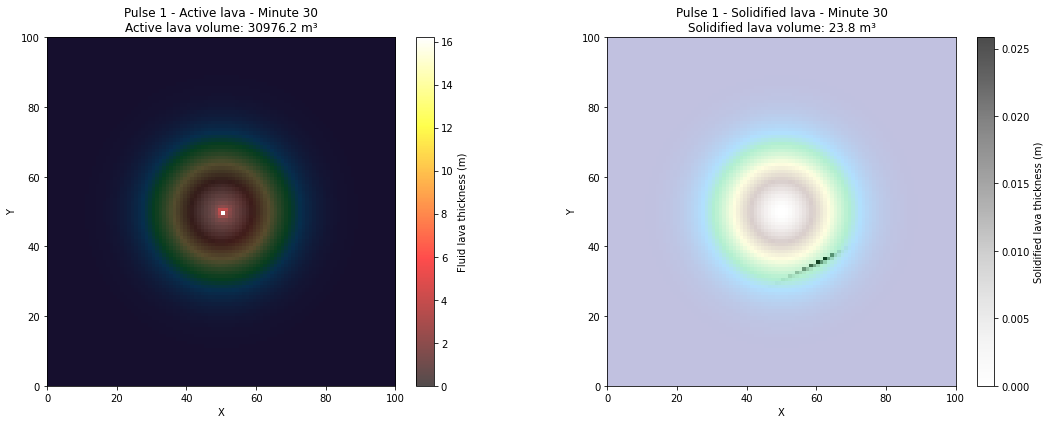

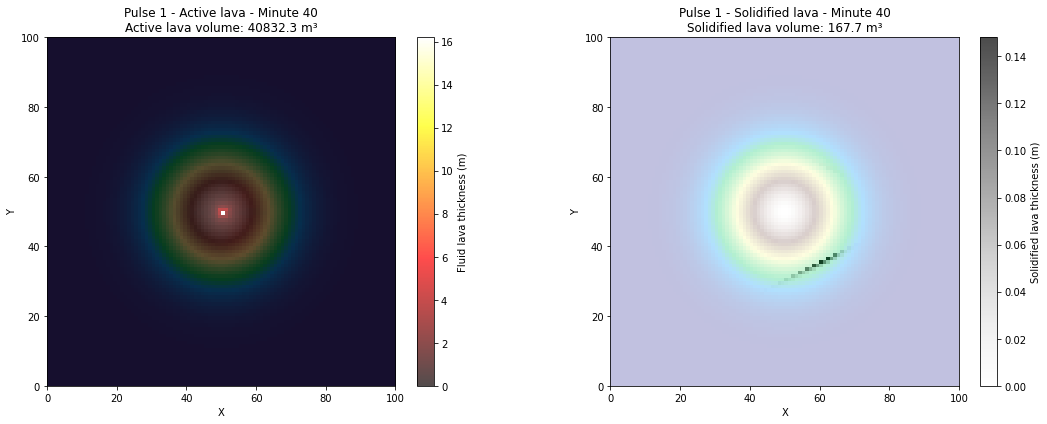

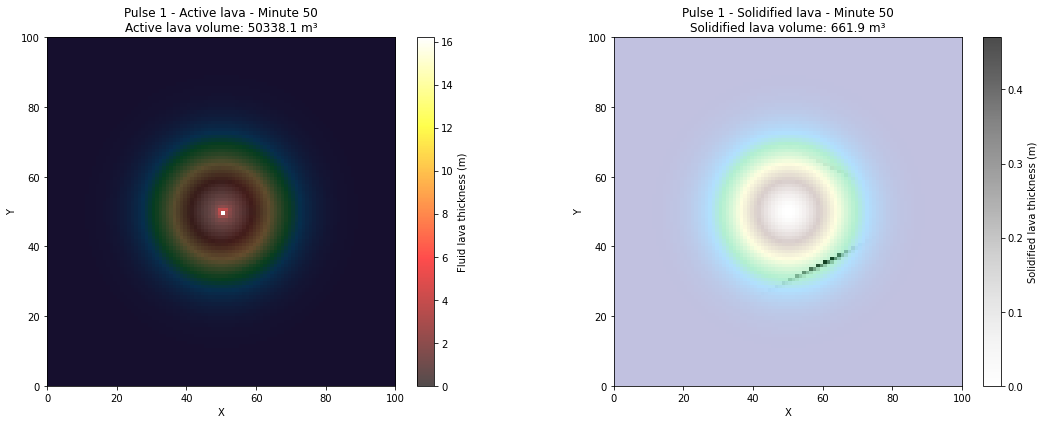

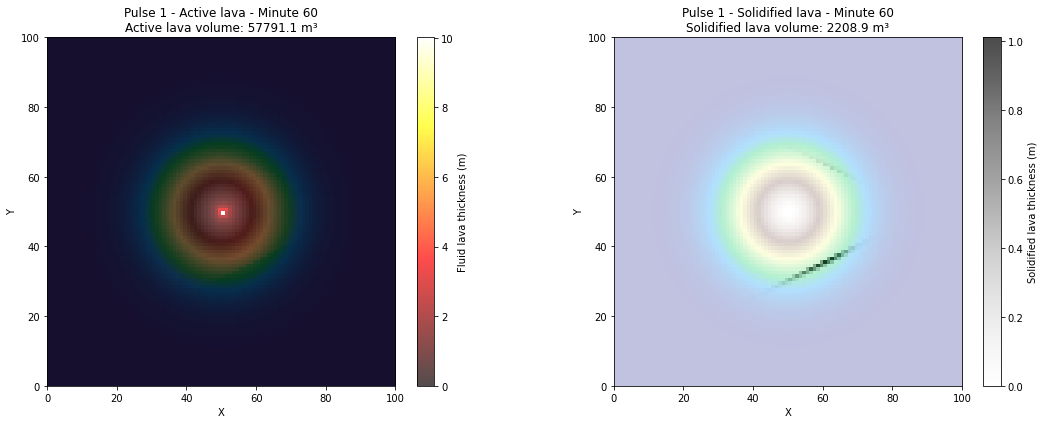

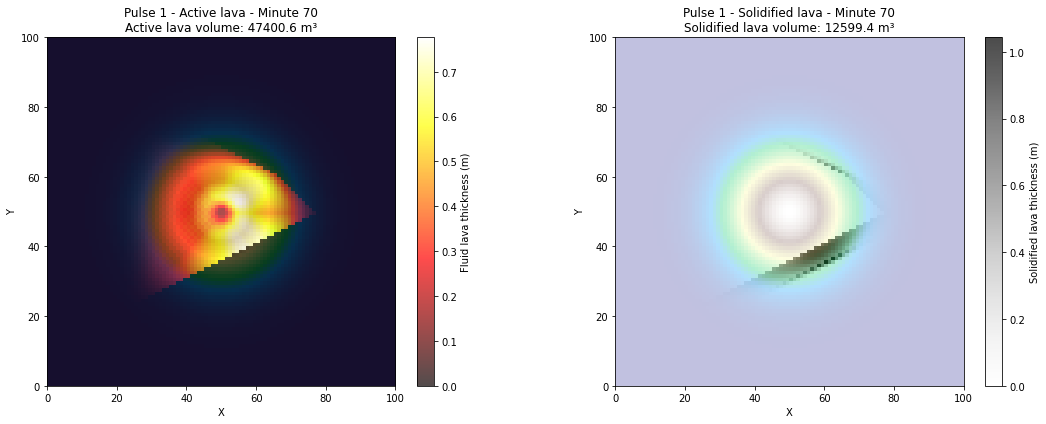

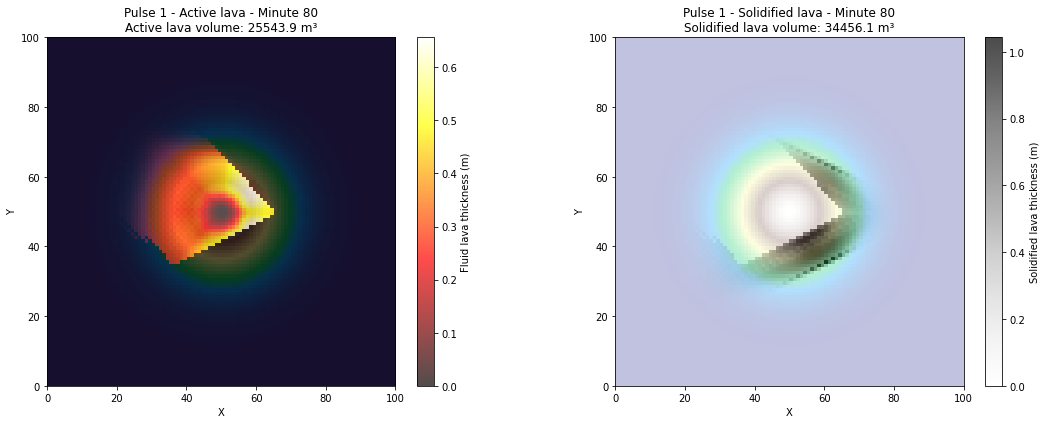

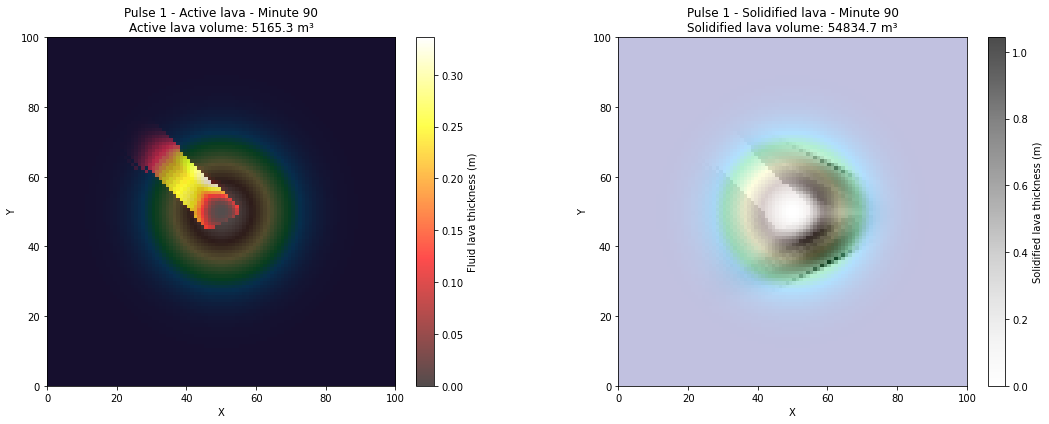


Pulse 1 simulation stopped at minute 95 because the solidified lava volume (60089.5 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 1 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): -89.5 m³
Solidified lava volume: 60089.5 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

=== Volcanic pulse simulation 2 ===


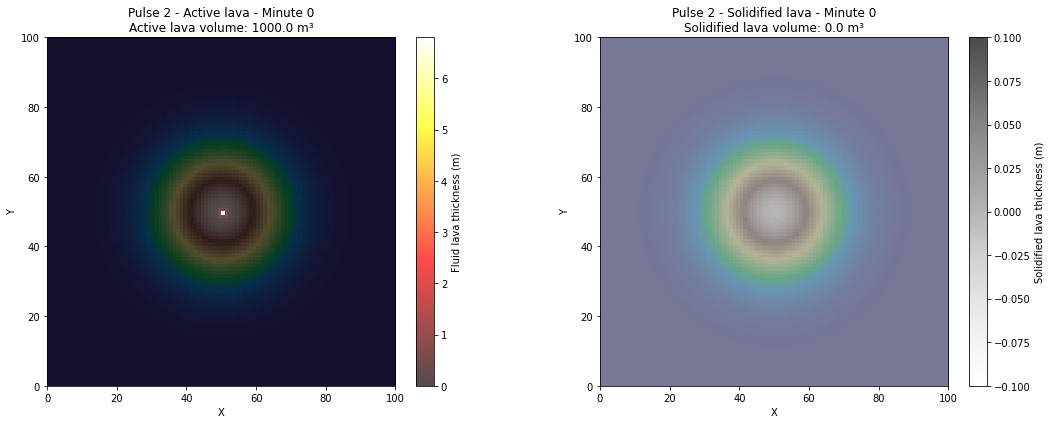

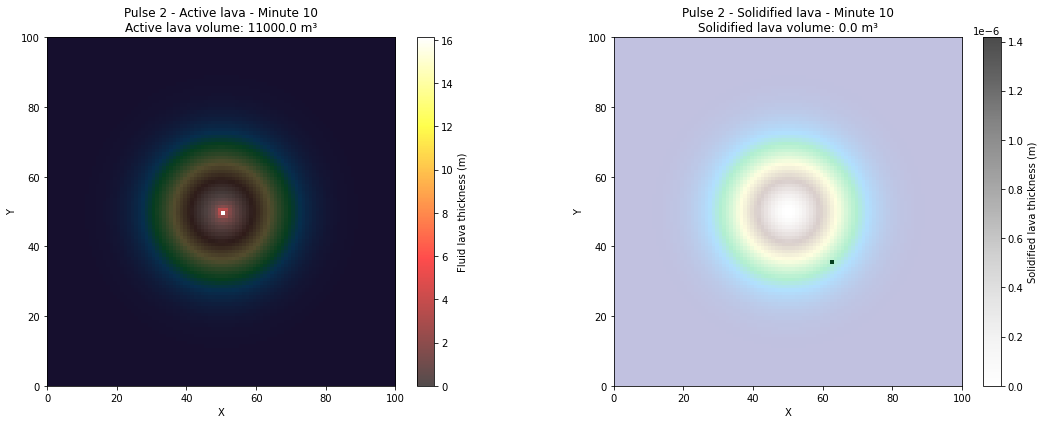

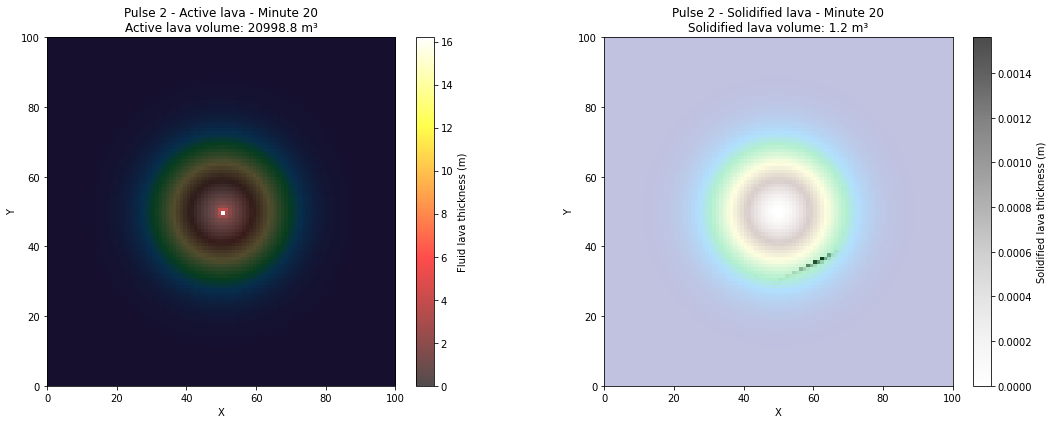

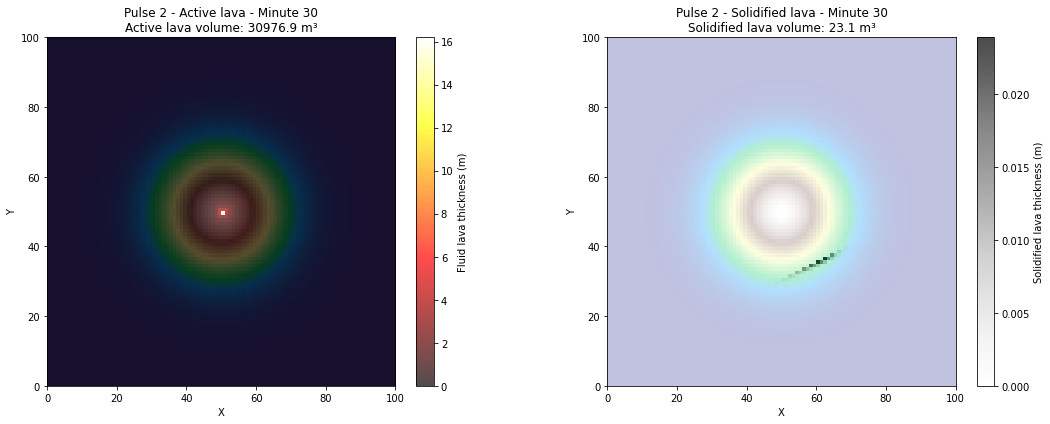

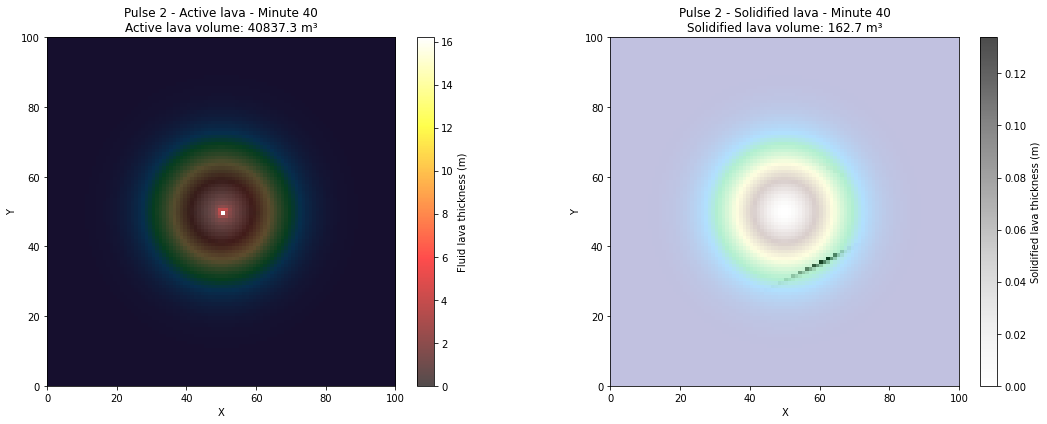

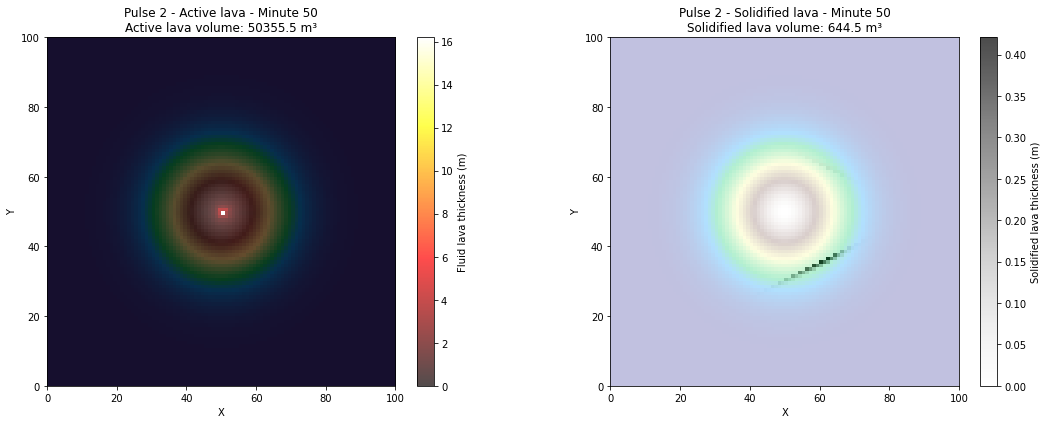

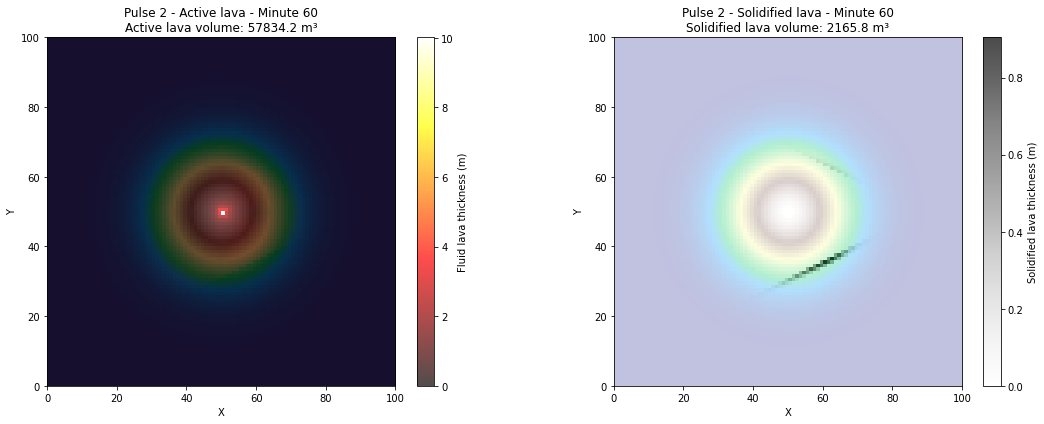

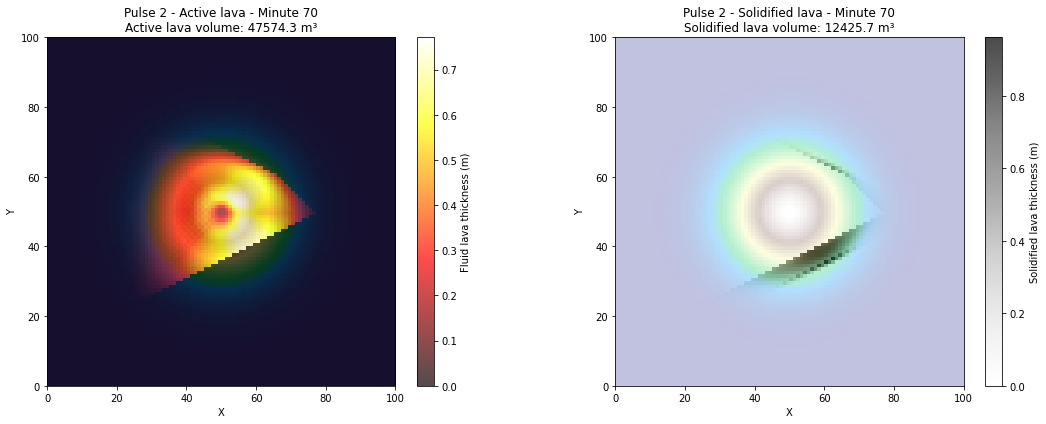

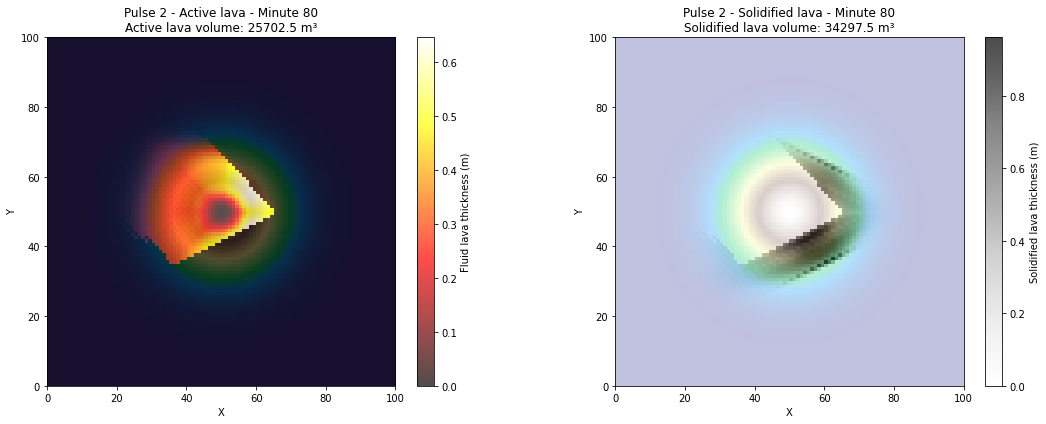

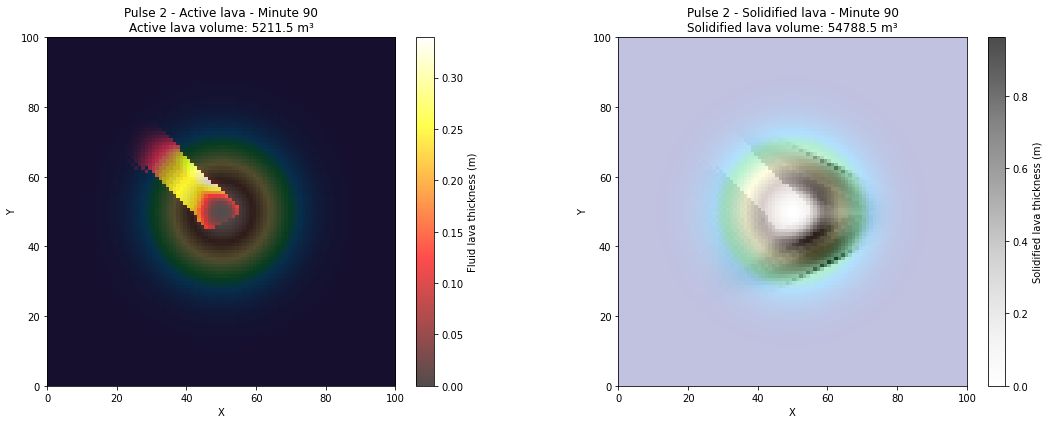


Pulse 2 simulation stopped at minute 95 because the solidified lava volume (60088.9 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 2 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): -88.9 m³
Solidified lava volume: 60088.9 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

=== Volcanic pulse simulation 3 ===


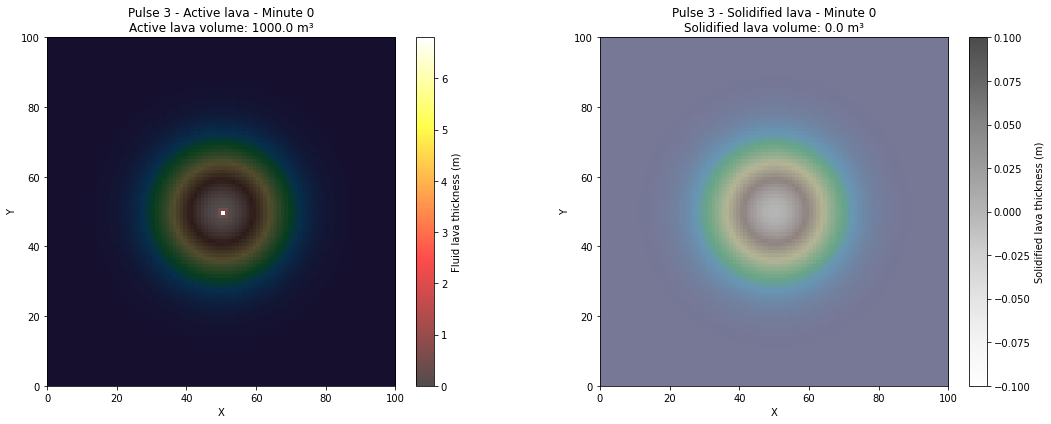

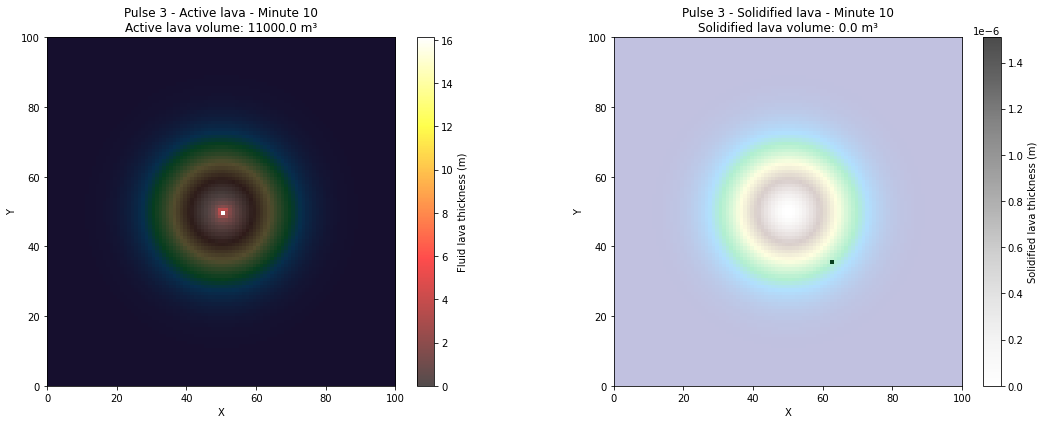

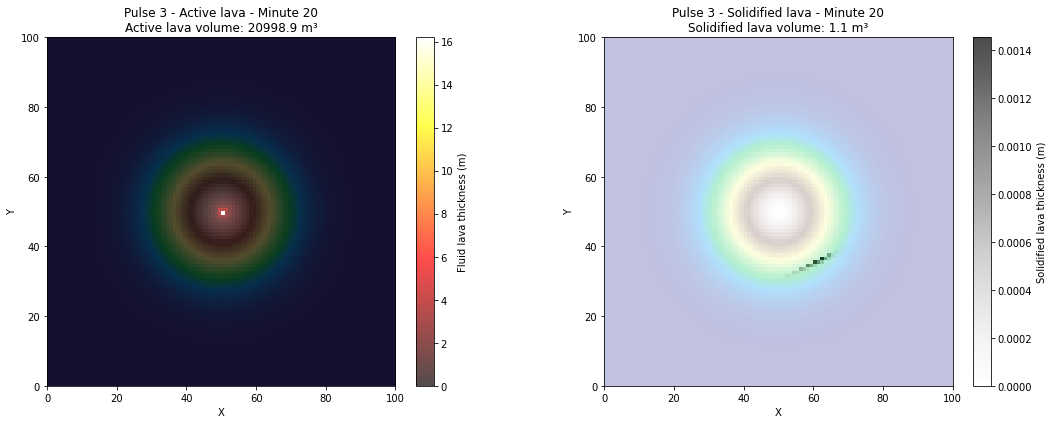

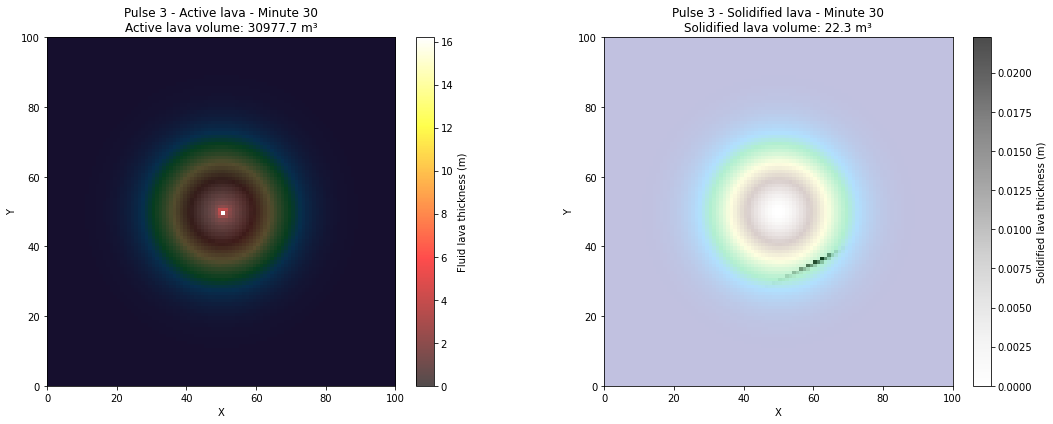

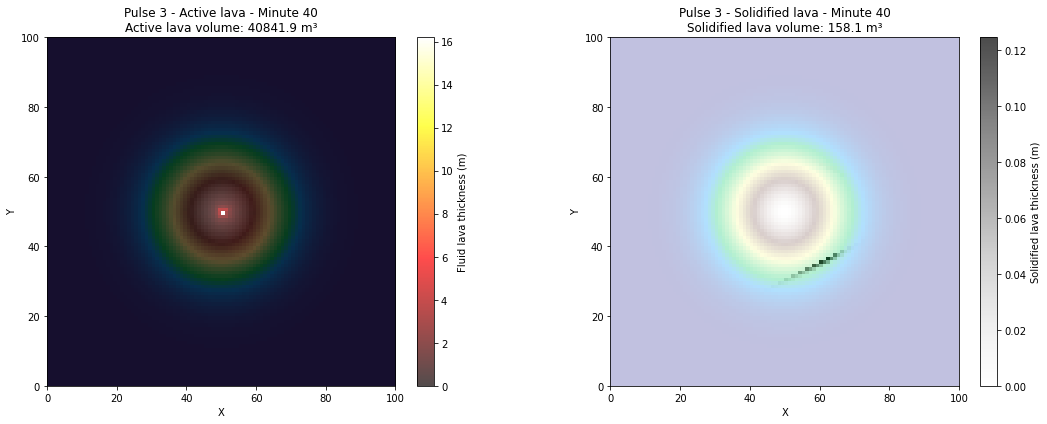

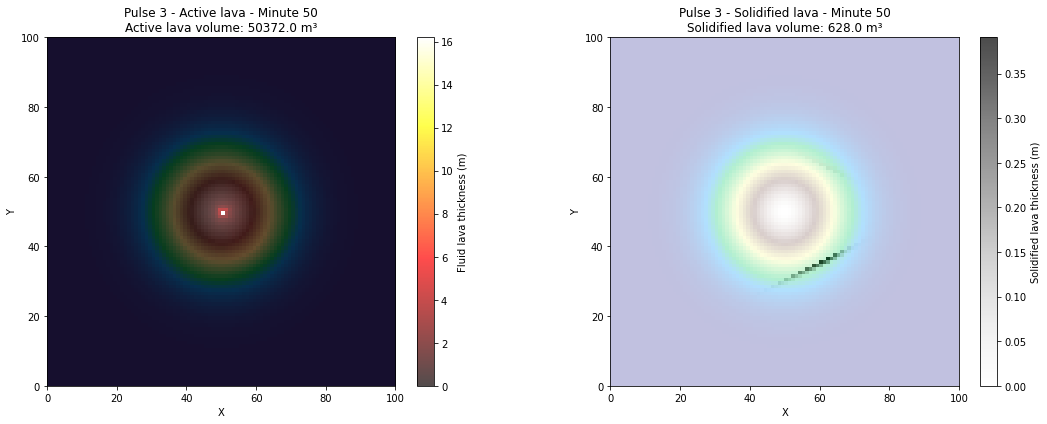

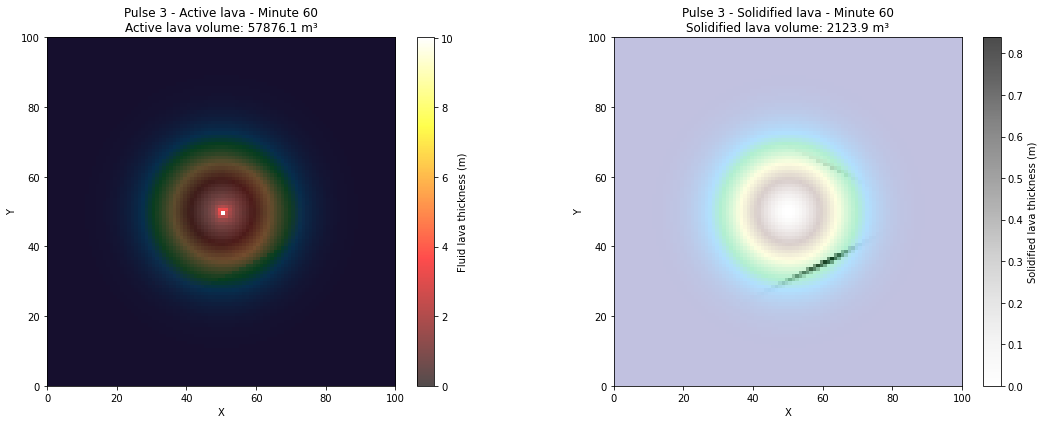

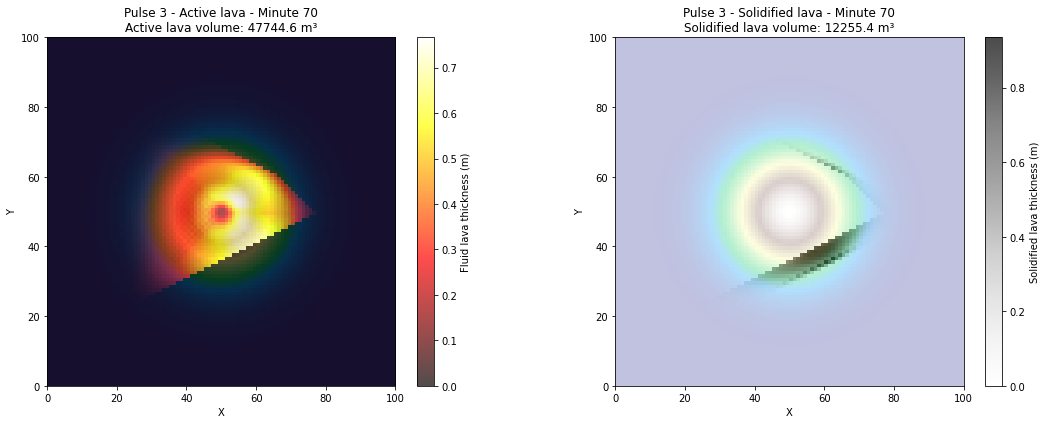

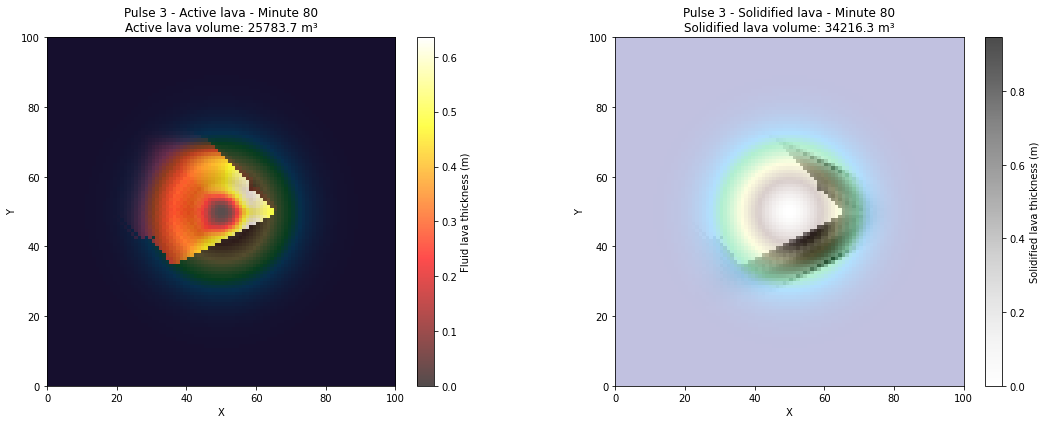

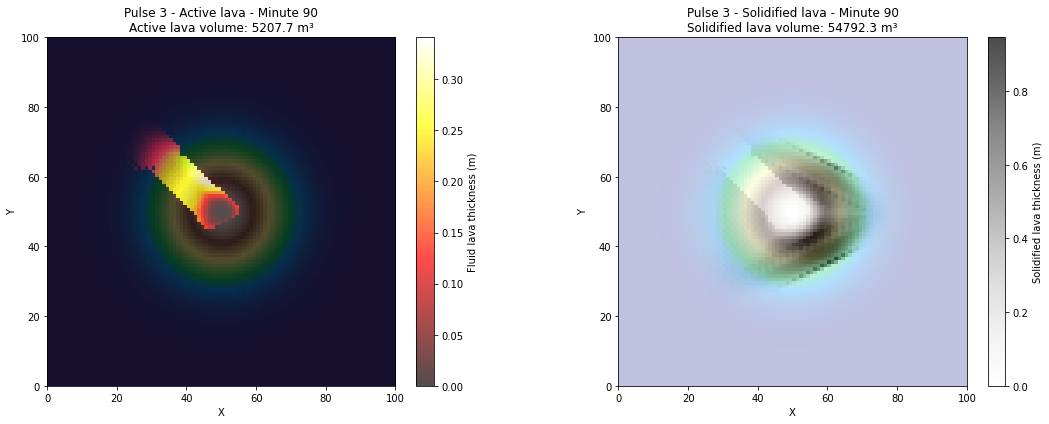


Pulse 3 simulation stopped at minute 95 because the solidified lava volume (60097.2 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 3 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): -97.2 m³
Solidified lava volume: 60097.2 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³


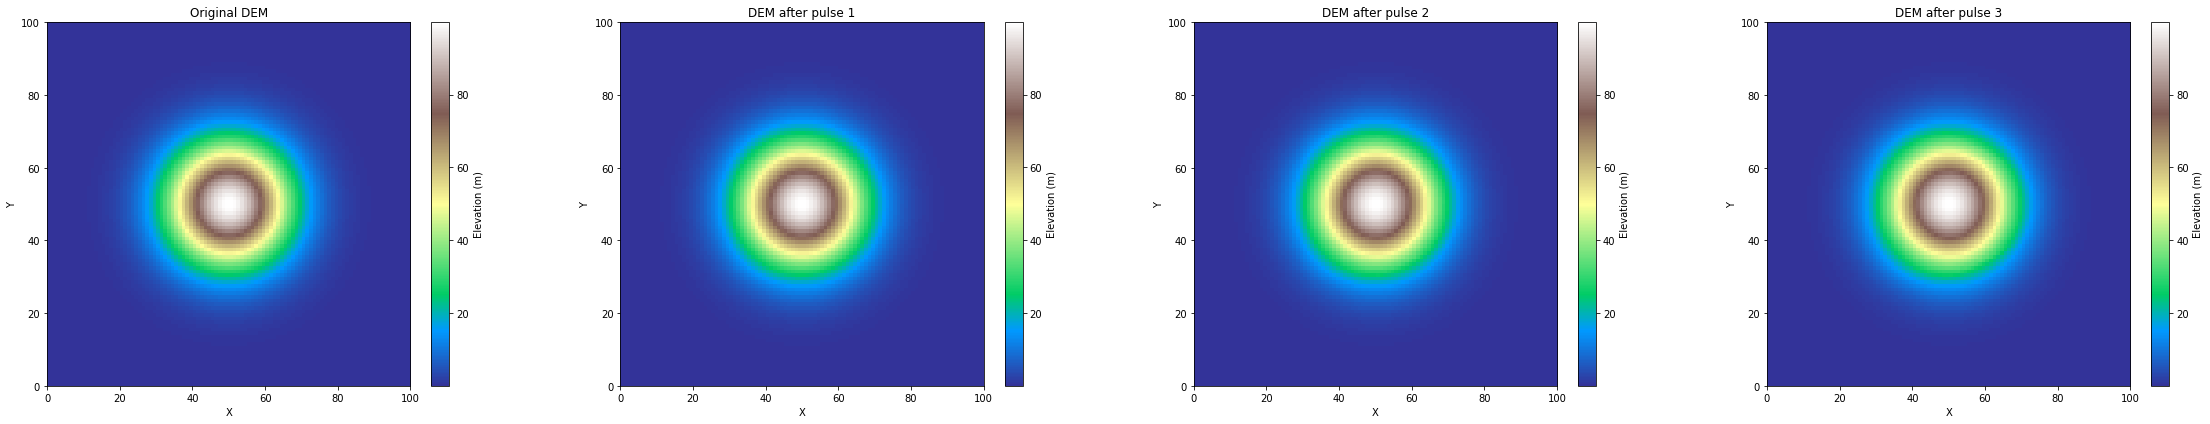


--- DEM statistics after pulse 1 ---
Minimum: 0.00 m
Maximum: 99.82 m
Mean: 8.61 m
Standard deviation: 18.95 m

--- DEM statistics after pulse 2 ---
Minimum: 0.00 m
Maximum: 99.82 m
Mean: 8.67 m
Standard deviation: 19.07 m

--- DEM statistics after pulse 3 ---
Minimum: 0.00 m
Maximum: 99.82 m
Mean: 8.73 m
Standard deviation: 19.19 m


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Adjusted simulation constants
n = 100  # Grid size n x n

cell_area = 100  # Area of each cell (10m x 10m)
T_amb = 300  # Ambient temperature (K) - 27°C
k = 0.009  # Adjusted cooling rate
R = 8.314  # Universal ideal gas constant (J/(mol·K))
E = 30000  # Activation energy (J/mol)
eta_0 = 3e5  # Pre-exponential factor (Pa·s)
dt = 1  # 1 minute per step
emission_rate = 1000  # Lava emission rate (m³/min)
emission_duration = 60  # Emission duration in minutes
T_solidify = 1000  # Solidification temperature (K) - 727°C
epsilon = 1e-6  # Threshold to ignore small amounts of lava

# Number of volcanic pulses
num_pulses = 3

# Functions
def viscosity(T):
    return eta_0 * np.exp(E / (R * T))  # Lava viscosity as a function of temperature (Arrhenius law)

def cool_down(T):
    return T - k * (T - T_amb) * dt  # Newton's law of cooling equation

def get_neighborhood(grid, x, y):
    neighbors = []
    for dx in [-1, 0, 1]:
        for dy in [-1, 0, 1]:
            nx, ny = x + dx, y + dy
            if (dx != 0 or dy != 0) and 0 <= nx < n and 0 <= ny < n:
                neighbors.append((nx, ny))
    return neighbors

def create_gaussian_dem(n, height):
    """Create a Gaussian DEM centered in the middle of the grid with a specified maximum height."""
    x = np.linspace(-3, 3, n)
    y = np.linspace(-3, 3, n)
    x, y = np.meshgrid(x, y)
    z = height * np.exp(-(x**2 + y**2))
    return z

def transition_function(x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment):
    T = temp_grid[x, y]
    eta = viscosity(T)
    prob_flow = np.exp(-eta / 5e6)

    # Process only if there is a significant amount of lava
    if grid[x, y] > epsilon or (add_lava and x == n//2 and y == n//2):
        # Lava cooling in the cell
        temp_grid[x, y] = cool_down(T)

        # Check solidification
        if grid[x, y] > epsilon and temp_grid[x, y] <= T_solidify:
            # Move lava from fluid to solid
            solid_grid[x, y] += grid[x, y]  # Add solidified lava to solid_grid
            grid[x, y] = 0  # No fluid lava remains in this cell
            temp_grid[x, y] = T_solidify  # Solid lava temperature is kept at T_solidify
            return grid, temp_grid, solid_grid

        # If new lava is added, add it to the central cell
        if add_lava and x == n//2 and y == n//2:
            grid[x, y] += lava_increment
            temp_grid[x, y] = 1300  # Reset initial lava temperature

        # Compute flow to neighbors based on slope
        neighbors = get_neighborhood(grid, x, y)
        flow_potentials = []
        total_potential = 0
        for nx, ny in neighbors:
            # Height difference (considering DEM, fluid lava, and solidified lava)
            height_diff = (dem[x, y] + grid[x, y] + solid_grid[x, y]) - \
                          (dem[nx, ny] + grid[nx, ny] + solid_grid[nx, ny])
            # Lava flows downhill
            if height_diff > 0:
                flow_potentials.append((nx, ny, height_diff))
                total_potential += height_diff

        # Distribute lava to neighbors
        if total_potential > 0:
            lava_to_distribute = grid[x, y] * prob_flow
            lava_to_distribute = min(lava_to_distribute, grid[x, y])  # Do not distribute more than exists
            for nx, ny, potential in flow_potentials:
                flow_fraction = potential / total_potential
                lava_flow = lava_to_distribute * flow_fraction
                if lava_flow > epsilon:
                    grid[nx, ny] += lava_flow
                    grid[x, y] -= lava_flow
                    temp_grid[nx, ny] = temp_grid[x, y]  # Lava temperature remains the same

    return grid, temp_grid, solid_grid

def run_simulation(dem_input, pulse_number):
    # Initialization
    dem = dem_input.copy()
    grid = np.zeros((n, n))  # Fluid lava
    solid_grid = np.zeros((n, n))  # Solidified lava
    temp_grid = np.full((n, n), T_amb)
    grid[n//2, n//2] = 1  # Initial lava in the central cell
    temp_grid[n//2, n//2] = 1300  # Initial lava temperature

    # Simulation
    steps = 120
    total_emitted_volume = 0
    lava_increment = emission_rate / cell_area  # Lava volume added to the central cell per step

    for step in range(steps):
        add_lava = step < emission_duration
        for x in range(n):
            for y in range(n):
                grid, temp_grid, solid_grid = transition_function(
                    x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment)

        if add_lava:
            total_emitted_volume += emission_rate

        # Compute active and solidified lava volumes
        active_lava_volume = np.sum(grid) * cell_area  # Active (fluid) lava in m³
        solid_lava_volume = np.sum(solid_grid) * cell_area  # Solidified lava in m³
        total_lava_volume = active_lava_volume + solid_lava_volume

        # Check that total lava volume matches emitted volume
        volume_difference = total_emitted_volume - total_lava_volume

        # Add stopping condition
        if solid_lava_volume >= total_emitted_volume:
            print(f'\nPulse {pulse_number} simulation stopped at minute {step} because the solidified lava volume ({solid_lava_volume:.1f} m³) '
                  f'is equal to or exceeds the total emitted volume ({total_emitted_volume:.1f} m³).')
            break

        if step % 10 == 0:  # Plot every 10 minutes
            # Create a figure with two subplots side by side
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

            # Active lava plot
            im1 = ax1.imshow(dem, cmap='terrain', extent=[0, n, 0, n])
            im2 = ax1.imshow(grid, cmap='hot', alpha=0.7, extent=[0, n, 0, n])
            ax1.set_title(f'Pulse {pulse_number} - Active lava - Minute {step}\nActive lava volume: {active_lava_volume - cell_area:.1f} m³')
            ax1.set_xlabel('X')
            ax1.set_ylabel('Y')
            cbar1 = fig.colorbar(im2, ax=ax1, fraction=0.046, pad=0.04)
            cbar1.set_label('Fluid lava thickness (m)')

            # Solidified lava plot
            im3 = ax2.imshow(dem, cmap='terrain', extent=[0, n, 0, n])
            im4 = ax2.imshow(solid_grid, cmap='Greys', alpha=0.7, extent=[0, n, 0, n])
            ax2.set_title(f'Pulse {pulse_number} - Solidified lava - Minute {step}\nSolidified lava volume: {solid_lava_volume:.1f} m³')
            ax2.set_xlabel('X')
            ax2.set_ylabel('Y')
            cbar2 = fig.colorbar(im4, ax=ax2, fraction=0.046, pad=0.04)
            cbar2.set_label('Solidified lava thickness (m)')

            plt.tight_layout()
            plt.show()

    # Final results of the pulse
    print(f'\n--- Final results of Pulse {pulse_number} ---')
    print(f'Total emitted volume: {total_emitted_volume:.1f} m³')
    print(f'Active lava volume (fluid): {active_lava_volume - cell_area:.1f} m³')
    print(f'Solidified lava volume: {solid_lava_volume:.1f} m³')
    print(f'Total lava volume (active + solid): {total_lava_volume:.1f} m³')
    print(f'Volume difference (emitted - total): {volume_difference:.1f} m³')

    # Compute final DEM by adding solidified lava to the input DEM
    dem_final = dem + solid_grid

    return dem_final

# Create the original DEM
height = 100  # Maximum DEM height
dem_original = create_gaussian_dem(n, height)

# Run multiple volcanic pulses
dem_list = [dem_original]  # List to store DEMs after each pulse

for pulse in range(1, num_pulses + 1):
    print(f"\n=== Volcanic pulse simulation {pulse} ===")
    dem_new = run_simulation(dem_list[-1], pulse_number=pulse)
    dem_list.append(dem_new)

# Compare original and final DEMs
# Create a figure with subplots for each DEM
num_dems = len(dem_list)
fig, axes = plt.subplots(1, num_dems, figsize=(8 * num_dems, 6))

for i, ax in enumerate(axes):
    im = ax.imshow(dem_list[i], cmap='terrain', extent=[0, n, 0, n])
    if i == 0:
        ax.set_title('Original DEM')
    else:
        ax.set_title(f'DEM after pulse {i}')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Elevation (m)')

plt.tight_layout()
plt.show()

# Statistics for output DEMs across different pulses

for i, dem in enumerate(dem_list[1:]):
    print(f"\n--- DEM statistics after pulse {i + 1} ---")
    print(f"Minimum: {np.min(dem):.2f} m")
    print(f"Maximum: {np.max(dem):.2f} m")
    print(f"Mean: {np.mean(dem):.2f} m")
    print(f"Standard deviation: {np.std(dem):.2f} m")



=== Volcanic pulse simulation 1 ===


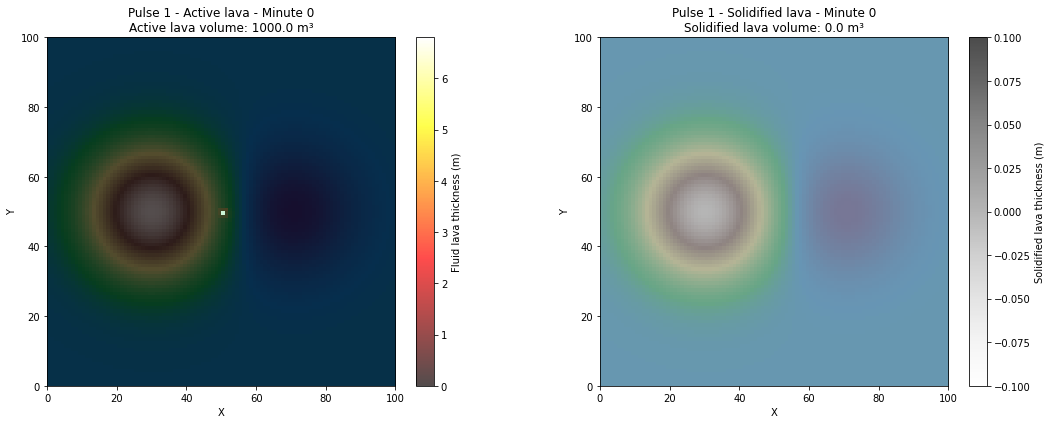

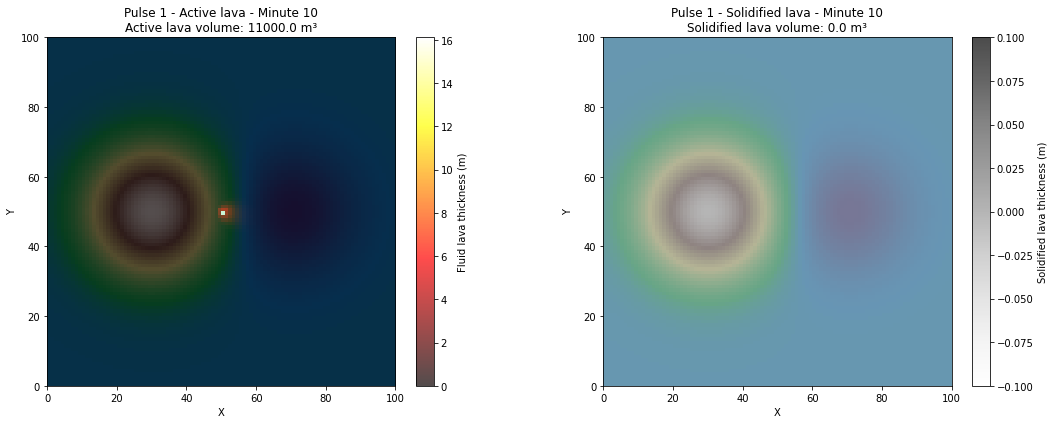

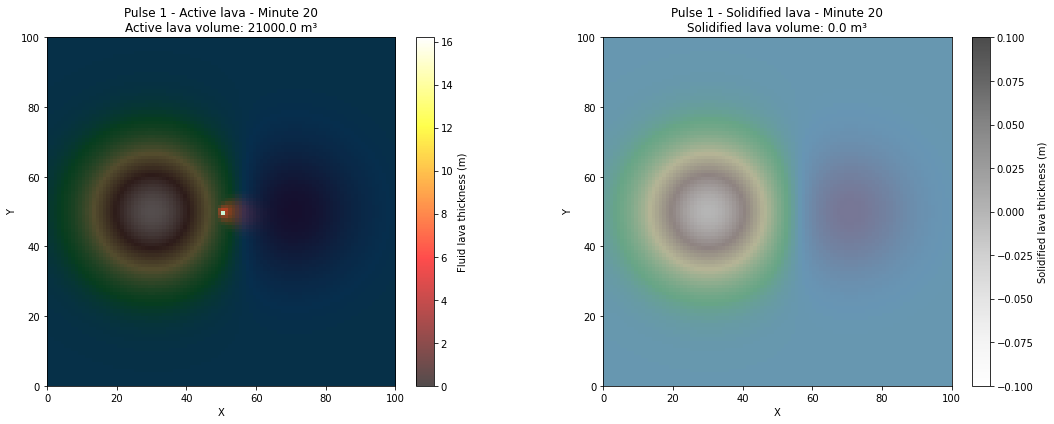

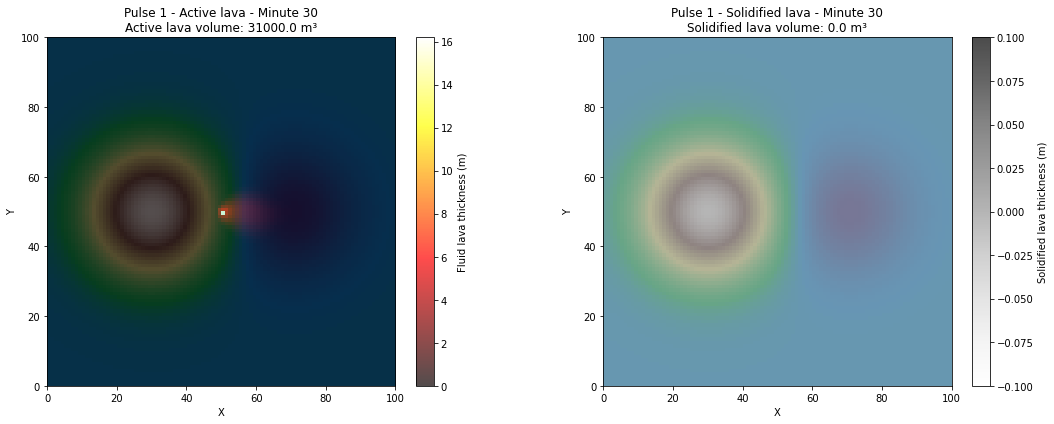

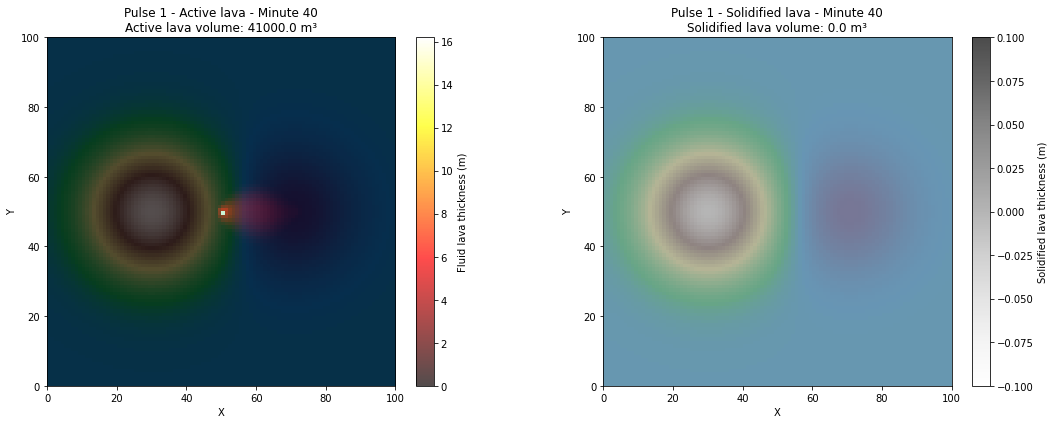

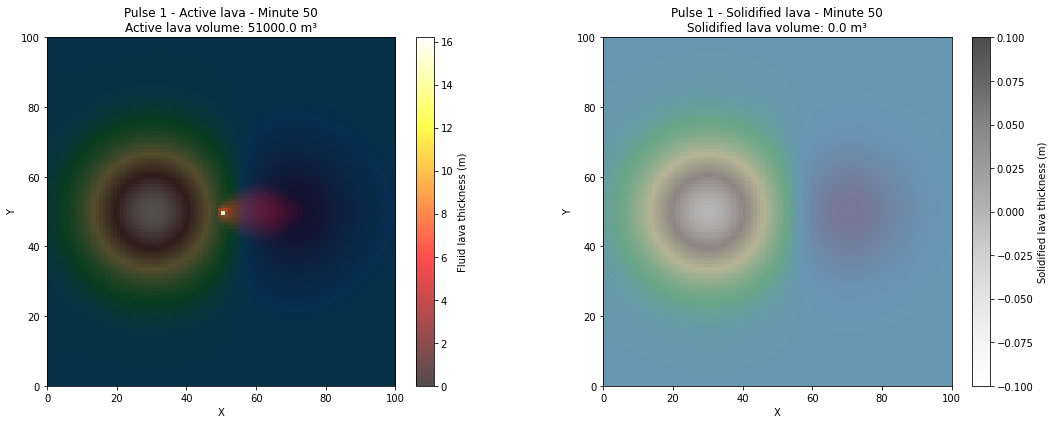

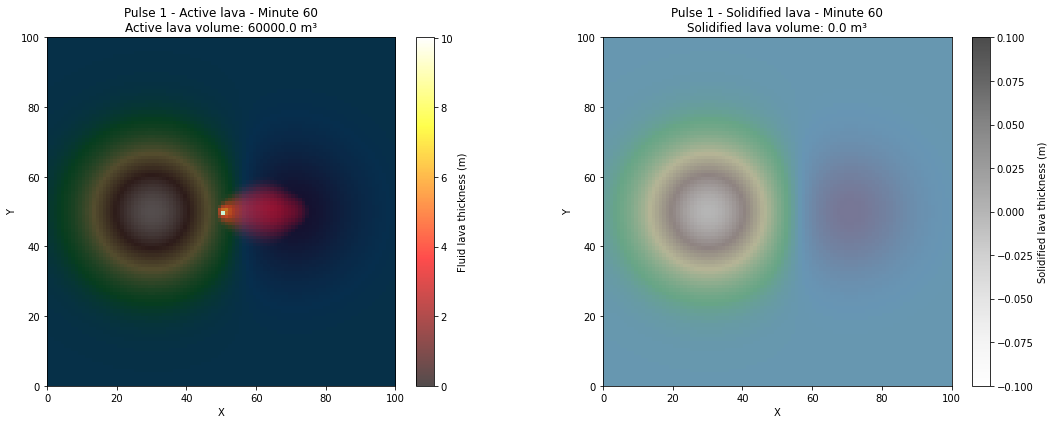

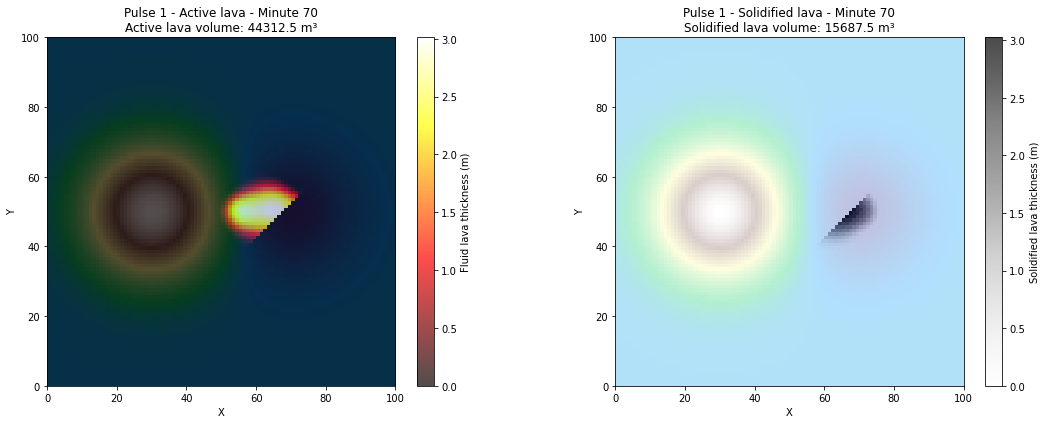

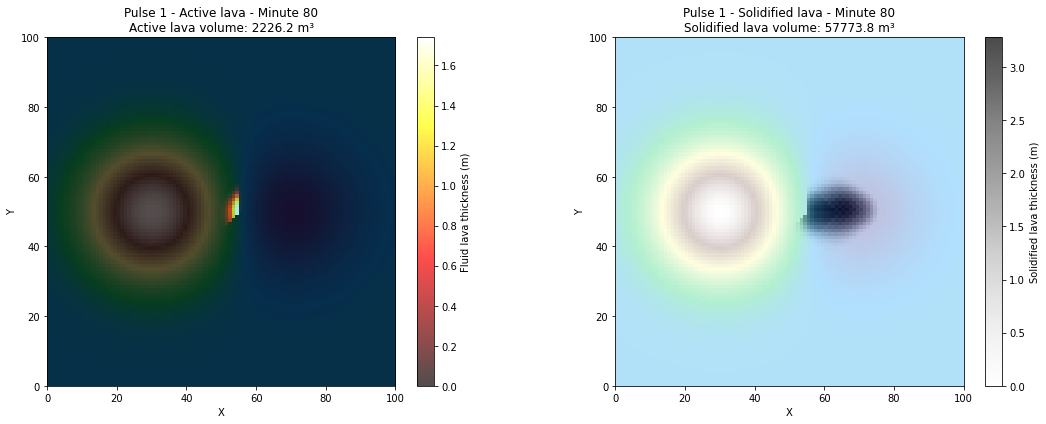


Pulse 1 simulation stopped at minute 84 because the solidified lava volume (60079.3 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 1 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): -79.3 m³
Solidified lava volume: 60079.3 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

=== Volcanic pulse simulation 2 ===


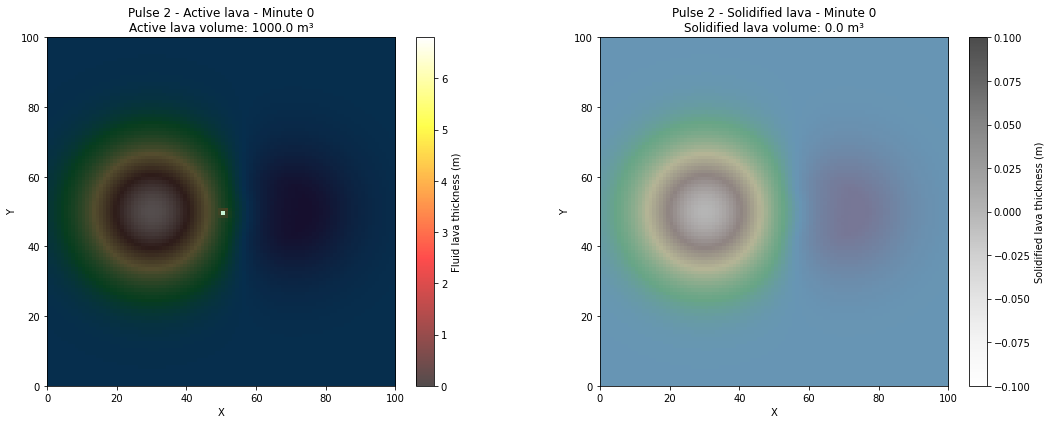

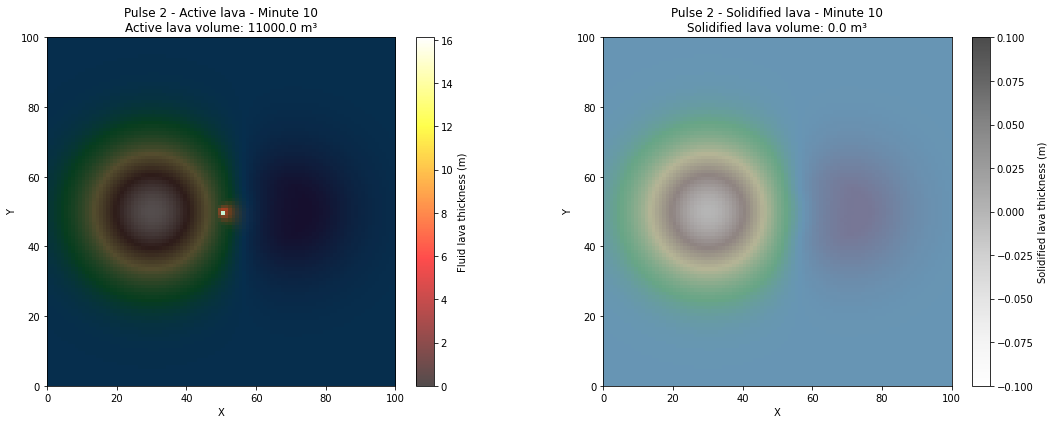

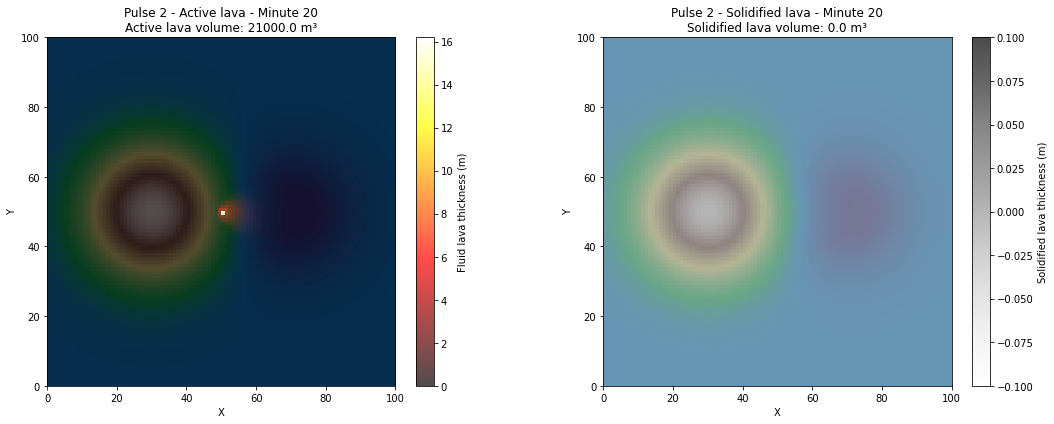

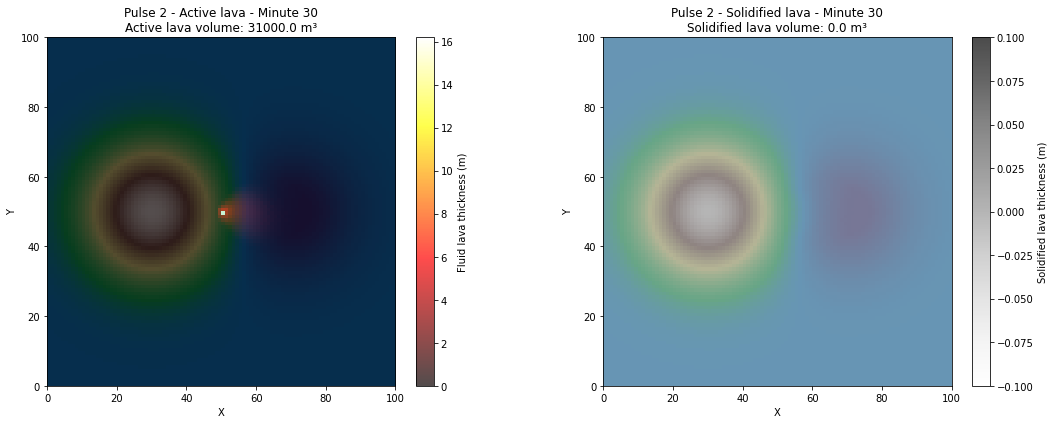

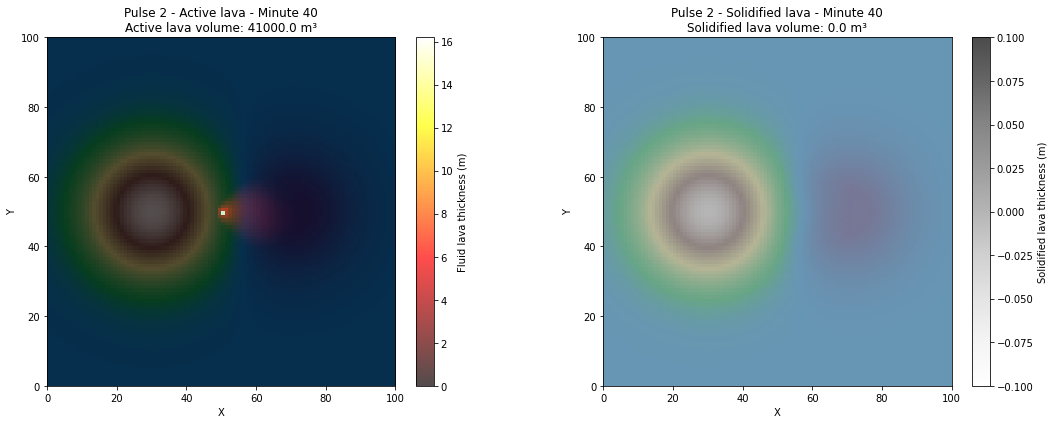

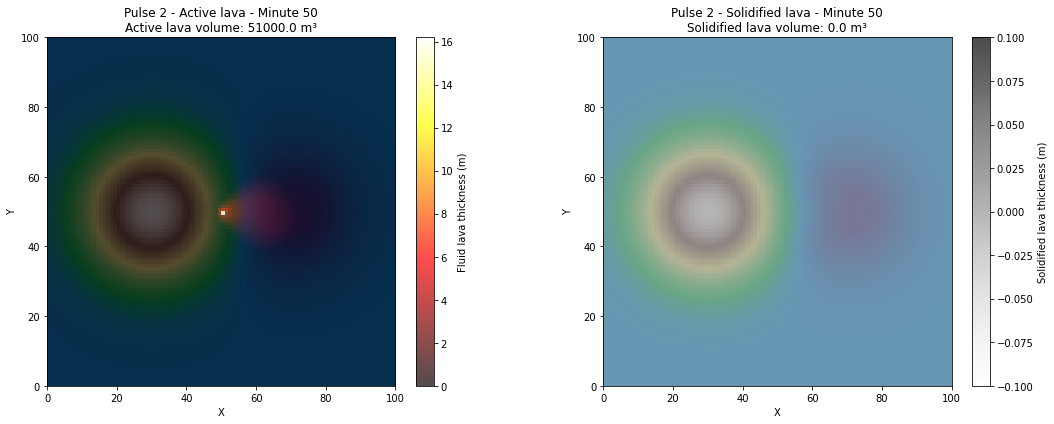

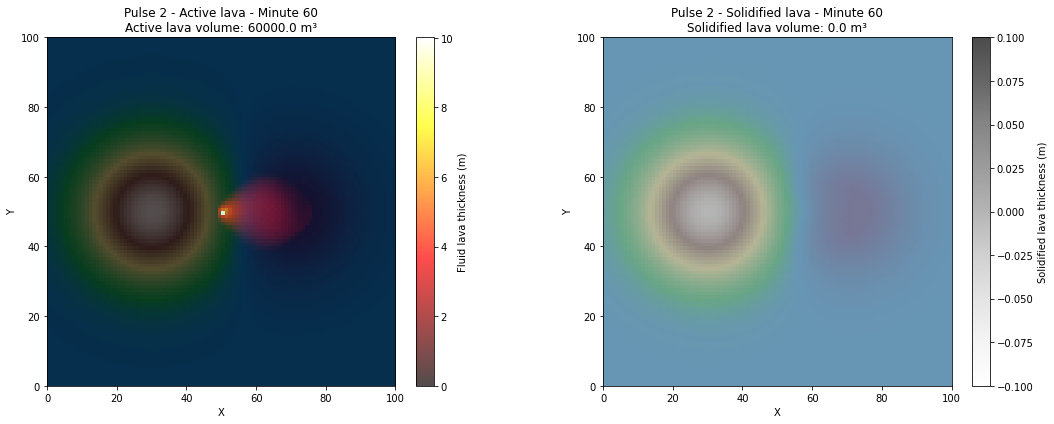

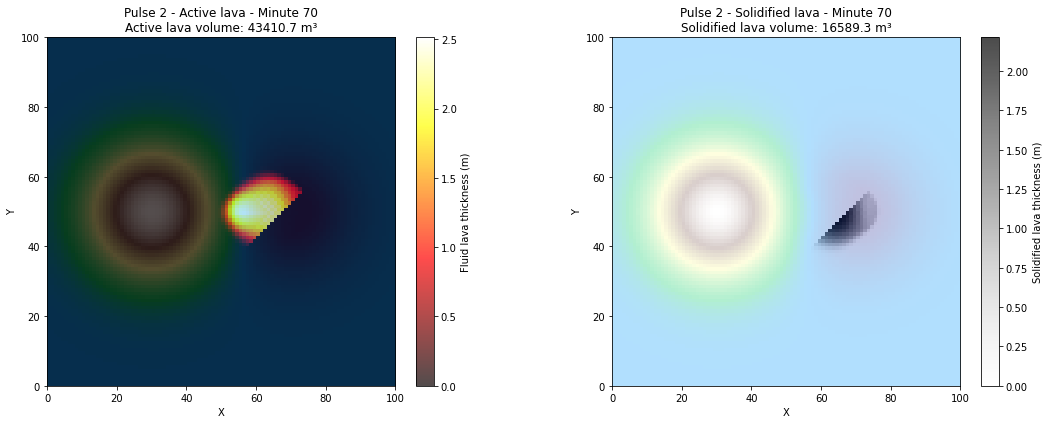

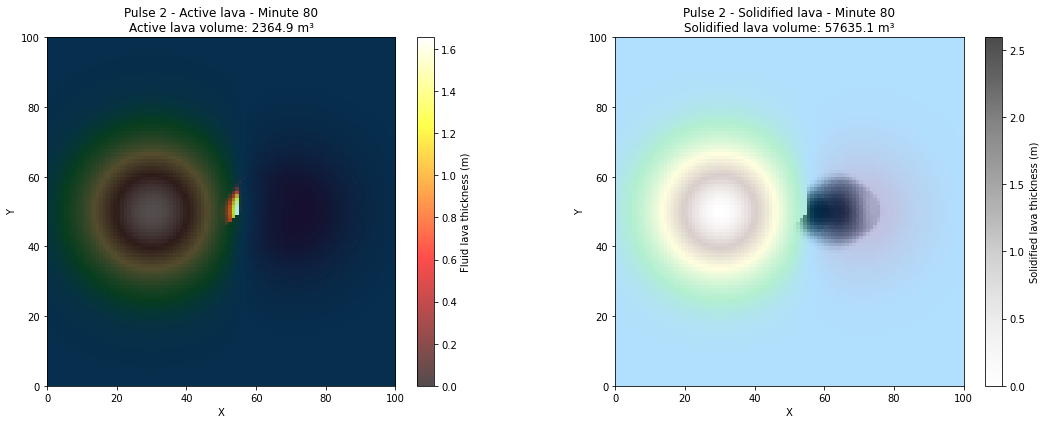


Pulse 2 simulation stopped at minute 84 because the solidified lava volume (60078.9 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 2 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): -78.9 m³
Solidified lava volume: 60078.9 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

=== Volcanic pulse simulation 3 ===


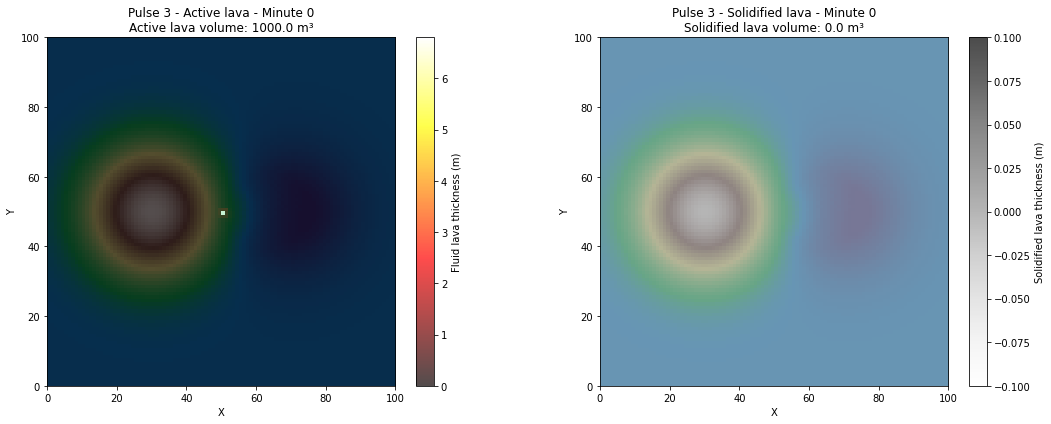

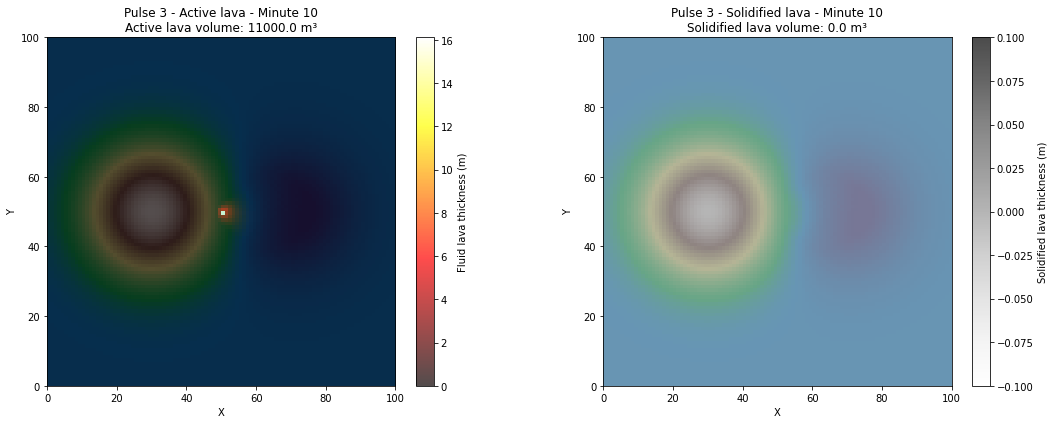

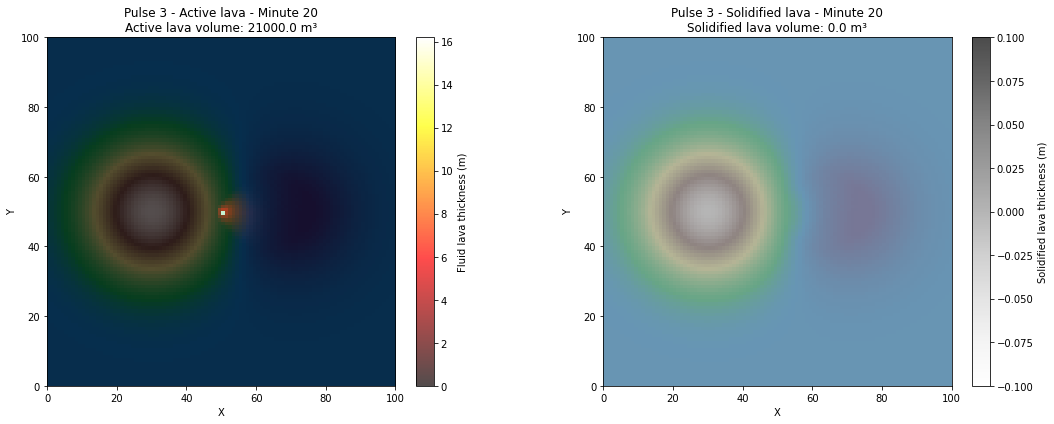

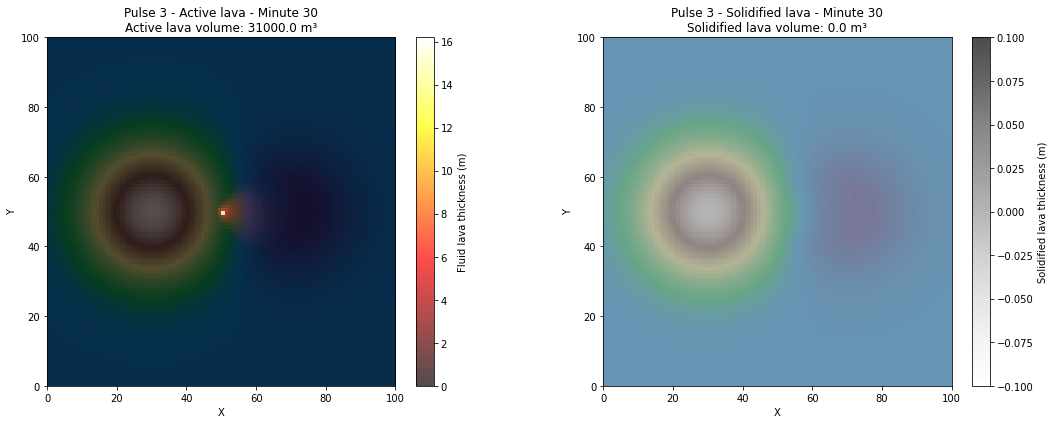

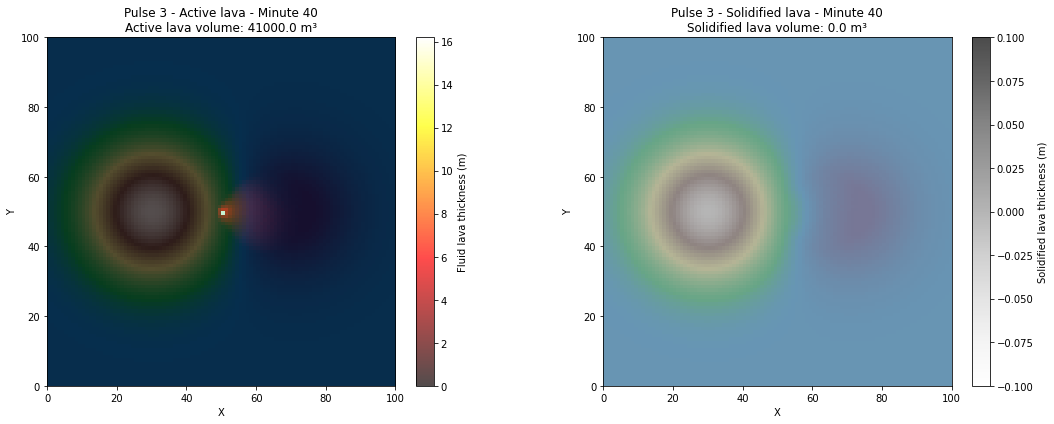

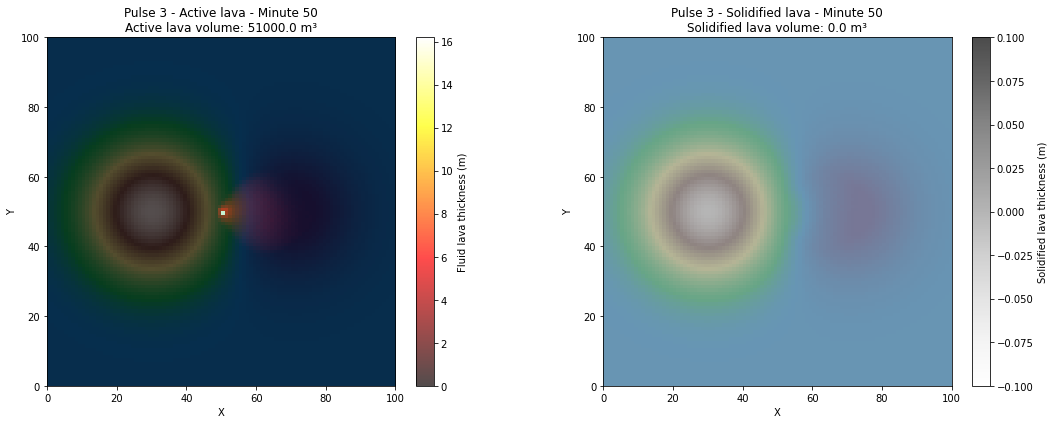

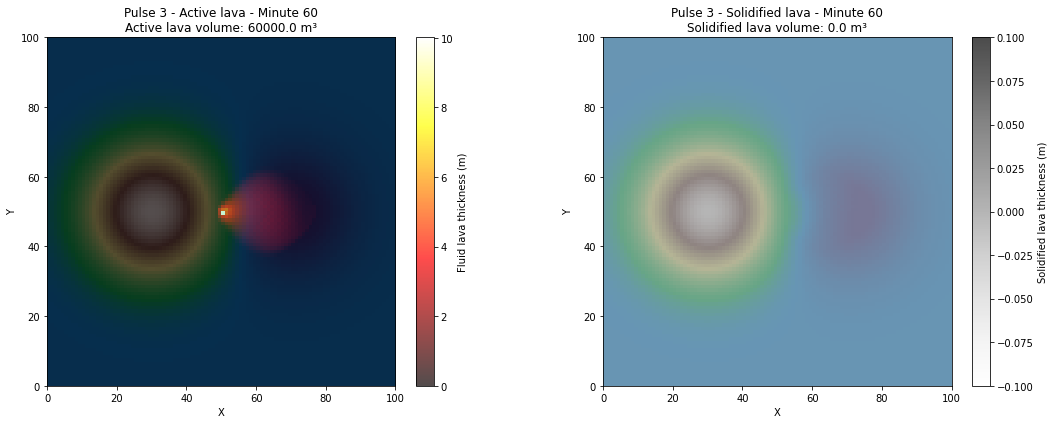

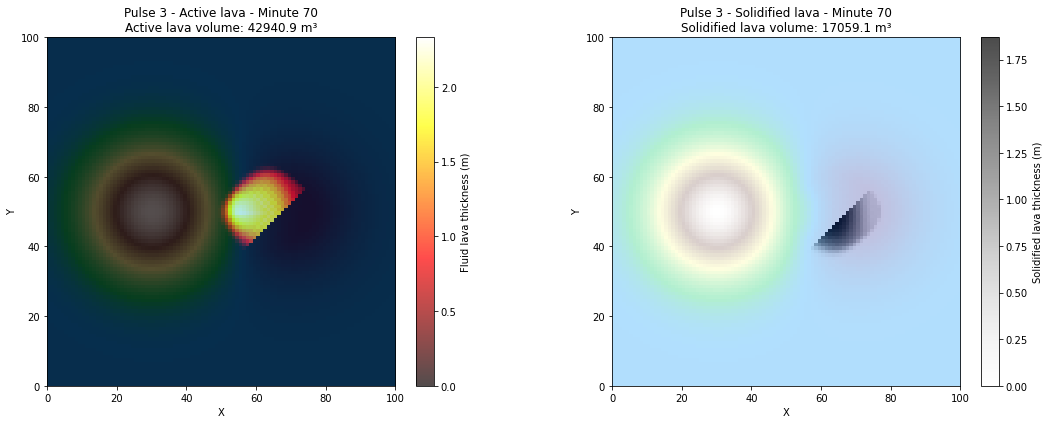

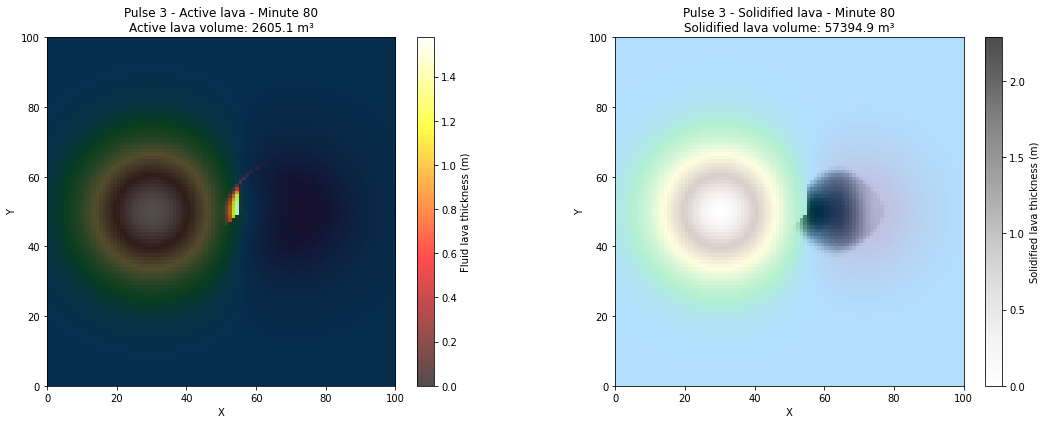


Pulse 3 simulation stopped at minute 84 because the solidified lava volume (60078.4 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 3 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): -78.4 m³
Solidified lava volume: 60078.4 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³


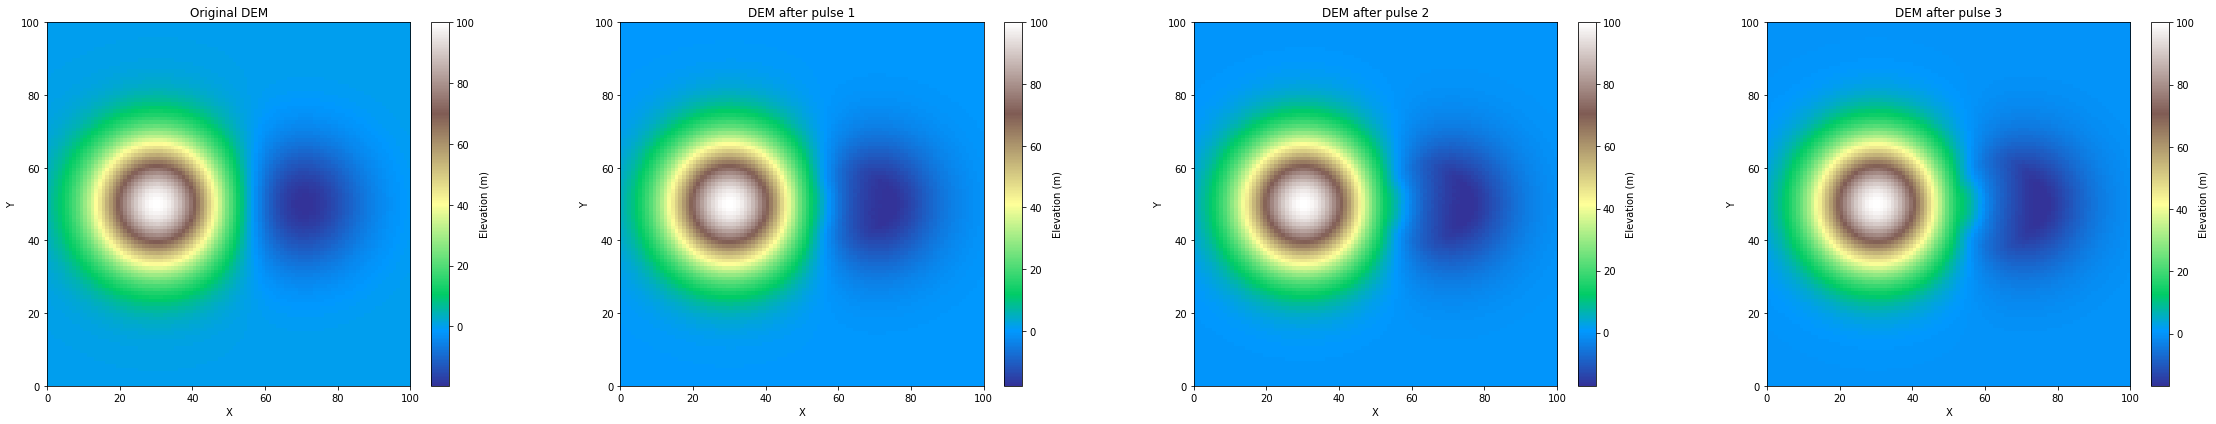


--- DEM statistics after pulse 1 ---
Minimum: -17.80 m
Maximum: 100.00 m
Mean: 7.72 m
Standard deviation: 20.66 m

--- DEM statistics after pulse 2 ---
Minimum: -17.14 m
Maximum: 100.00 m
Mean: 7.78 m
Standard deviation: 20.62 m

--- DEM statistics after pulse 3 ---
Minimum: -16.76 m
Maximum: 100.00 m
Mean: 7.84 m
Standard deviation: 20.58 m


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Adjusted simulation constants
n = 100  # Grid size n x n
cell_area = 100  # Area of each cell (10m x 10m)
T_amb = 300  # Ambient temperature (K) - 27°C
k = 0.009  # Adjusted cooling rate
R = 8.314  # Universal ideal gas constant (J/(mol·K))
E = 30000  # Activation energy (J/mol)
eta_0 = 3e5  # Pre-exponential factor (Pa·s)
dt = 1  # 1 minute per step
emission_rate = 1000  # Flow rate of 100 m³/min
emission_duration = 60  # Emission duration in minutes
T_solidify = 1000  # Solidification temperature (K) - 727°C
epsilon = 1e-6  # Threshold to ignore small amounts of lava
num_pulses = 3  # Number of volcanic pulses

# Functions
def viscosity(T):
    return eta_0 * np.exp(E / (R * T))

def cool_down(T):
    return T - k * (T - T_amb) * dt

def get_neighborhood(grid, x, y):
    neighbors = []
    for dx in [-1, 0, 1]:
        for dy in [-1, 0, 1]:
            nx, ny = x + dx, y + dy
            if (dx != 0 or dy != 0) and 0 <= nx < n and 0 <= ny < n:
                neighbors.append((nx, ny))
    return neighbors

def create_pyramidal_dem(size):
    x, y = np.meshgrid(np.linspace(-1, 1, size), np.linspace(-1, 1, size))
    # Parameters for the Gaussian hill
    mean1 = [-0.4, 0]  # Hill center
    std_dev1 = 0.25    # Hill width
    # Parameters for the Gaussian depression
    mean2 = [0.4, 0]   # Depression center
    std_dev2 = 0.25    # Depression width
    # Create the Gaussian hill (positive)
    gaussian1 = norm.pdf(x - mean1[0], scale=std_dev1) * norm.pdf(y - mean1[1], scale=std_dev1)
    # Create the Gaussian depression (negative)
    gaussian2 = -0.2 * norm.pdf(x - mean2[0], scale=std_dev2) * norm.pdf(y - mean2[1], scale=std_dev2)
    # Sum both Gaussians
    bimodal_matrix = gaussian1 + gaussian2
    # Normalize the matrix
    bimodal_matrix /= np.abs(bimodal_matrix).max()  # Normalize between -1 and 1
    # Scale to represent elevation in meters
    return bimodal_matrix * 100  # Adjust the scale factor depending on the desired height

# Create the original DEM
dem_original = create_pyramidal_dem(n)  # Uses the updated pyramidal function

# Run multiple volcanic pulses
dem_list = [dem_original]  # List to store DEMs after each pulse
for pulse in range(1, num_pulses + 1):
    print(f"\n=== Volcanic pulse simulation {pulse} ===")
    dem_new = run_simulation(dem_list[-1], pulse_number=pulse)
    dem_list.append(dem_new)

# Compare original and final DEMs
num_dems = len(dem_list)
fig, axes = plt.subplots(1, num_dems, figsize=(8 * num_dems, 6))
for i, ax in enumerate(axes):
    im = ax.imshow(dem_list[i], cmap='terrain', extent=[0, n, 0, n])
    if i == 0:
        ax.set_title('Original DEM')
    else:
        ax.set_title(f'DEM after pulse {i}')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Elevation (m)')
plt.tight_layout()
plt.show()

# Output DEM statistics for the different pulses

for i, dem in enumerate(dem_list[1:]):
    print(f"\n--- DEM statistics after pulse {i + 1} ---")
    print(f"Minimum: {np.min(dem):.2f} m")
    print(f"Maximum: {np.max(dem):.2f} m")
    print(f"Mean: {np.mean(dem):.2f} m")
    print(f"Standard deviation: {np.std(dem):.2f} m")


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  # Needed for 3D projections
from scipy.stats import norm  # Import the normal distribution function

# Adjusted simulation constants
n = 100  # Grid size n x n
cell_area = 100  # Area of each cell (10m x 10m)
T_amb = 300  # Ambient temperature (K)
k = 0.009  # Adjusted cooling rate
R = 8.314  # Universal ideal gas constant (J/(mol·K))
E = 30000  # Activation energy (J/mol)
eta_0 = 3e5  # Pre-exponential factor (Pa·s)
dt = 1  # 1 minute per step
emission_rate = 1000  # Flow rate of 100 m³/min
emission_duration = 60  # Emission duration in minutes
T_solidify = 1000  # Solidification temperature (K)
epsilon = 1e-6  # Threshold to ignore small amounts of lava

# Number of volcanic pulses
num_pulses = 3 

# Functions
def viscosity(T):
    return eta_0 * np.exp(E / (R * T))

def cool_down(T):
    return T - k * (T - T_amb) * dt

def get_neighborhood(grid, x, y):
    neighbors = []
    for dx in [-1, 0, 1]:
        for dy in [-1, 0, 1]:
            nx, ny = x + dx, y + dy
            if (dx != 0 or dy != 0) and 0 <= nx < n and 0 <= ny < n:
                neighbors.append((nx, ny))
    return neighbors

def create_pyramidal_dem(size):
    x, y = np.meshgrid(np.linspace(-1, 1, size), np.linspace(-1, 1, size))
    # Parameters for the Gaussian hill
    mean1 = [-0.4, 0]  # Hill center
    std_dev1 = 0.25    # Hill width
    # Parameters for the Gaussian depression
    mean2 = [0.4, 0]   # Depression center
    std_dev2 = 0.25    # Depression width
    # Create the Gaussian hill (positive)
    gaussian1 = norm.pdf(x - mean1[0], scale=std_dev1) * norm.pdf(y - mean1[1], scale=std_dev1)
    # Create the Gaussian depression (negative)
    gaussian2 = -0.2 * norm.pdf(x - mean2[0], scale=std_dev2) * norm.pdf(y - mean2[1], scale=std_dev2)
    # Sum both Gaussians
    bimodal_matrix = gaussian1 + gaussian2
    # Normalize the matrix
    bimodal_matrix /= np.abs(bimodal_matrix).max()  # Normalize between -1 and 1
    # Scale to represent height in meters
    return bimodal_matrix * 100  # Adjust the scale factor depending on desired height

def transition_function(x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment):
    T = temp_grid[x, y]
    eta = viscosity(T)
    prob_flow = np.exp(-eta / 5e6)

    # Process only if there is a significant amount of lava
    if grid[x, y] > epsilon or (add_lava and x == n//2 and y == n//2):
        # Cooling of the lava in the cell
        temp_grid[x, y] = cool_down(T)

        # Check solidification
        if grid[x, y] > epsilon and temp_grid[x, y] <= T_solidify:
            # Move lava from fluid to solid
            solid_grid[x, y] += grid[x, y]  # Add solidified lava to solid_grid
            grid[x, y] = 0  # No fluid lava remains in this cell
            temp_grid[x, y] = T_solidify  # Solid lava temperature is kept at T_solidify
            return grid, temp_grid, solid_grid

        # If new lava is added, add it to the central cell
        if add_lava and x == n//2 and y == n//2:
            grid[x, y] += lava_increment
            temp_grid[x, y] = 1300  # Reset initial lava temperature

        # Compute flow to neighbors based on slope
        neighbors = get_neighborhood(grid, x, y)
        flow_potentials = []
        total_potential = 0
        for nx, ny in neighbors:
            # Height difference (considering DEM and fluid lava)
            height_diff = (dem[x, y] + grid[x, y]) - (dem[nx, ny] + grid[nx, ny])
            # Lava flows downhill
            if height_diff > 0:
                flow_potentials.append((nx, ny, height_diff))
                total_potential += height_diff
        # Distribute lava to neighbors
        if total_potential > 0:
            lava_to_distribute = grid[x, y] * prob_flow
            lava_to_distribute = min(lava_to_distribute, grid[x, y])  # Do not distribute more than exists
            for nx, ny, potential in flow_potentials:
                flow_fraction = potential / total_potential
                lava_flow = lava_to_distribute * flow_fraction
                if lava_flow > epsilon:
                    grid[nx, ny] += lava_flow
                    grid[x, y] -= lava_flow
                    temp_grid[nx, ny] = temp_grid[x, y]  # Lava temperature remains the same
    return grid, temp_grid, solid_grid

def run_simulation(dem_input, pulse_number):
    # Initialization
    dem = dem_input.copy()
    grid = np.zeros((n, n))  # Fluid lava
    solid_grid = np.zeros((n, n))  # Solidified lava
    temp_grid = np.full((n, n), T_amb)
    grid[n//2, n//2] = 1  # Initial lava in the central cell
    temp_grid[n//2, n//2] = 1300  # Initial lava temperature

    # Simulation
    steps = 120
    total_emitted_volume = 0
    lava_increment = emission_rate / cell_area  # Lava volume added to central cell per step

    frames_data = []  # List to store data for the animation

    for step in range(steps):
        add_lava = step < emission_duration
        for x in range(n):
            for y in range(n):
                grid, temp_grid, solid_grid = transition_function(
                    x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment)
        if add_lava:
            total_emitted_volume += emission_rate

        # Compute active and solidified lava volumes
        active_lava_volume = np.sum(grid) * cell_area  # Active (fluid) lava in m³
        solid_lava_volume = np.sum(solid_grid) * cell_area  # Solidified lava in m³
        total_lava_volume = active_lava_volume + solid_lava_volume

        # Check that total lava volume matches emitted volume
        volume_difference = total_emitted_volume - total_lava_volume

        # Store data for animation
        elevation = dem + grid  # DEM elevation + fluid lava
        frames_data.append({
            'elevation': elevation.copy(),
            'lava_active': grid.copy(),
            'time': step,
            'active_lava_volume': active_lava_volume - cell_area,  # Subtract the initial amount
        })

        # Stopping condition
        if solid_lava_volume >= total_emitted_volume:
            print(f'\nPulse simulation {pulse_number} stopped at minute {step} because the solidified lava volume ({solid_lava_volume:.1f} m³) '
                  f'is equal to or exceeds the total emitted volume ({total_emitted_volume:.1f} m³).')
            break

    # Final results of the pulse
    print(f'\n--- Final results of Pulse {pulse_number} ---')
    print(f'Total emitted volume: {total_emitted_volume:.1f} m³')
    print(f'Active lava volume (fluid): {active_lava_volume - cell_area:.1f} m³')
    print(f'Solidified lava volume: {solid_lava_volume:.1f} m³')
    print(f'Total lava volume (active + solid): {total_lava_volume:.1f} m³')
    print(f'Volume difference (emitted - total): {volume_difference:.1f} m³')

    # Create the 3D animation
    create_animation(frames_data, pulse_number, dem)

    # Compute final DEM by adding solidified lava to the input DEM
    dem_final = dem + solid_grid

    return dem_final

def create_animation(frames_data, pulse_number, dem):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    # Create coordinate mesh
    X = np.arange(n)
    Y = np.arange(n)
    X, Y = np.meshgrid(X, Y)

    # Normalize lava data for colors
    max_lava_active = max([frame['lava_active'].max() for frame in frames_data])
    norm = Normalize(vmin=0, vmax=max_lava_active)

    # Create a ScalarMappable for the colorbar
    mappable = plt.cm.ScalarMappable(cmap='hot', norm=norm)
    mappable.set_array([])

    # Add colorbar
    cbar = plt.colorbar(mappable, ax=ax, shrink=0.5, aspect=10, pad=0.1)
    cbar.set_label('Active lava thickness (m)')

    # Update function for each frame
    def update_frame(i):
        ax.clear()
        elevation = frames_data[i]['elevation']
        lava_active = frames_data[i]['lava_active']
        time = frames_data[i]['time']
        active_volume = frames_data[i]['active_lava_volume']

        # Create mask where there is no active lava
        lava_mask = lava_active > epsilon

        # Create masked arrays
        elevation_masked = np.ma.array(elevation, mask=~lava_mask)
        lava_active_masked = np.ma.array(lava_active, mask=~lava_mask)

        # Plot terrain (DEM without solidified lava)
        ax.plot_surface(X, Y, dem, cmap='terrain', linewidth=0,
                        antialiased=False, alpha=0.7)

        # Plot active lava over the DEM with transparency
        if np.any(lava_mask):
            ax.plot_surface(X, Y, elevation_masked,
                            facecolors=plt.cm.hot(norm(lava_active_masked)),
                            linewidth=0, antialiased=False, shade=False,
                            alpha=0.8)  # Adjust alpha for transparency

        # Plot configuration
        ax.set_title(f'Pulse {pulse_number} - Minute {time}\n'
                     f'Active lava volume: {active_volume:.1f} m³')
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Elevation (m)')
        ax.set_zlim(0, np.max(elevation) * 1.1)
        ax.view_init(elev=45, azim=45)

    ani = animation.FuncAnimation(fig, update_frame,
                                  frames=len(frames_data),
                                  interval=100, blit=False)

    # Save the animation as a GIF
    ani.save(f'pulse_{pulse_number}_animation_bin.gif', writer='pillow')
    print(f'\nPulse animation {pulse_number} saved as '
          f'"pulse_{pulse_number}_animation_bin.gif"')

    plt.close(fig)  # Close the figure to free memory

# Create the pyramidal DEM
dem_original = create_pyramidal_dem(n)

# Run multiple volcanic pulses
dem_list = [dem_original]  # List to store DEMs after each pulse

for pulse in range(1, num_pulses + 1):
    print(f"\n=== Volcanic pulse simulation {pulse} ===")
    dem_new = run_simulation(dem_list[-1], pulse_number=pulse)
    dem_list.append(dem_new)

# Statistics for output DEMs across different pulses
for i, dem in enumerate(dem_list[1:]):
    print(f"\n--- DEM statistics after pulse {i + 1} ---")
    print(f"Min: {np.min(dem):.2f} m")
    print(f"Max: {np.max(dem):.2f} m")
    print(f"Mean: {np.mean(dem):.2f} m")
    print(f"Standard deviation: {np.std(dem):.2f} m")



=== Volcanic pulse simulation 1 ===

Pulse simulation 1 stopped at minute 84 because the solidified lava volume (60079.2 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 1 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): -79.2 m³
Solidified lava volume: 60079.2 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

Pulse animation 1 saved as "pulse_1_animation_bin.gif"

=== Volcanic pulse simulation 2 ===

Pulse simulation 2 stopped at minute 84 because the solidified lava volume (60078.9 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 2 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): -78.9 m³
Solidified lava volume: 60078.9 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

Pulse animation 2 saved as "pulse_2_animation_bin.gif"

=== Volcanic pulse simulation 3 ===

Pulse si


=== Volcanic pulse simulation 1 ===


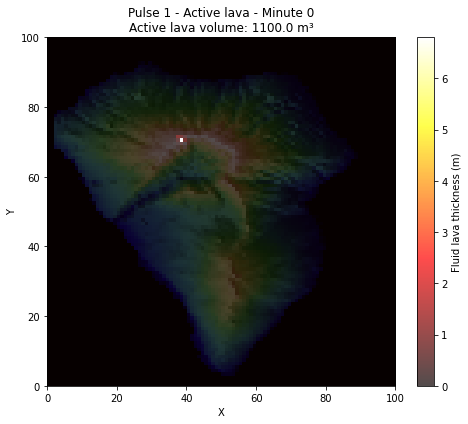

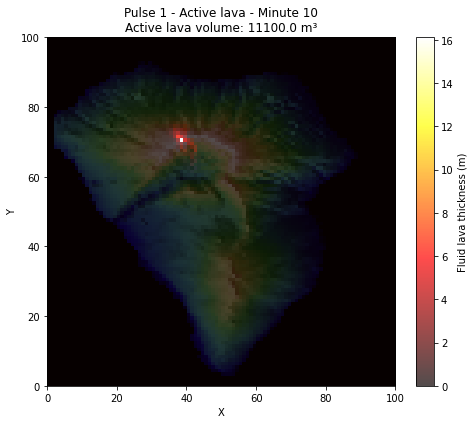

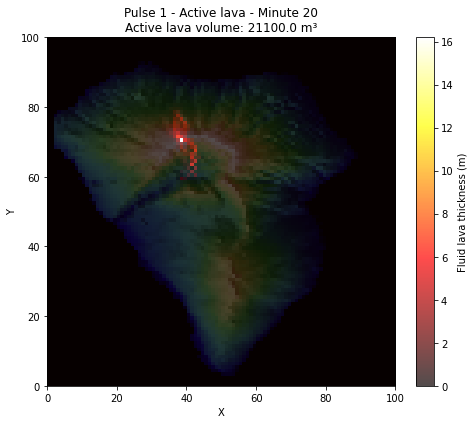

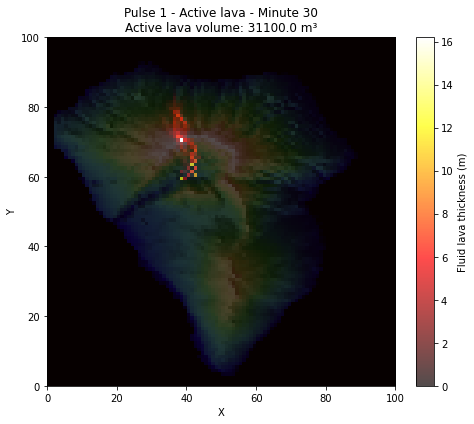

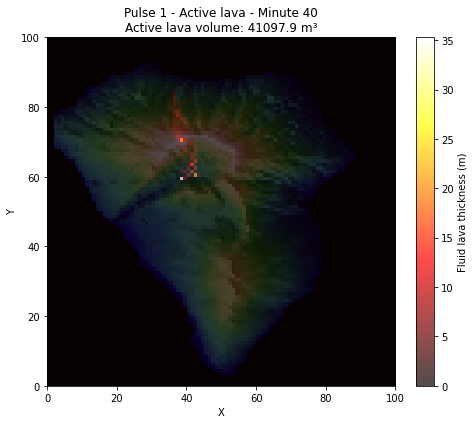

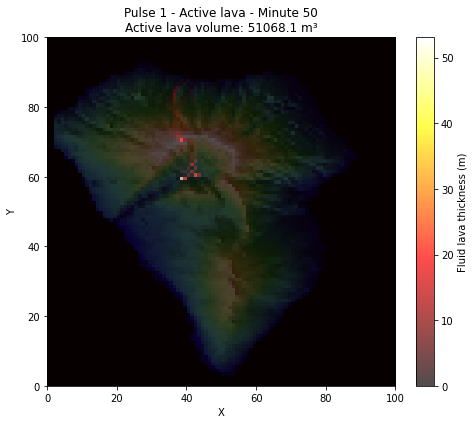

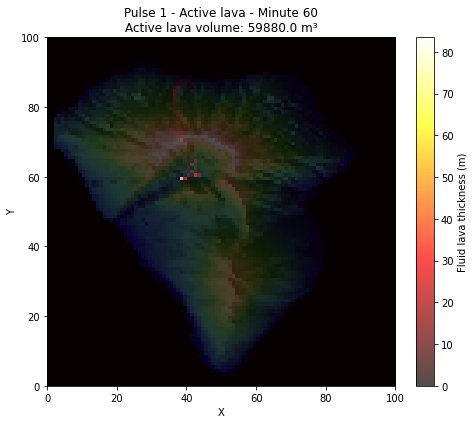

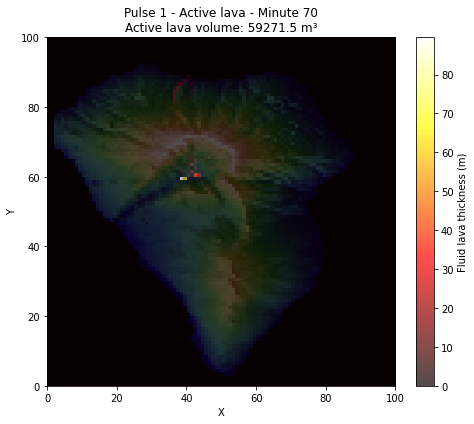

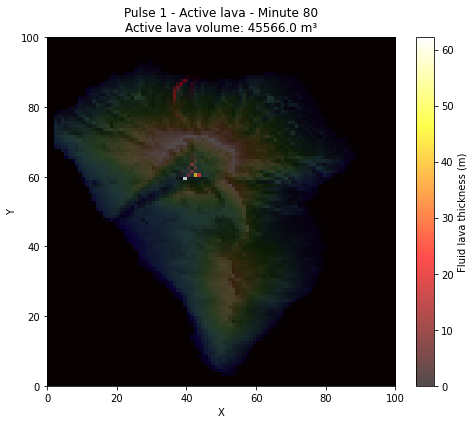

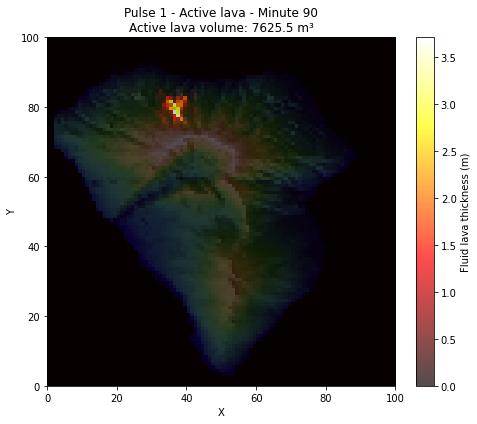


Pulse simulation 1 stopped at minute 96 because the solidified lava volume (60084.3 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 1 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): 15.7 m³
Solidified lava volume: 60084.3 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

=== Volcanic pulse simulation 2 ===


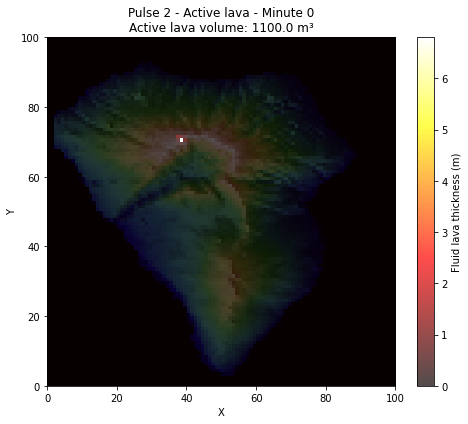

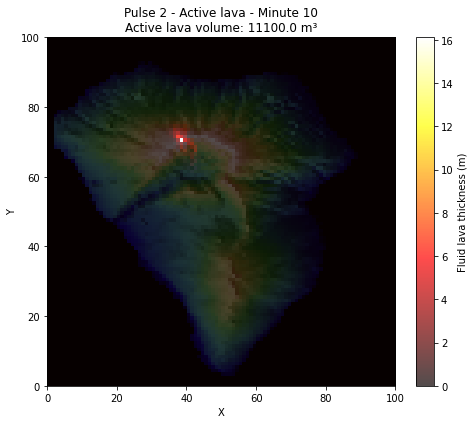

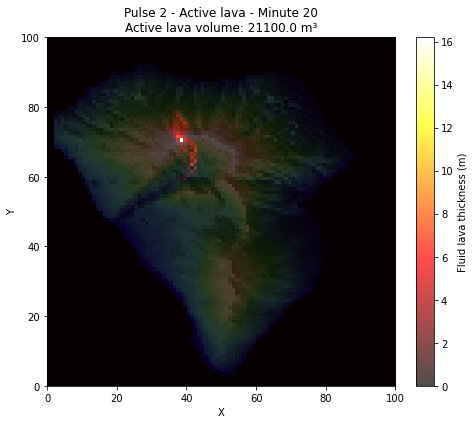

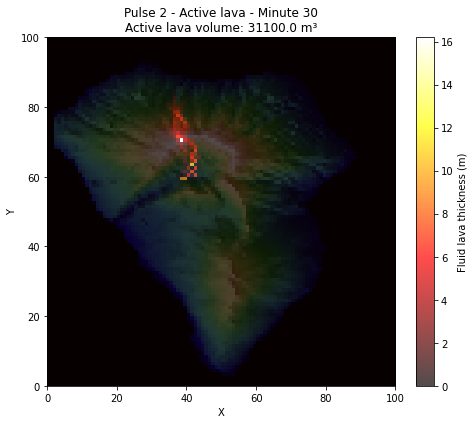

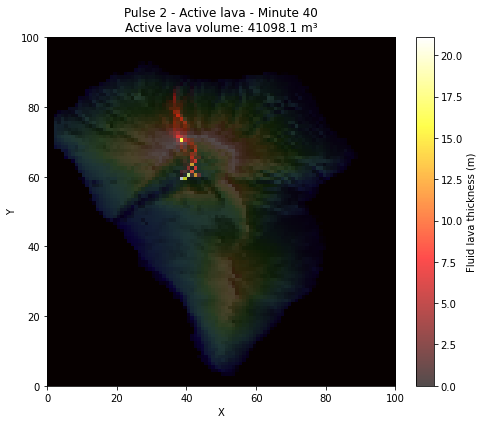

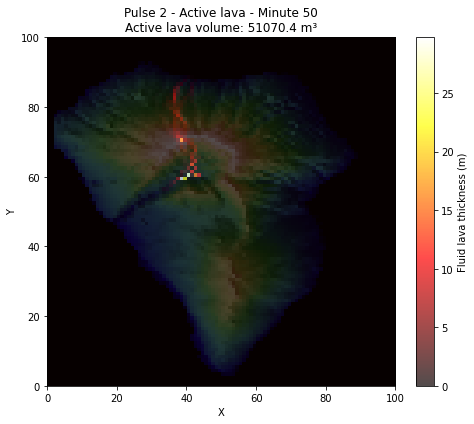

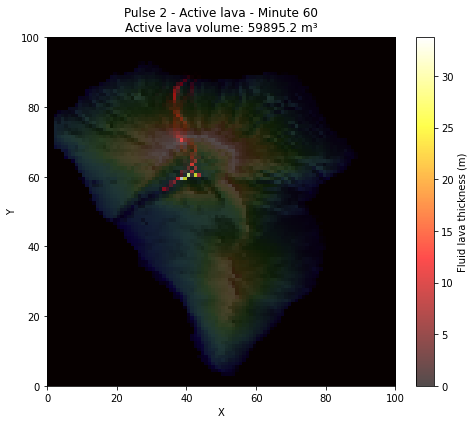

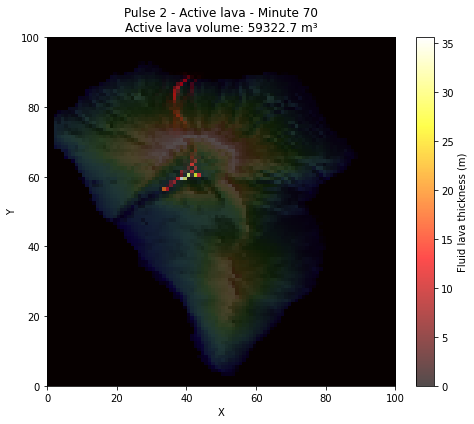

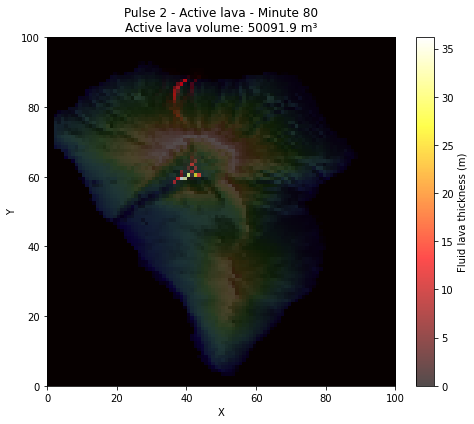

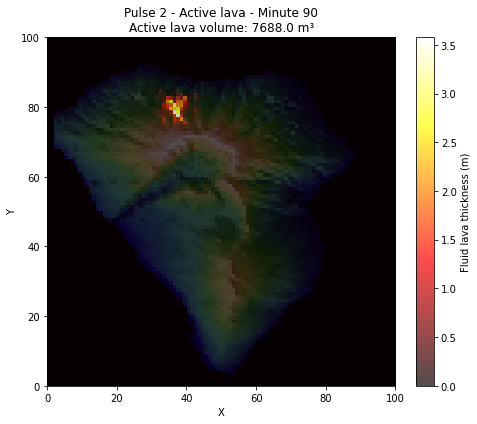


Pulse simulation 2 stopped at minute 96 because the solidified lava volume (60084.3 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 2 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): 15.7 m³
Solidified lava volume: 60084.3 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

=== Volcanic pulse simulation 3 ===


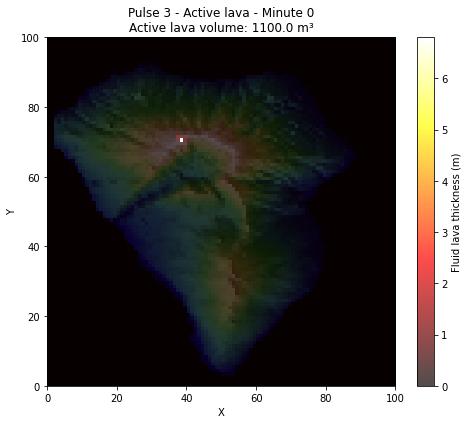

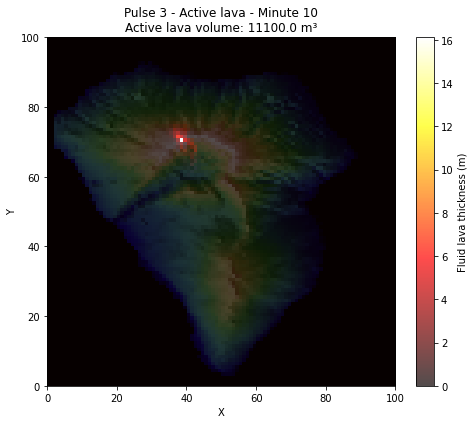

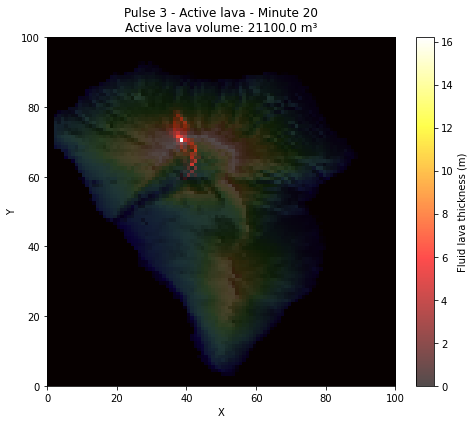

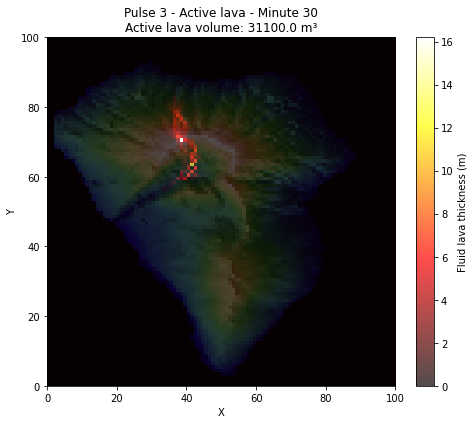

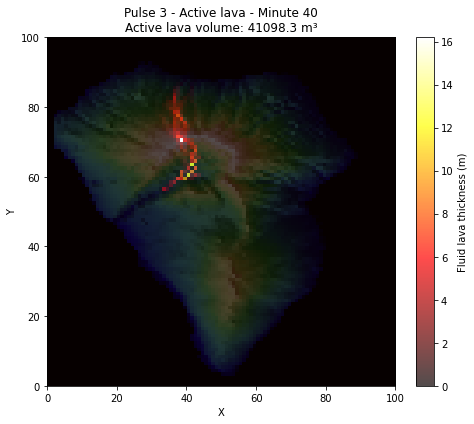

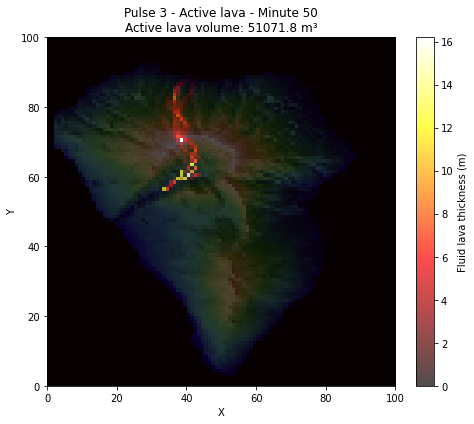

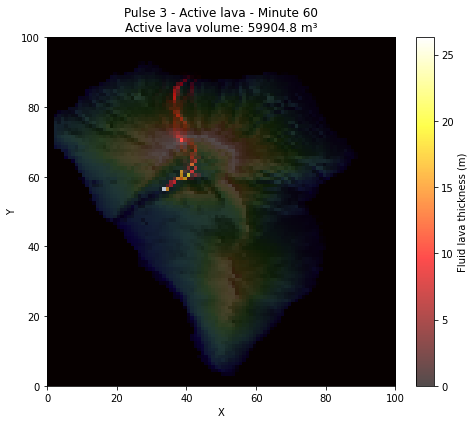

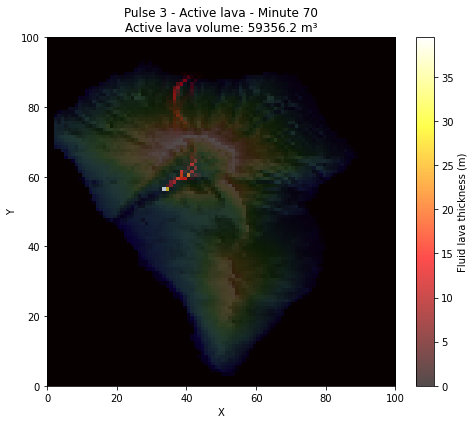

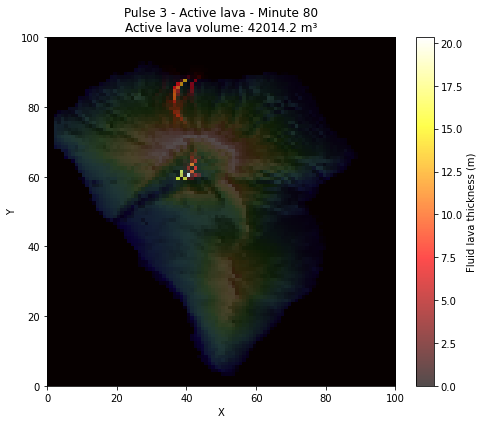

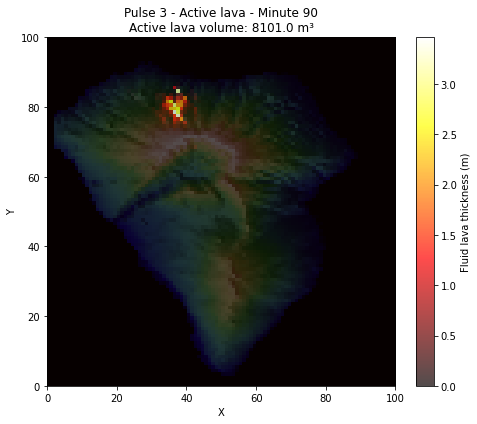


Pulse simulation 3 stopped at minute 96 because the solidified lava volume (60084.3 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 3 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): 15.7 m³
Solidified lava volume: 60084.3 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³


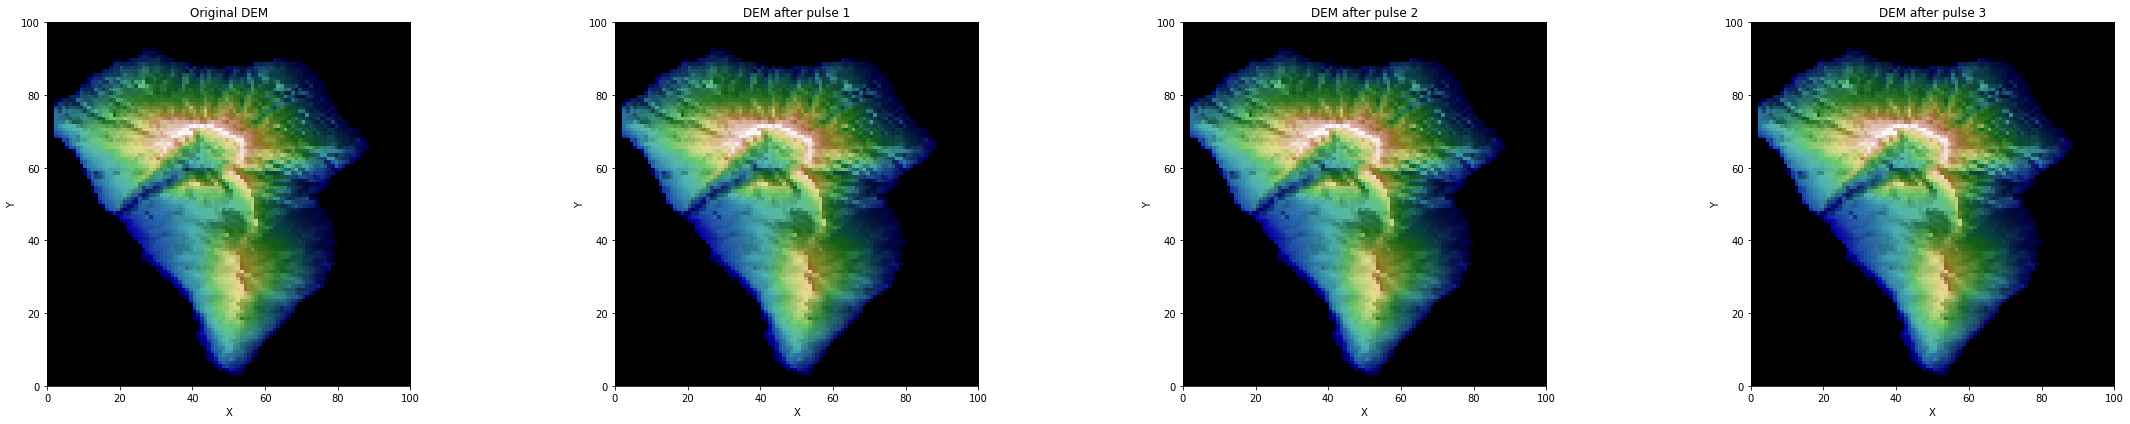


--- DEM statistics after pulse 1 ---
Min: 0.00 m
Max: 2370.00 m
Mean: 391.06 m
Standard deviation: 557.12 m

--- DEM statistics after pulse 2 ---
Min: 0.00 m
Max: 2370.00 m
Mean: 391.12 m
Standard deviation: 557.14 m

--- DEM statistics after pulse 3 ---
Min: 0.00 m
Max: 2370.00 m
Mean: 391.18 m
Standard deviation: 557.16 m


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
import rasterio
from scipy.ndimage import zoom

# Adjusted simulation constants
n = 100  # Grid size n x n
cell_area = 100  # Area of each cell (10m x 10m)
T_amb = 300  # Ambient temperature (K) - 27°C
k = 0.009  # Adjusted cooling rate
R = 8.314  # Universal ideal gas constant (J/(mol·K))
E = 30000  # Activation energy (J/mol)
eta_0 = 3e5  # Pre-exponential factor (Pa·s)
dt = 1  # 1 minute per step
emission_rate = 1000  # Flow rate of 100 m³/min
emission_duration = 60  # Emission duration in minutes
T_solidify = 1000  # Solidification temperature (K) - 727°C
epsilon = 1e-6  # Threshold to ignore small amounts of lava

# Number of volcanic pulses
num_pulses = 3 

# Functions
def viscosity(T):
    return eta_0 * np.exp(E / (R * T))

def cool_down(T):
    return T - k * (T - T_amb) * dt

def get_neighborhood(grid, x, y):
    neighbors = []
    for dx in [-1, 0, 1]:
        for dy in [-1, 0, 1]:
            nx, ny = x + dx, y + dy
            if (dx != 0 or dy != 0) and 0 <= nx < n and 0 <= ny < n:
                neighbors.append((nx, ny))
    return neighbors

def load_real_dem(path, target_size):
    """Load the real DEM from a GeoTIFF file, resize it, and fix negative values."""
    with rasterio.open(path) as dataset:
        dem = dataset.read(1)  # Read the first band
        dem = np.nan_to_num(dem)  # Replace NaN values with zeros
        zoom_factor = (target_size / dem.shape[0], target_size / dem.shape[1])
        dem_resized = zoom(dem, zoom_factor)  # Resize to the target size
        
        # Filter negative values by setting them to 0 (sea level or solid ground)
        dem_resized[dem_resized < 0] = 0
        
        return dem_resized

def transition_function(x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment, x_max, y_max):
    T = temp_grid[x, y]
    eta = viscosity(T)
    prob_flow = np.exp(-eta / 5e6)

    # Process only if there is a significant amount of lava
    if grid[x, y] > epsilon or (add_lava and x == x_max and y == y_max):
        # Cooling of the lava in the cell
        temp_grid[x, y] = cool_down(T)

        # Check solidification
        if grid[x, y] > epsilon and temp_grid[x, y] <= T_solidify:
            # Move lava from fluid to solid
            solid_grid[x, y] += grid[x, y]  # Add solidified lava to solid_grid
            grid[x, y] = 0  # No fluid lava remains in this cell
            temp_grid[x, y] = T_solidify  # Solid lava temperature is kept at T_solidify
            return grid, temp_grid, solid_grid

        # If new lava is added, add it to the emission point
        if add_lava and x == x_max and y == y_max:
            grid[x, y] += lava_increment
            temp_grid[x, y] = 1300  # Reset initial lava temperature

        # Compute flow to neighbors based on slope
        neighbors = get_neighborhood(grid, x, y)
        flow_potentials = []
        total_potential = 0
        for nx, ny in neighbors:
            # Height difference (considering DEM, fluid lava, and solidified lava)
            height_diff = (dem[x, y] + grid[x, y] + solid_grid[x, y]) - \
                          (dem[nx, ny] + grid[nx, ny] + solid_grid[nx, ny])
            # Lava flows downhill
            if height_diff > 0:
                flow_potentials.append((nx, ny, height_diff))
                total_potential += height_diff
        # Distribute lava to neighbors
        if total_potential > 0:
            lava_to_distribute = grid[x, y] * prob_flow
            lava_to_distribute = min(lava_to_distribute, grid[x, y])  # Do not distribute more than exists
            for nx, ny, potential in flow_potentials:
                flow_fraction = potential / total_potential
                lava_flow = lava_to_distribute * flow_fraction
                if lava_flow > epsilon:
                    grid[nx, ny] += lava_flow
                    grid[x, y] -= lava_flow
                    temp_grid[nx, ny] = temp_grid[x, y]  # Lava temperature remains the same
    return grid, temp_grid, solid_grid

def run_simulation(dem_input, pulse_number):
    # Initialization
    dem = dem_input.copy()
    grid = np.zeros((n, n))  # Fluid lava
    solid_grid = np.zeros((n, n))  # Solidified lava
    temp_grid = np.full((n, n), T_amb)
    
    # Find the highest point in the DEM
    x_max, y_max = np.unravel_index(np.argmax(dem), dem.shape)
    
    # Initial lava at the emission point
    grid[x_max, y_max] = 1  # Initial lava at the emission point
    temp_grid[x_max, y_max] = 1300  # Initial lava temperature

    # Simulation
    steps = 120
    total_emitted_volume = 0
    lava_increment = emission_rate / cell_area  # Lava volume added to the emission point per step

    for step in range(steps):
        add_lava = step < emission_duration
        for x in range(n):
            for y in range(n):
                grid, temp_grid, solid_grid = transition_function(
                    x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment, x_max, y_max)
        if add_lava:
            total_emitted_volume += emission_rate

        # Compute active and solidified lava volumes
        active_lava_volume = np.sum(grid) * cell_area  # Active (fluid) lava in m³
        solid_lava_volume = np.sum(solid_grid) * cell_area  # Solidified lava in m³
        total_lava_volume = active_lava_volume + solid_lava_volume

        # Check that the total lava volume matches the emitted volume
        volume_difference = total_emitted_volume - total_lava_volume

        # Add stopping condition
        if solid_lava_volume >= total_emitted_volume:
            print(f'\nPulse simulation {pulse_number} stopped at minute {step} because the solidified lava volume ({solid_lava_volume:.1f} m³) '
                  f'is equal to or exceeds the total emitted volume ({total_emitted_volume:.1f} m³).')
            break

        if step % 10 == 0:  # Plot every 10 minutes
            fig, ax1 = plt.subplots(figsize=(8, 6))

            # Create improved hillshade
            ls = LightSource(azdeg=225, altdeg=45)  # Adjusted light angle
            hillshade = ls.shade(dem, cmap=plt.cm.gist_earth, vert_exag=2, blend_mode='soft')  # Improved vertical exaggeration and color

            # Show hillshade
            ax1.imshow(hillshade, extent=[0, n, 0, n], cmap='gray')

            # Overlay active lava
            im2 = ax1.imshow(grid, cmap='hot', alpha=0.7, extent=[0, n, 0, n])

            ax1.set_title(f'Pulse {pulse_number} - Active lava - Minute {step}\nActive lava volume: {active_lava_volume:.1f} m³')
            ax1.set_xlabel('X')
            ax1.set_ylabel('Y')
            cbar1 = fig.colorbar(im2, ax=ax1, fraction=0.046, pad=0.04)
            cbar1.set_label('Fluid lava thickness (m)')

            plt.tight_layout()
            plt.show()

    # Final results of the pulse
    print(f'\n--- Final results of Pulse {pulse_number} ---')
    print(f'Total emitted volume: {total_emitted_volume:.1f} m³')
    print(f'Active lava volume (fluid): {active_lava_volume:.1f} m³')
    print(f'Solidified lava volume: {solid_lava_volume:.1f} m³')
    print(f'Total lava volume (active + solid): {total_lava_volume:.1f} m³')
    print(f'Volume difference (emitted - total): {volume_difference:.1f} m³')

    # Compute final DEM by adding solidified lava to the input DEM
    dem_final = dem + solid_grid

    return dem_final

# Load and resize the real DEM
path = '../data/DEM_LaPalma.tif'
dem_real = load_real_dem(path, n)

# Run multiple volcanic pulses
dem_list = [dem_real]  # List to store DEMs after each pulse

for pulse in range(1, num_pulses + 1):
    print(f"\n=== Volcanic pulse simulation {pulse} ===")
    dem_new = run_simulation(dem_list[-1], pulse_number=pulse)
    dem_list.append(dem_new)

# Compare original and final DEMs
# Create a figure with subplots for each DEM
num_dems = len(dem_list)
fig, axes = plt.subplots(1, num_dems, figsize=(8 * num_dems, 6))

for i, ax in enumerate(axes):
    ls = LightSource(azdeg=225, altdeg=45)  # Adjust light angle
    hillshade = ls.shade(dem_list[i], cmap=plt.cm.gist_earth, vert_exag=2, blend_mode='soft')  # Improved vertical exaggeration
    ax.imshow(hillshade, extent=[0, n, 0, n])
    if i == 0:
        ax.set_title('Original DEM')
    else:
        ax.set_title(f'DEM after pulse {i}')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')

plt.tight_layout()
plt.show()

# Statistics for output DEMs across different pulses
for i, dem in enumerate(dem_list[1:]):
    print(f"\n--- DEM statistics after pulse {i + 1} ---")
    print(f"Min: {np.min(dem):.2f} m")
    print(f"Max: {np.max(dem):.2f} m")
    print(f"Mean: {np.mean(dem):.2f} m")
    print(f"Standard deviation: {np.std(dem):.2f} m")


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  # Needed for 3D projections
from scipy.stats import norm  # Import the normal distribution function

# Adjusted simulation constants
n = 100  # Grid size n x n
cell_area = 100  # Area of each cell (10m x 10m)
T_amb = 300  # Ambient temperature (K)
k = 0.009  # Adjusted cooling rate
R = 8.314  # Universal ideal gas constant (J/(mol·K))
E = 30000  # Activation energy (J/mol)
eta_0 = 3e5  # Pre-exponential factor (Pa·s)
dt = 1  # 1 minute per step
emission_rate = 1000  # Flow rate of 100 m³/min
emission_duration = 60  # Emission duration in minutes
T_solidify = 1000  # Solidification temperature (K)
epsilon = 1e-6  # Threshold to ignore small amounts of lava

# Number of volcanic pulses
num_pulses = 3 

# Functions
def viscosity(T):
    return eta_0 * np.exp(E / (R * T))

def cool_down(T):
    return T - k * (T - T_amb) * dt

def get_neighborhood(grid, x, y):
    neighbors = []
    for dx in [-1, 0, 1]:
        for dy in [-1, 0, 1]:
            nx, ny = x + dx, y + dy
            if (dx != 0 or dy != 0) and 0 <= nx < n and 0 <= ny < n:
                neighbors.append((nx, ny))
    return neighbors

def create_pyramidal_dem(size):
    x, y = np.meshgrid(np.linspace(-1, 1, size), np.linspace(-1, 1, size))
    # Parameters for the Gaussian hill
    mean1 = [-0.4, 0]  # Hill center
    std_dev1 = 0.25    # Hill width
    # Parameters for the Gaussian depression
    mean2 = [0.4, 0]   # Depression center
    std_dev2 = 0.25    # Depression width
    # Create the Gaussian hill (positive)
    gaussian1 = norm.pdf(x - mean1[0], scale=std_dev1) * norm.pdf(y - mean1[1], scale=std_dev1)
    # Create the Gaussian depression (negative)
    gaussian2 = -0.2 * norm.pdf(x - mean2[0], scale=std_dev2) * norm.pdf(y - mean2[1], scale=std_dev2)
    # Sum both Gaussians
    bimodal_matrix = gaussian1 + gaussian2
    # Normalize the matrix
    bimodal_matrix /= np.abs(bimodal_matrix).max()  # Normalize between -1 and 1
    # Scale to represent height in meters
    return bimodal_matrix * 100  # Adjust the scale factor depending on desired height

def transition_function(x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment):
    T = temp_grid[x, y]
    eta = viscosity(T)
    prob_flow = np.exp(-eta / 5e6)

    # Process only if there is a significant amount of lava
    if grid[x, y] > epsilon or (add_lava and x == n//2 and y == n//2):
        # Cooling of the lava in the cell
        temp_grid[x, y] = cool_down(T)

        # Check solidification
        if grid[x, y] > epsilon and temp_grid[x, y] <= T_solidify:
            # Move lava from fluid to solid
            solid_grid[x, y] += grid[x, y]  # Add solidified lava to solid_grid
            grid[x, y] = 0  # No fluid lava remains in this cell
            temp_grid[x, y] = T_solidify  # Solid lava temperature is kept at T_solidify
            return grid, temp_grid, solid_grid

        # If new lava is added, add it to the central cell
        if add_lava and x == n//2 and y == n//2:
            grid[x, y] += lava_increment
            temp_grid[x, y] = 1300  # Reset initial lava temperature

        # Compute flow to neighbors based on slope
        neighbors = get_neighborhood(grid, x, y)
        flow_potentials = []
        total_potential = 0
        for nx, ny in neighbors:
            # Height difference (considering DEM and fluid lava)
            height_diff = (dem[x, y] + grid[x, y]) - (dem[nx, ny] + grid[nx, ny])
            # Lava flows downhill
            if height_diff > 0:
                flow_potentials.append((nx, ny, height_diff))
                total_potential += height_diff
        # Distribute lava to neighbors
        if total_potential > 0:
            lava_to_distribute = grid[x, y] * prob_flow
            lava_to_distribute = min(lava_to_distribute, grid[x, y])  # Do not distribute more than exists
            for nx, ny, potential in flow_potentials:
                flow_fraction = potential / total_potential
                lava_flow = lava_to_distribute * flow_fraction
                if lava_flow > epsilon:
                    grid[nx, ny] += lava_flow
                    grid[x, y] -= lava_flow
                    temp_grid[nx, ny] = temp_grid[x, y]  # Lava temperature remains the same
    return grid, temp_grid, solid_grid

def run_simulation(dem_input, pulse_number):
    # Initialization
    dem = dem_input.copy()
    grid = np.zeros((n, n))  # Fluid lava
    solid_grid = np.zeros((n, n))  # Solidified lava
    temp_grid = np.full((n, n), T_amb)
    grid[n//2, n//2] = 1  # Initial lava in the central cell
    temp_grid[n//2, n//2] = 1300  # Initial lava temperature

    # Simulation
    steps = 120
    total_emitted_volume = 0
    lava_increment = emission_rate / cell_area  # Lava volume added to the central cell per step

    frames_data = []  # List to store data for the animation

    for step in range(steps):
        add_lava = step < emission_duration
        for x in range(n):
            for y in range(n):
                grid, temp_grid, solid_grid = transition_function(
                    x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment)
        if add_lava:
            total_emitted_volume += emission_rate

        # Compute active and solidified lava volumes
        active_lava_volume = np.sum(grid) * cell_area  # Active (fluid) lava in m³
        solid_lava_volume = np.sum(solid_grid) * cell_area  # Solidified lava in m³
        total_lava_volume = active_lava_volume + solid_lava_volume

        # Check that the total lava volume matches the emitted volume
        volume_difference = total_emitted_volume - total_lava_volume

        # Store data for animation
        elevation = dem + grid  # DEM elevation + fluid lava
        frames_data.append({
            'elevation': elevation.copy(),
            'lava_active': grid.copy(),
            'time': step,
            'active_lava_volume': active_lava_volume - cell_area,  # Subtract the initial amount
        })

        # Stopping condition
        if solid_lava_volume >= total_emitted_volume:
            print(f'\nPulse simulation {pulse_number} stopped at minute {step} because the solidified lava volume ({solid_lava_volume:.1f} m³) '
                  f'is equal to or exceeds the total emitted volume ({total_emitted_volume:.1f} m³).')
            break

    # Final results of the pulse
    print(f'\n--- Final results of Pulse {pulse_number} ---')
    print(f'Total emitted volume: {total_emitted_volume:.1f} m³')
    print(f'Active lava volume (fluid): {active_lava_volume - cell_area:.1f} m³')
    print(f'Solidified lava volume: {solid_lava_volume:.1f} m³')
    print(f'Total lava volume (active + solid): {total_lava_volume:.1f} m³')
    print(f'Volume difference (emitted - total): {volume_difference:.1f} m³')

    # Create the 3D animation
    create_animation(frames_data, pulse_number, dem)

    # Compute final DEM by adding solidified lava to the input DEM
    dem_final = dem + solid_grid

    return dem_final

def create_animation(frames_data, pulse_number, dem):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    # Create coordinate mesh
    X = np.arange(n)
    Y = np.arange(n)
    X, Y = np.meshgrid(X, Y)

    # Normalize lava data for colors
    max_lava_active = max([frame['lava_active'].max() for frame in frames_data])
    norm = Normalize(vmin=0, vmax=max_lava_active)

    # Create a ScalarMappable for the colorbar
    mappable = plt.cm.ScalarMappable(cmap='hot', norm=norm)
    mappable.set_array([])

    # Add colorbar
    cbar = plt.colorbar(mappable, ax=ax, shrink=0.5, aspect=10, pad=0.1)

    cbar.set_label('Active lava thickness (m)')

    # Update function for each frame
    def update_frame(i):
        ax.clear()
        elevation = frames_data[i]['elevation']
        lava_active = frames_data[i]['lava_active']
        time = frames_data[i]['time']
        active_volume = frames_data[i]['active_lava_volume']

        # Create mask where there is no active lava
        lava_mask = lava_active > epsilon

        # Create masked arrays
        elevation_masked = np.ma.array(elevation, mask=~lava_mask)
        lava_active_masked = np.ma.array(lava_active, mask=~lava_mask)

        # Plot terrain (DEM without solidified lava)
        ax.plot_surface(X, Y, dem, cmap='terrain', linewidth=0,
                        antialiased=False, alpha=0.7)

        # Plot active lava over the DEM with transparency
        if np.any(lava_mask):
            ax.plot_surface(X, Y, elevation_masked,
                            facecolors=plt.cm.hot(norm(lava_active_masked)),
                            linewidth=0, antialiased=False, shade=False,
                            alpha=0.8)  # Adjust alpha for transparency

        # Plot configuration
        ax.set_title(f'Pulse {pulse_number} - Minute {time}\n'
                     f'Active lava volume: {active_volume:.1f} m³')
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Elevation (m)')
        ax.set_zlim(0, np.max(elevation) * 1.1)
        ax.view_init(elev=45, azim=45)

    ani = animation.FuncAnimation(fig, update_frame,
                                  frames=len(frames_data),
                                  interval=100, blit=False)

    # Save the animation as a GIF
    ani.save(f'pulse_{pulse_number}_animation_bin.gif', writer='pillow')
    print(f'\nPulse animation {pulse_number} saved as '
          f'"pulse_{pulse_number}_animation_bin.gif"')

    plt.close(fig)  # Close the figure to free memory

# Create the pyramidal DEM
dem_original = create_pyramidal_dem(n)

# Run multiple volcanic pulses
dem_list = [dem_original]  # List to store DEMs after each pulse

for pulse in range(1, num_pulses + 1):
    print(f"\n=== Volcanic pulse simulation {pulse} ===")
    dem_new = run_simulation(dem_list[-1], pulse_number=pulse)
    dem_list.append(dem_new)

# Statistics for output DEMs across different pulses
for i, dem in enumerate(dem_list[1:]):
    print(f"\n--- DEM statistics after pulse {i + 1} ---")
    print(f"Min: {np.min(dem):.2f} m")
    print(f"Max: {np.max(dem):.2f} m")
    print(f"Mean: {np.mean(dem):.2f} m")
    print(f"Standard deviation: {np.std(dem):.2f} m")



=== Volcanic pulse simulation 1 ===

Pulse simulation 1 stopped at minute 84 because the solidified lava volume (60079.2 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 1 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): -79.2 m³
Solidified lava volume: 60079.2 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

Pulse animation 1 saved as "pulse_1_animation_bin.gif"

=== Volcanic pulse simulation 2 ===

Pulse simulation 2 stopped at minute 84 because the solidified lava volume (60078.9 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 2 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): -78.9 m³
Solidified lava volume: 60078.9 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

Pulse animation 2 saved as "pulse_2_animation_bin.gif"

=== Volcanic pulse simulation 3 ===

Pulse si


=== Volcanic pulse simulation 1 ===


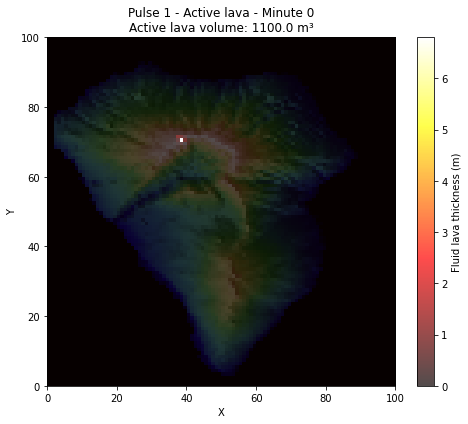

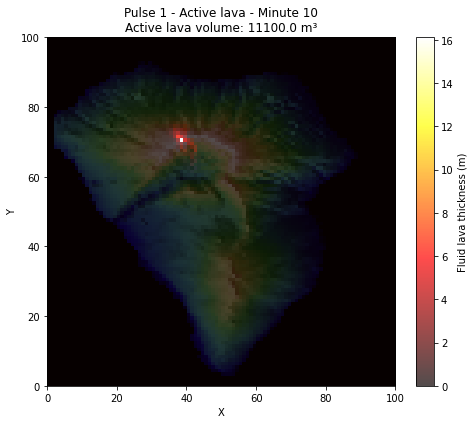

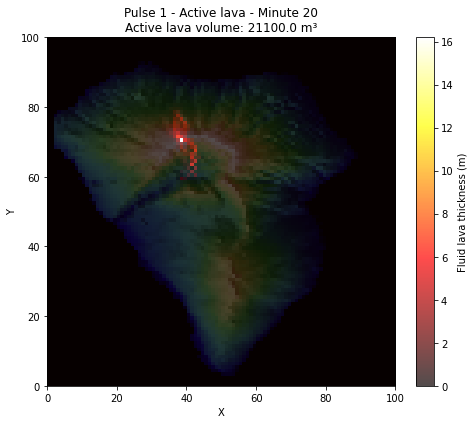

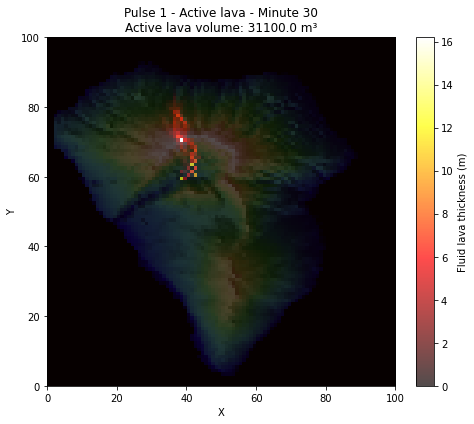

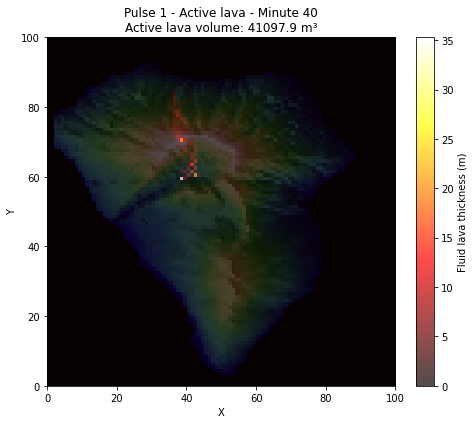

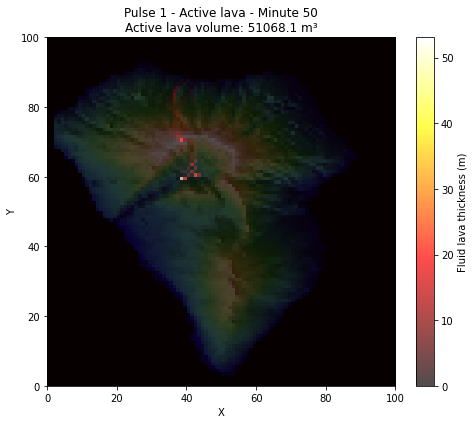

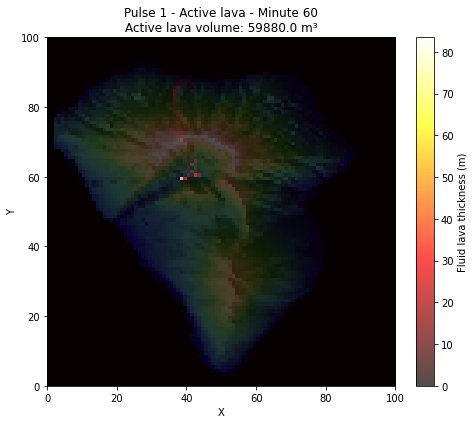

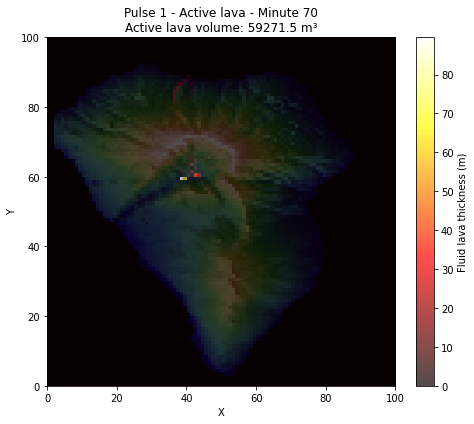

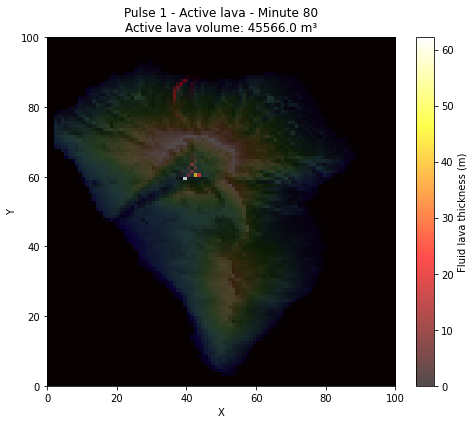

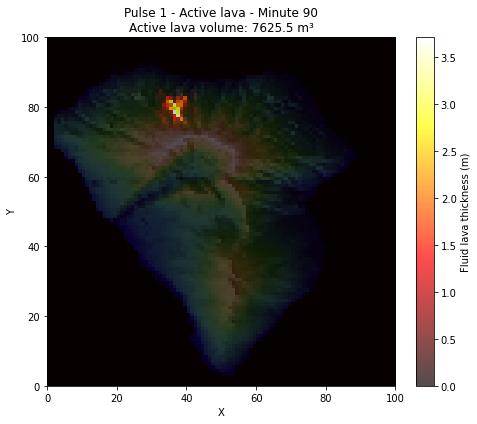


Pulse simulation 1 stopped at minute 96 because the solidified lava volume (60084.3 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 1 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): 15.7 m³
Solidified lava volume: 60084.3 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

=== Volcanic pulse simulation 2 ===


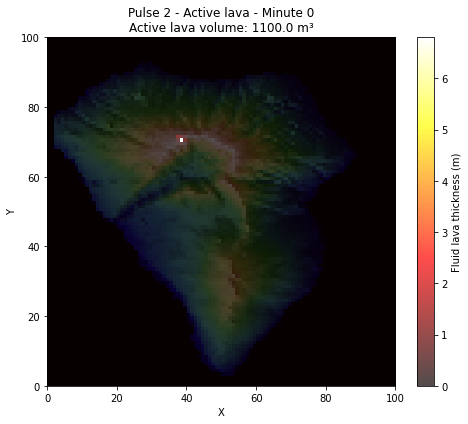

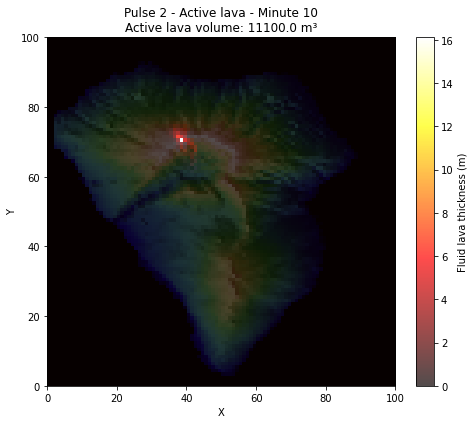

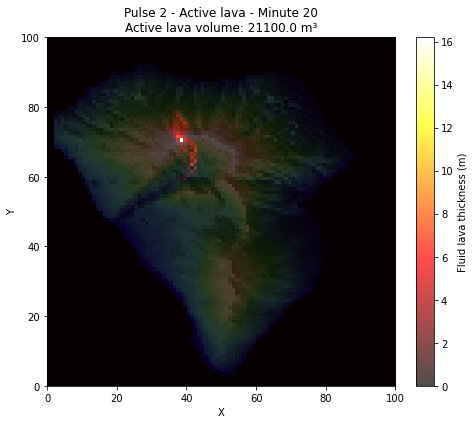

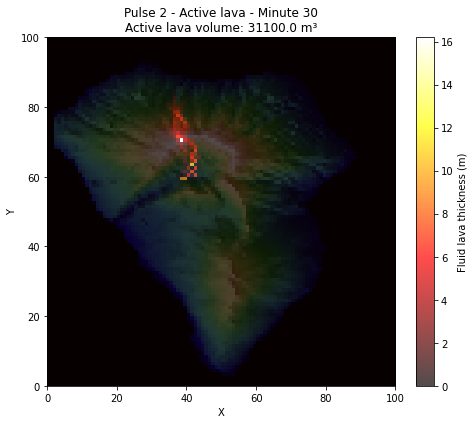

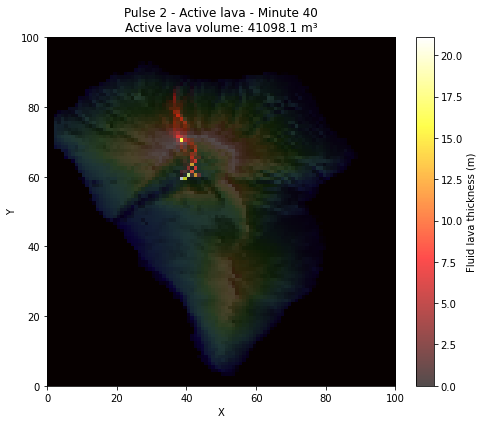

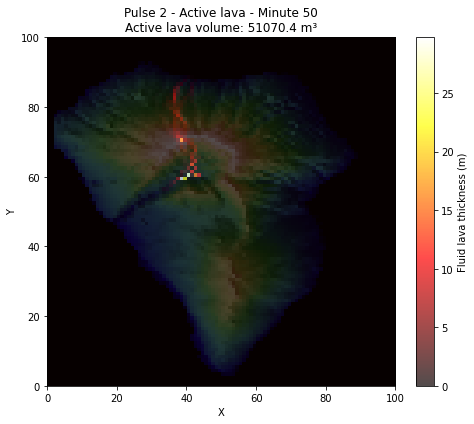

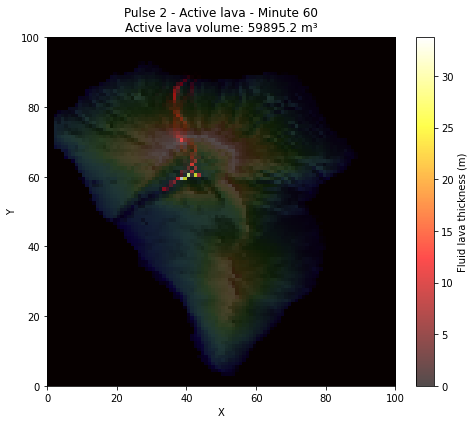

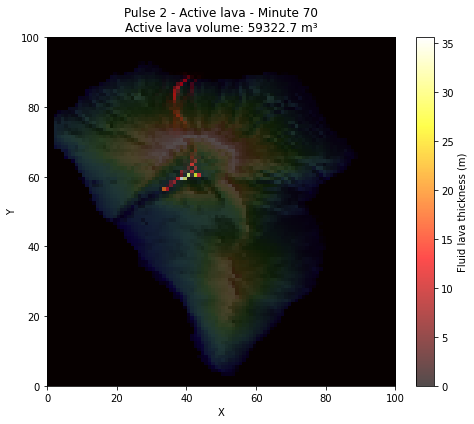

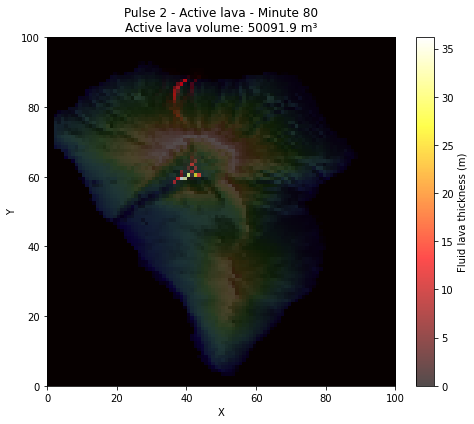

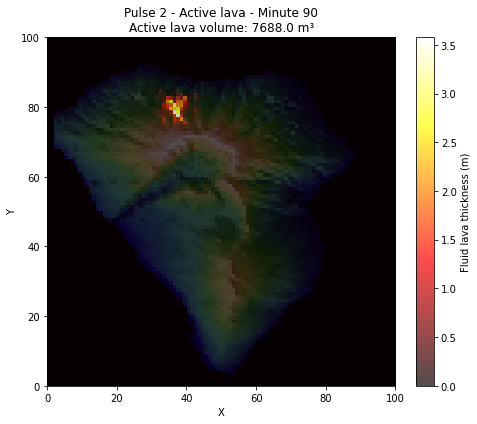


Pulse simulation 2 stopped at minute 96 because the solidified lava volume (60084.3 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 2 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): 15.7 m³
Solidified lava volume: 60084.3 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

=== Volcanic pulse simulation 3 ===


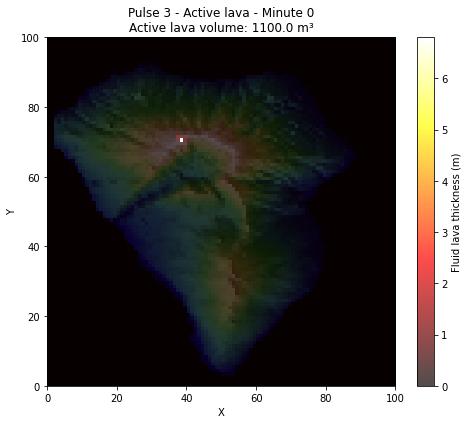

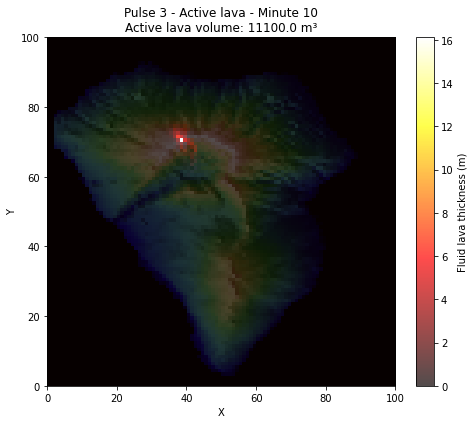

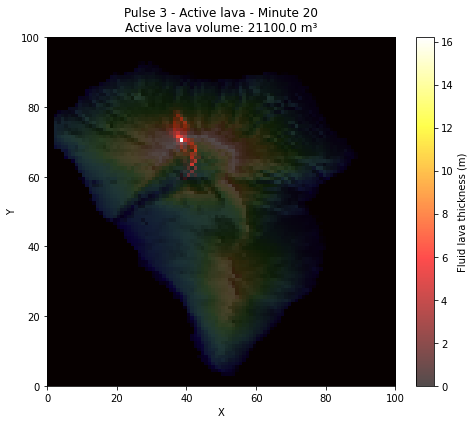

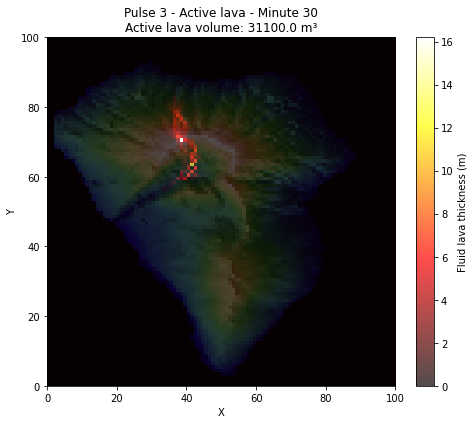

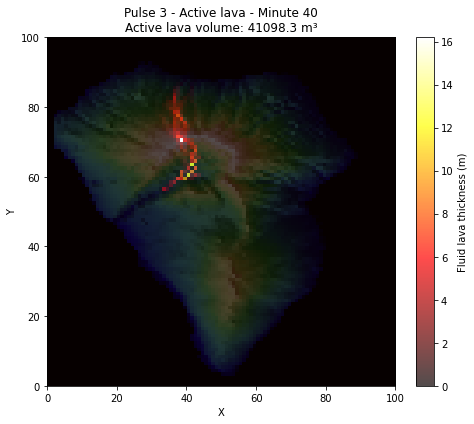

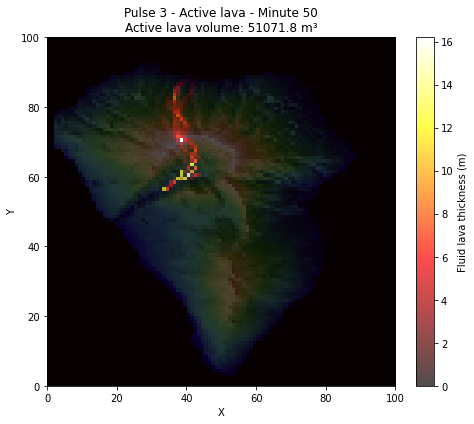

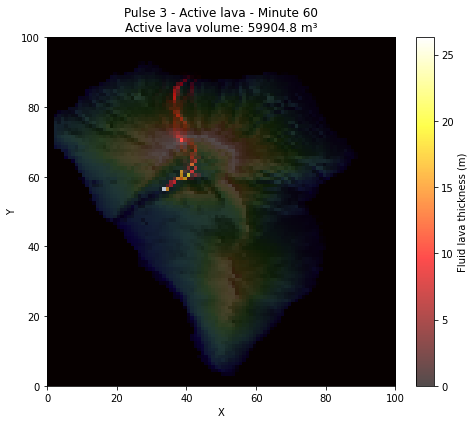

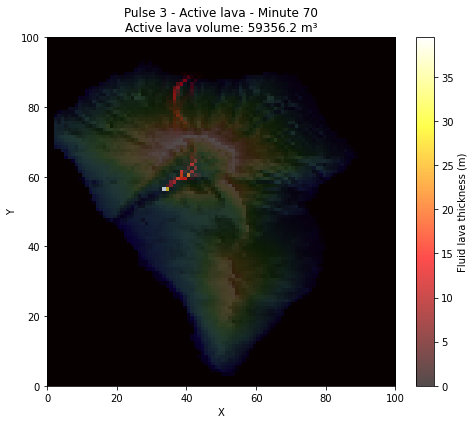

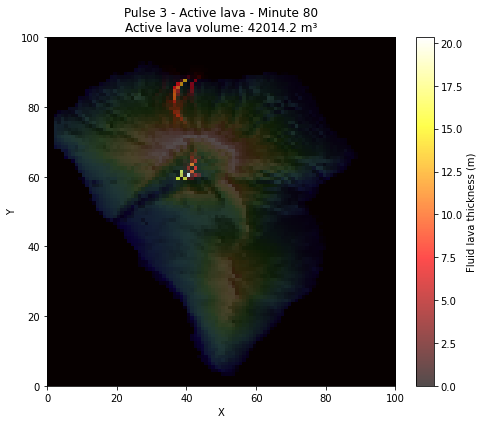

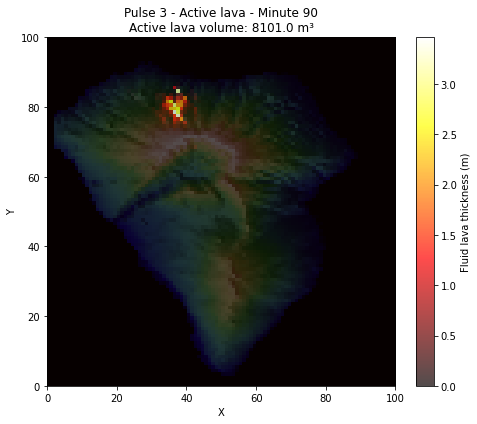


Pulse simulation 3 stopped at minute 96 because the solidified lava volume (60084.3 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 3 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): 15.7 m³
Solidified lava volume: 60084.3 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³


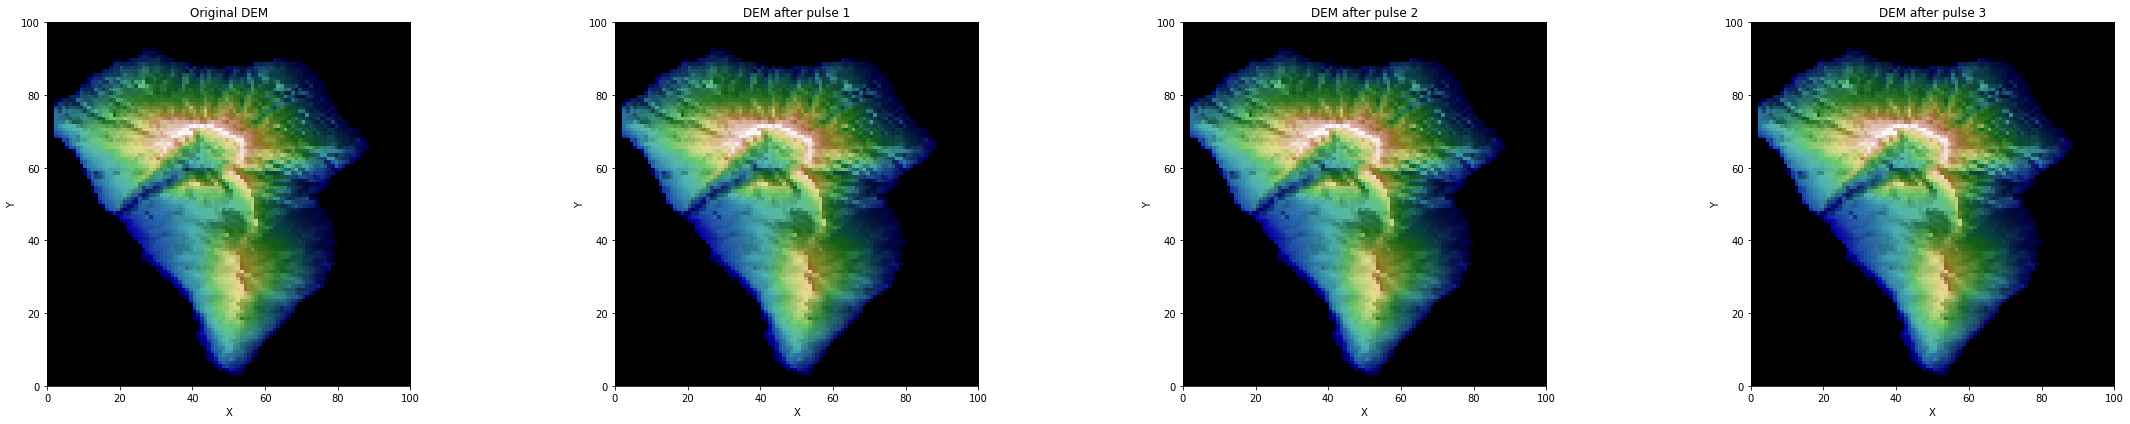


--- DEM statistics after pulse 1 ---
Min: 0.00 m
Max: 2370.00 m
Mean: 391.06 m
Standard deviation: 557.12 m

--- DEM statistics after pulse 2 ---
Min: 0.00 m
Max: 2370.00 m
Mean: 391.12 m
Standard deviation: 557.14 m

--- DEM statistics after pulse 3 ---
Min: 0.00 m
Max: 2370.00 m
Mean: 391.18 m
Standard deviation: 557.16 m


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
import rasterio
from scipy.ndimage import zoom

# Adjusted simulation constants
n = 100  # Grid size n x n
cell_area = 100  # Area of each cell (10m x 10m)
T_amb = 300  # Ambient temperature (K) - 27°C
k = 0.009  # Adjusted cooling rate
R = 8.314  # Universal ideal gas constant (J/(mol·K))
E = 30000  # Activation energy (J/mol)
eta_0 = 3e5  # Pre-exponential factor (Pa·s)
dt = 1  # 1 minute per step
emission_rate = 1000  # Flow rate of 100 m³/min
emission_duration = 60  # Emission duration in minutes
T_solidify = 1000  # Solidification temperature (K) - 727°C
epsilon = 1e-6  # Threshold to ignore small amounts of lava

# Number of volcanic pulses
num_pulses = 3 

# Functions
def viscosity(T):
    return eta_0 * np.exp(E / (R * T))

def cool_down(T):
    return T - k * (T - T_amb) * dt

def get_neighborhood(grid, x, y):
    neighbors = []
    for dx in [-1, 0, 1]:
        for dy in [-1, 0, 1]:
            nx, ny = x + dx, y + dy
            if (dx != 0 or dy != 0) and 0 <= nx < n and 0 <= ny < n:
                neighbors.append((nx, ny))
    return neighbors

def load_real_dem(path, target_size):
    """Load the real DEM from a GeoTIFF file, resize it, and fix negative values."""
    with rasterio.open(path) as dataset:
        dem = dataset.read(1)  # Read the first band
        dem = np.nan_to_num(dem)  # Replace NaN values with zeros
        zoom_factor = (target_size / dem.shape[0], target_size / dem.shape[1])
        dem_resized = zoom(dem, zoom_factor)  # Resize to the target size
        
        # Filter negative values by setting them to 0 (sea level or solid ground)
        dem_resized[dem_resized < 0] = 0
        
        return dem_resized

def transition_function(x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment, x_max, y_max):
    T = temp_grid[x, y]
    eta = viscosity(T)
    prob_flow = np.exp(-eta / 5e6)

    # Process only if there is a significant amount of lava
    if grid[x, y] > epsilon or (add_lava and x == x_max and y == y_max):
        # Cooling of the lava in the cell
        temp_grid[x, y] = cool_down(T)

        # Check solidification
        if grid[x, y] > epsilon and temp_grid[x, y] <= T_solidify:
            # Move lava from fluid to solid
            solid_grid[x, y] += grid[x, y]  # Add solidified lava to solid_grid
            grid[x, y] = 0  # No fluid lava remains in this cell
            temp_grid[x, y] = T_solidify  # Solid lava temperature is kept at T_solidify
            return grid, temp_grid, solid_grid

        # If new lava is added, add it to the emission point
        if add_lava and x == x_max and y == y_max:
            grid[x, y] += lava_increment
            temp_grid[x, y] = 1300  # Reset initial lava temperature

        # Compute flow to neighbors based on slope
        neighbors = get_neighborhood(grid, x, y)
        flow_potentials = []
        total_potential = 0
        for nx, ny in neighbors:
            # Height difference (considering DEM, fluid lava, and solidified lava)
            height_diff = (dem[x, y] + grid[x, y] + solid_grid[x, y]) - \
                          (dem[nx, ny] + grid[nx, ny] + solid_grid[nx, ny])
            # Lava flows downhill
            if height_diff > 0:
                flow_potentials.append((nx, ny, height_diff))
                total_potential += height_diff
        # Distribute lava to neighbors
        if total_potential > 0:
            lava_to_distribute = grid[x, y] * prob_flow
            lava_to_distribute = min(lava_to_distribute, grid[x, y])  # Do not distribute more than exists
            for nx, ny, potential in flow_potentials:
                flow_fraction = potential / total_potential
                lava_flow = lava_to_distribute * flow_fraction
                if lava_flow > epsilon:
                    grid[nx, ny] += lava_flow
                    grid[x, y] -= lava_flow
                    temp_grid[nx, ny] = temp_grid[x, y]  # Lava temperature remains the same
    return grid, temp_grid, solid_grid

def run_simulation(dem_input, pulse_number):
    # Initialization
    dem = dem_input.copy()
    grid = np.zeros((n, n))  # Fluid lava
    solid_grid = np.zeros((n, n))  # Solidified lava
    temp_grid = np.full((n, n), T_amb)
    
    # Find the highest point in the DEM
    x_max, y_max = np.unravel_index(np.argmax(dem), dem.shape)
    
    # Initial lava at the emission point
    grid[x_max, y_max] = 1  # Initial lava at the emission point
    temp_grid[x_max, y_max] = 1300  # Initial lava temperature

    # Simulation
    steps = 120
    total_emitted_volume = 0
    lava_increment = emission_rate / cell_area  # Lava volume added to the emission point per step

    for step in range(steps):
        add_lava = step < emission_duration
        for x in range(n):
            for y in range(n):
                grid, temp_grid, solid_grid = transition_function(
                    x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment, x_max, y_max)
        if add_lava:
            total_emitted_volume += emission_rate

        # Compute active and solidified lava volumes
        active_lava_volume = np.sum(grid) * cell_area  # Active (fluid) lava in m³
        solid_lava_volume = np.sum(solid_grid) * cell_area  # Solidified lava in m³
        total_lava_volume = active_lava_volume + solid_lava_volume

        # Check that the total lava volume matches the emitted volume
        volume_difference = total_emitted_volume - total_lava_volume

        # Add stopping condition
        if solid_lava_volume >= total_emitted_volume:
            print(f'\nPulse simulation {pulse_number} stopped at minute {step} because the solidified lava volume ({solid_lava_volume:.1f} m³) '
                  f'is equal to or exceeds the total emitted volume ({total_emitted_volume:.1f} m³).')
            break

        if step % 10 == 0:  # Plot every 10 minutes
            fig, ax1 = plt.subplots(figsize=(8, 6))

            # Create improved hillshade
            ls = LightSource(azdeg=225, altdeg=45)  # Adjusted light angle
            hillshade = ls.shade(dem, cmap=plt.cm.gist_earth, vert_exag=2, blend_mode='soft')  # Improved vertical exaggeration and color

            # Show hillshade
            ax1.imshow(hillshade, extent=[0, n, 0, n], cmap='gray')

            # Overlay active lava
            im2 = ax1.imshow(grid, cmap='hot', alpha=0.7, extent=[0, n, 0, n])

            ax1.set_title(f'Pulse {pulse_number} - Active lava - Minute {step}\nActive lava volume: {active_lava_volume:.1f} m³')
            ax1.set_xlabel('X')
            ax1.set_ylabel('Y')
            cbar1 = fig.colorbar(im2, ax=ax1, fraction=0.046, pad=0.04)
            cbar1.set_label('Fluid lava thickness (m)')

            plt.tight_layout()
            plt.show()

    # Final results of the pulse
    print(f'\n--- Final results of Pulse {pulse_number} ---')
    print(f'Total emitted volume: {total_emitted_volume:.1f} m³')
    print(f'Active lava volume (fluid): {active_lava_volume:.1f} m³')
    print(f'Solidified lava volume: {solid_lava_volume:.1f} m³')
    print(f'Total lava volume (active + solid): {total_lava_volume:.1f} m³')
    print(f'Volume difference (emitted - total): {volume_difference:.1f} m³')

    # Compute final DEM by adding solidified lava to the input DEM
    dem_final = dem + solid_grid

    return dem_final

# Load and resize the real DEM
path = '../data/DEM_LaPalma.tif'
dem_real = load_real_dem(path, n)

# Run multiple volcanic pulses
dem_list = [dem_real]  # List to store DEMs after each pulse

for pulse in range(1, num_pulses + 1):
    print(f"\n=== Volcanic pulse simulation {pulse} ===")
    dem_new = run_simulation(dem_list[-1], pulse_number=pulse)
    dem_list.append(dem_new)

# Compare original and final DEMs
# Create a figure with subplots for each DEM
num_dems = len(dem_list)
fig, axes = plt.subplots(1, num_dems, figsize=(8 * num_dems, 6))

for i, ax in enumerate(axes):
    ls = LightSource(azdeg=225, altdeg=45)  # Adjust light angle
    hillshade = ls.shade(dem_list[i], cmap=plt.cm.gist_earth, vert_exag=2, blend_mode='soft')  # Improved vertical exaggeration
    ax.imshow(hillshade, extent=[0, n, 0, n])
    if i == 0:
        ax.set_title('Original DEM')
    else:
        ax.set_title(f'DEM after pulse {i}')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')

plt.tight_layout()
plt.show()

# Statistics for output DEMs across different pulses
for i, dem in enumerate(dem_list[1:]):
    print(f"\n--- DEM statistics after pulse {i + 1} ---")
    print(f"Min: {np.min(dem):.2f} m")
    print(f"Max: {np.max(dem):.2f} m")
    print(f"Mean: {np.mean(dem):.2f} m")
    print(f"Standard deviation: {np.std(dem):.2f} m")


/home/rodrigo-chani/anaconda3/envs/PDIS/lib/python3.9/site-packages/pyogrio/geopandas.py:275: UserWarning: More than one layer found in 'Emission_Pt.gpkg': 'emision_pto' (default), '2836460n_1751580w'. Specify layer parameter to avoid this warning.
  result = read_func(



=== Volcanic pulse simulation 1 ===


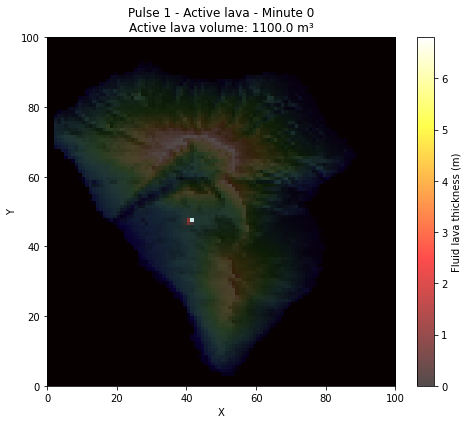

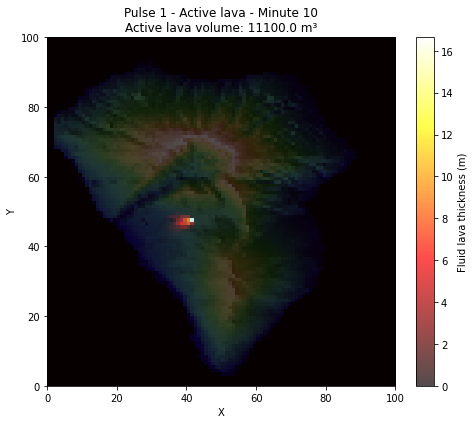

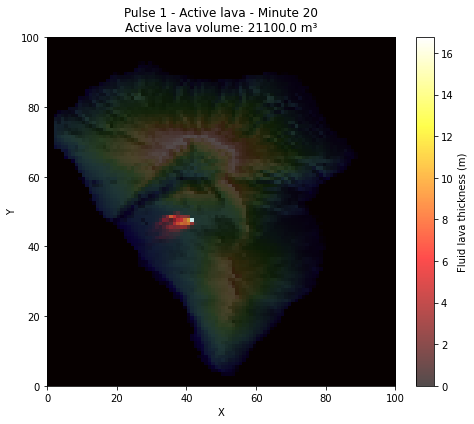

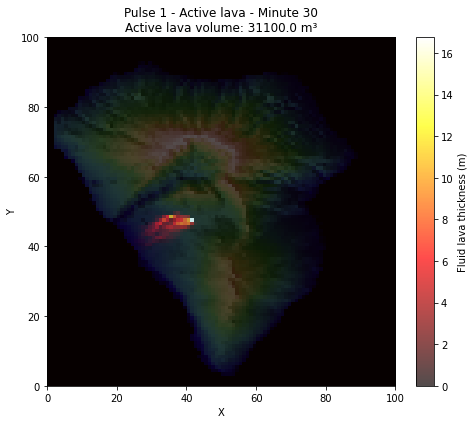

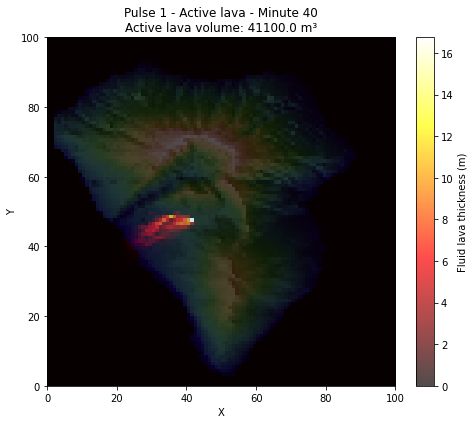

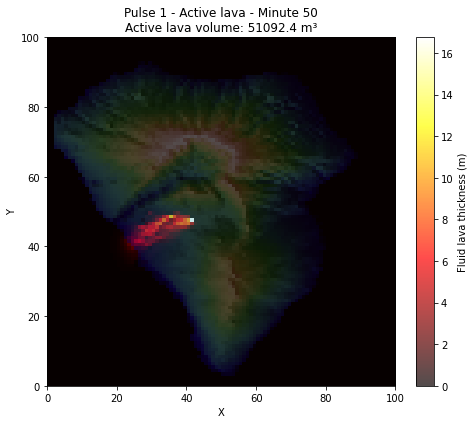

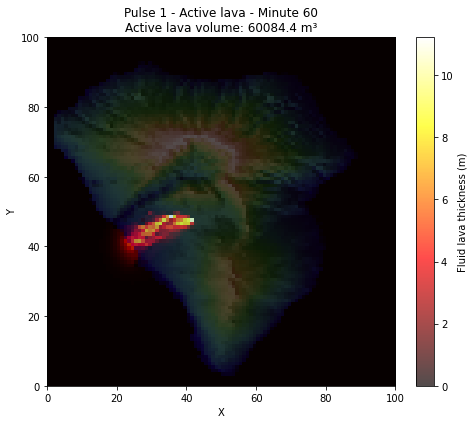

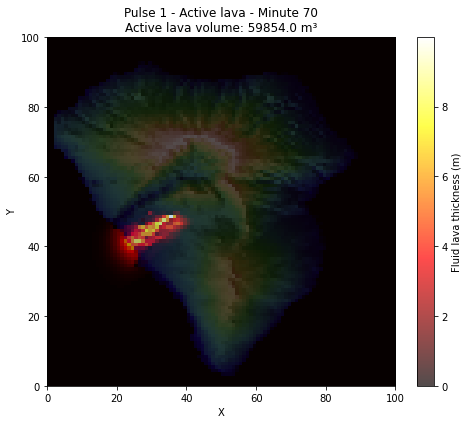

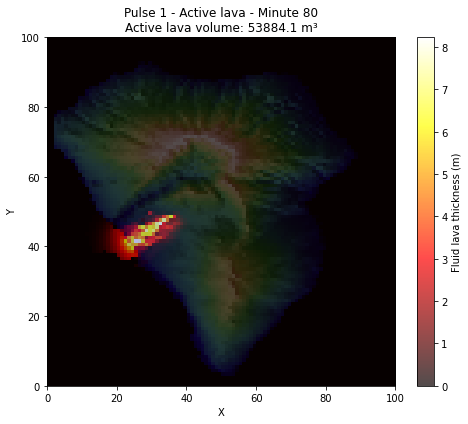

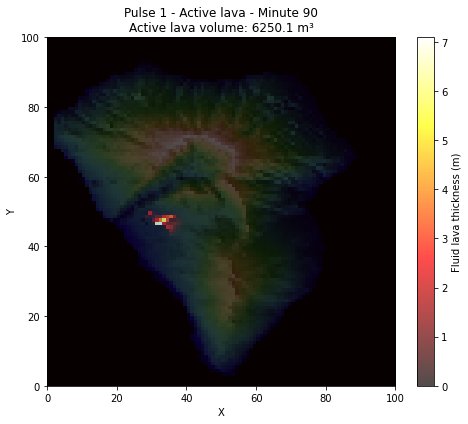


Pulse simulation 1 stopped at minute 94 because the solidified lava volume (60092.8 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 1 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): 7.2 m³
Solidified lava volume: 60092.8 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

=== Volcanic pulse simulation 2 ===


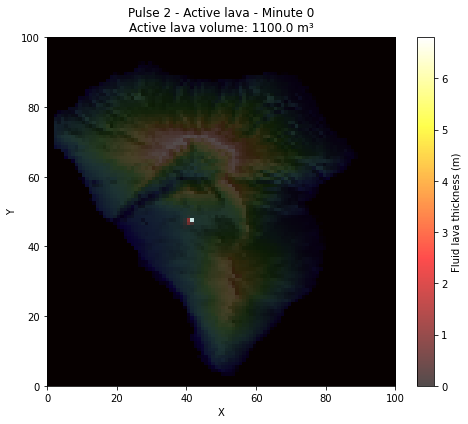

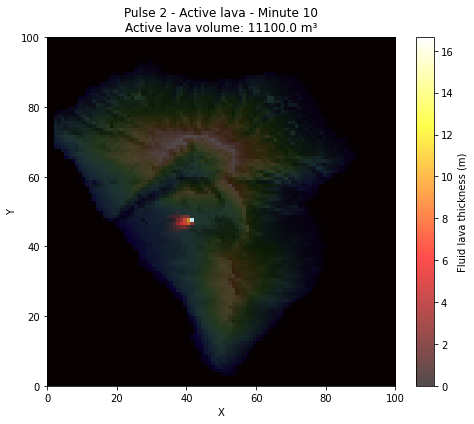

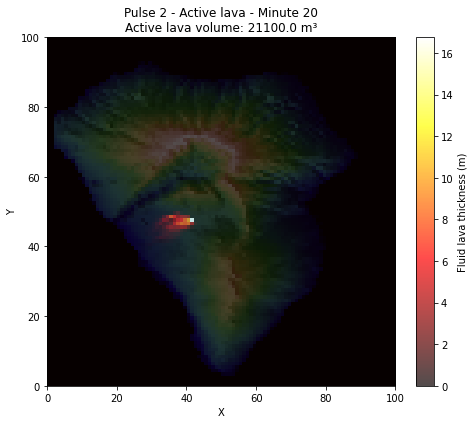

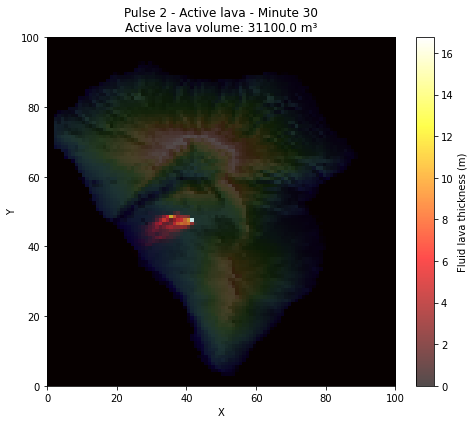

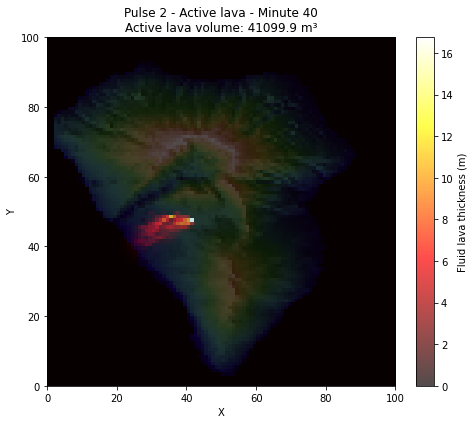

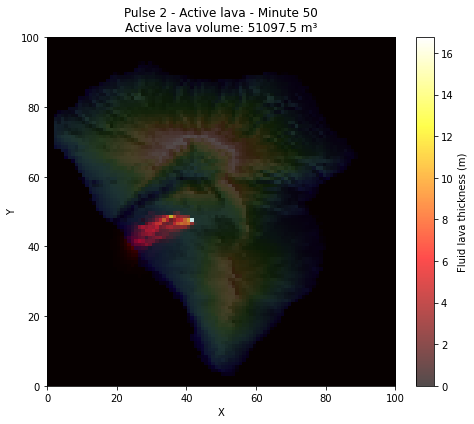

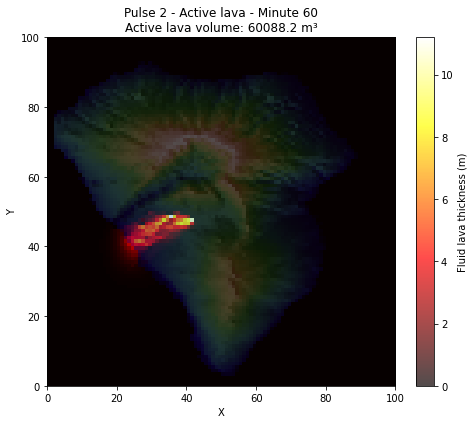

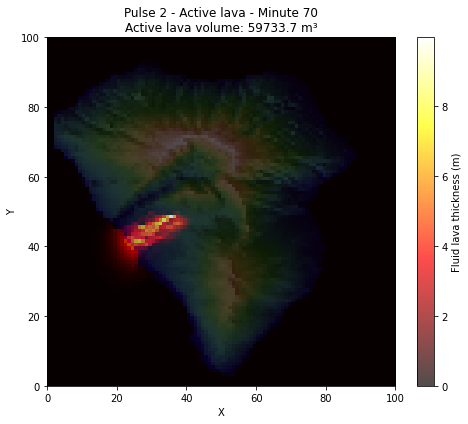

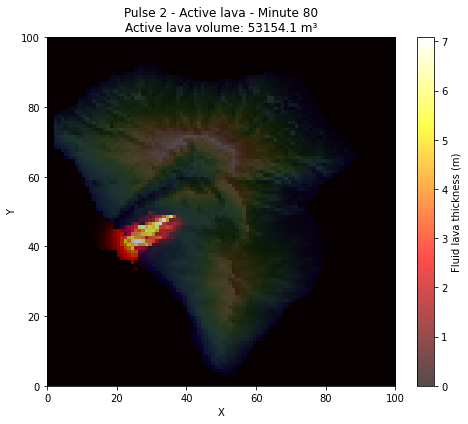

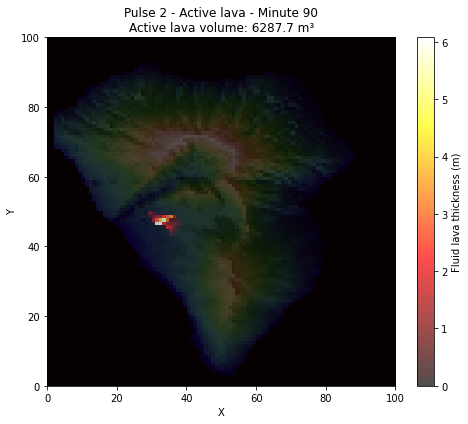


Pulse simulation 2 stopped at minute 94 because the solidified lava volume (60092.8 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 2 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): 7.2 m³
Solidified lava volume: 60092.8 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³

=== Volcanic pulse simulation 3 ===


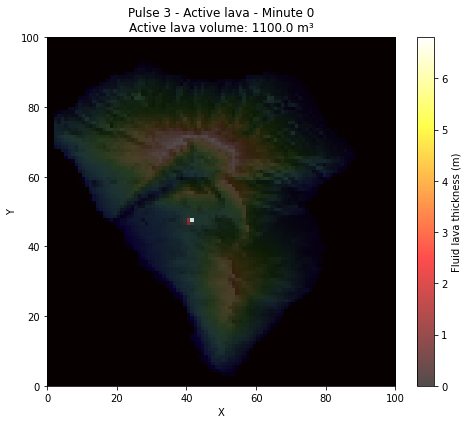

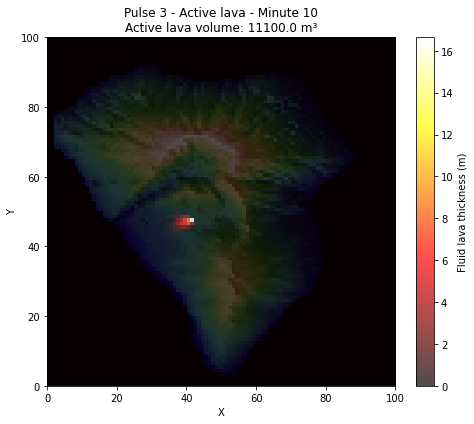

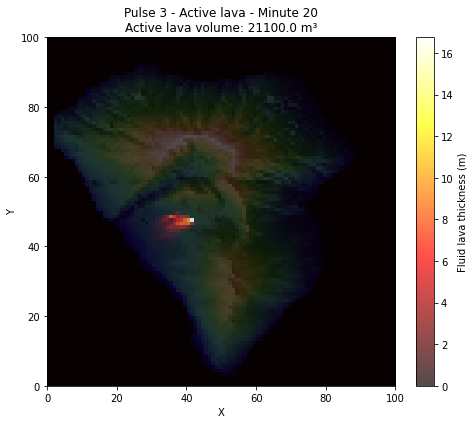

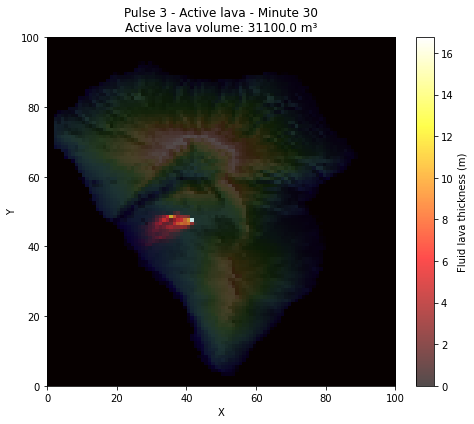

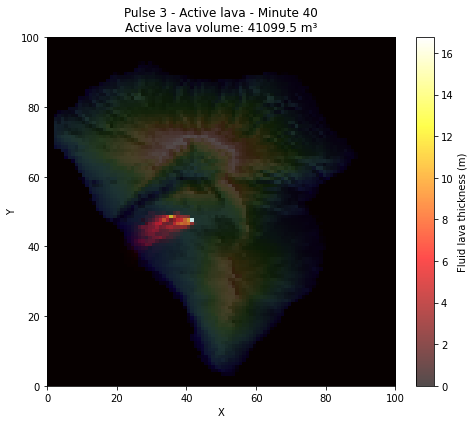

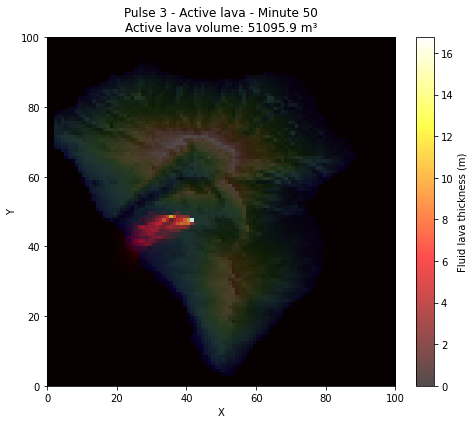

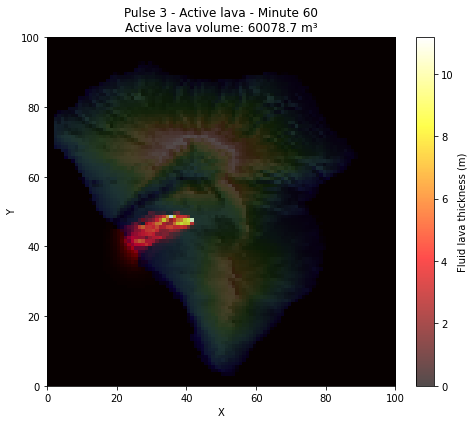

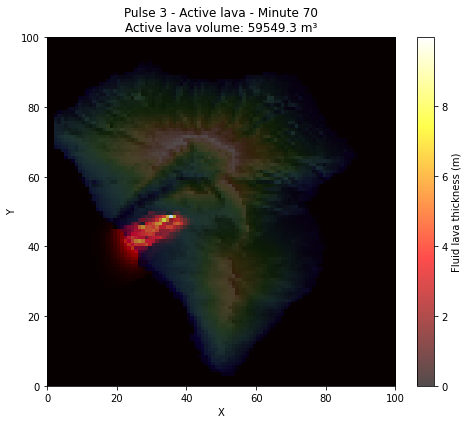

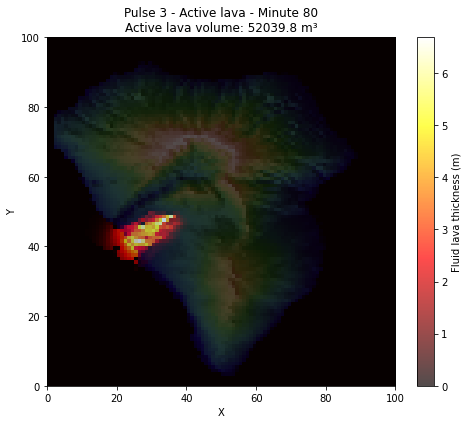

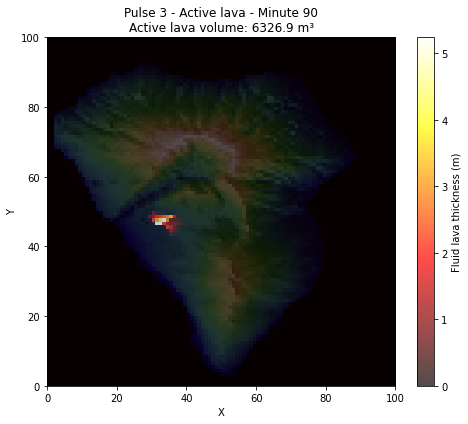


Pulse simulation 3 stopped at minute 94 because the solidified lava volume (60092.8 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

--- Final results of Pulse 3 ---
Total emitted volume: 60000.0 m³
Active lava volume (fluid): 7.2 m³
Solidified lava volume: 60092.8 m³
Total lava volume (active + solid): 60100.0 m³
Volume difference (emitted - total): -100.0 m³


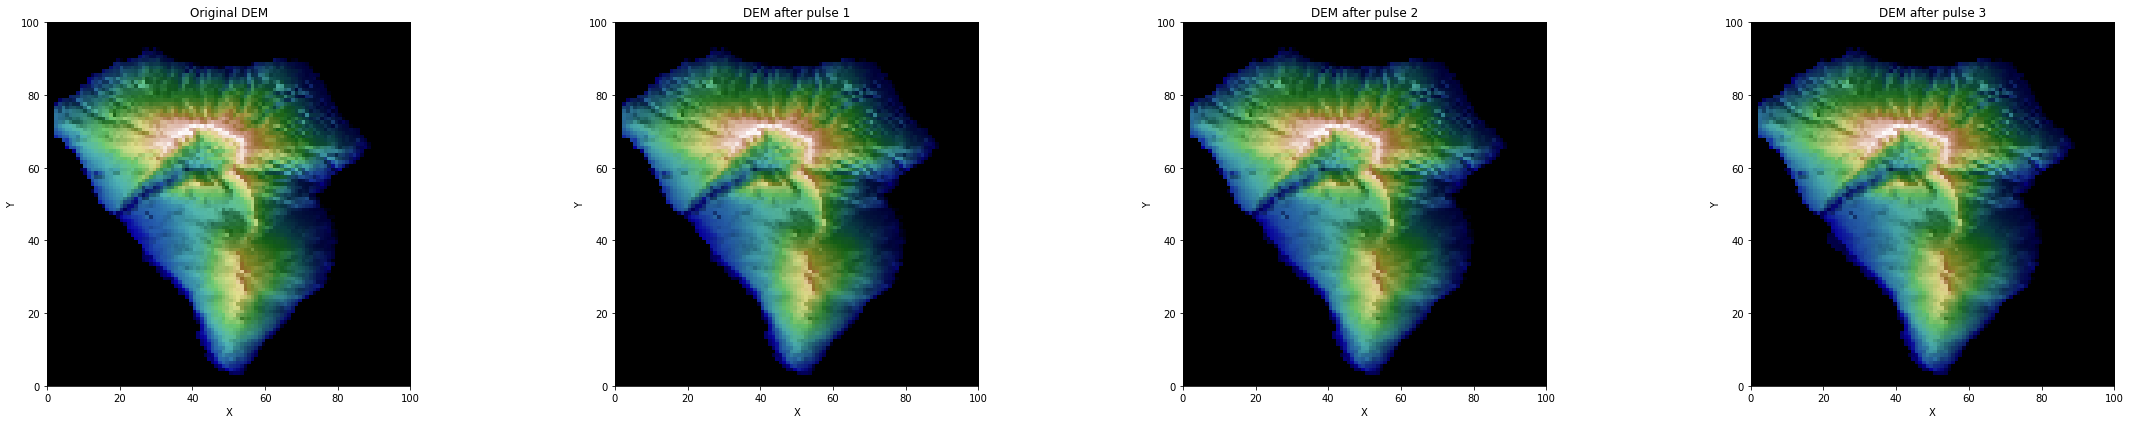


--- DEM statistics after pulse 1 ---
Min: 0.00 m
Max: 2370.00 m
Mean: 391.06 m
Standard deviation: 557.07 m

--- DEM statistics after pulse 2 ---
Min: 0.00 m
Max: 2370.00 m
Mean: 391.12 m
Standard deviation: 557.05 m

--- DEM statistics after pulse 3 ---
Min: 0.00 m
Max: 2370.00 m
Mean: 391.18 m
Standard deviation: 557.02 m


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
import rasterio
from scipy.ndimage import zoom
import geopandas as gpd

# Adjusted simulation constants
n = 100  # Grid size n x n
cell_area = 100  # Area of each cell (10m x 10m)
T_amb = 300  # Ambient temperature (K) - 27°C
k = 0.009  # Adjusted cooling rate
R = 8.314  # Universal ideal gas constant (J/(mol·K))
E = 30000  # Activation energy (J/mol)
eta_0 = 3e5  # Pre-exponential factor (Pa·s)
dt = 1  # 1 minute per step
emission_rate = 1000  # Flow rate of 100 m³/min
emission_duration = 60  # Emission duration in minutes
T_solidify = 1000  # Solidification temperature (K) - 727°C
epsilon = 1e-6  # Threshold to ignore small amounts of lava

# Number of volcanic pulses
num_pulses = 3 

# Functions
def viscosity(T):
    return eta_0 * np.exp(E / (R * T))

def cool_down(T):
    return T - k * (T - T_amb) * dt

def get_neighborhood(grid, x, y):
    neighbors = []
    for dx in [-1, 0, 1]:
        for dy in [-1, 0, 1]:
            nx, ny = x + dx, y + dy
            if (dx != 0 or dy != 0) and 0 <= nx < n and 0 <= ny < n:
                neighbors.append((nx, ny))
    return neighbors

def load_real_dem(path, target_size):
    """Load the real DEM from a GeoTIFF file, resize it, fix negative values, and also return its geographic bounds."""
    with rasterio.open(path) as dataset:
        dem = dataset.read(1)  # Read the first band
        dem = np.nan_to_num(dem, nan=0)  # Replace NaN values with zeros
        zoom_factor = (target_size / dem.shape[0], target_size / dem.shape[1])
        dem_resized = zoom(dem, zoom_factor)  # Resize to the target size
        
        # Filter negative values by setting them to 0 (sea level or solid ground)
        dem_resized[dem_resized < 0] = 0
        
        bounds = dataset.bounds
        
        return dem_resized, (bounds.left, bounds.bottom, bounds.right, bounds.top)

def load_emission_point(path, dem_bounds, grid_size):
    """Load the emission point from a GeoPackage file and transform its coordinates to the index system of the simulation matrix."""
    gdf = gpd.read_file(path)  # Read the GeoPackage file
    point = gdf.geometry[0]  # Assume the file contains at least one point and take the first one
    
    # Extract DEM bounds
    x_min, y_min, x_max, y_max = dem_bounds
    
    # Scale emission point coordinates to the grid size
    x_index = int(grid_size * (point.x - x_min) / (x_max - x_min))
    y_index = int(grid_size * (point.y - y_min) / (y_max - y_min))
    
    return x_index, y_index


def transition_function(x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment, x_max, y_max):
    T = temp_grid[x, y]
    eta = viscosity(T)
    prob_flow = np.exp(-eta / 5e6)

    # Process only if there is a significant amount of lava
    if grid[x, y] > epsilon or (add_lava and x == x_max and y == y_max):
        # Cooling of the lava in the cell
        temp_grid[x, y] = cool_down(T)

        # Check solidification
        if grid[x, y] > epsilon and temp_grid[x, y] <= T_solidify:
            # Move lava from fluid to solid
            solid_grid[x, y] += grid[x, y]  # Add solidified lava to solid_grid
            grid[x, y] = 0  # No fluid lava remains in this cell
            temp_grid[x, y] = T_solidify  # Solid lava temperature is kept at T_solidify
            return grid, temp_grid, solid_grid

        # If new lava is added, add it to the emission point
        if add_lava and x == x_max and y == y_max:
            grid[x, y] += lava_increment
            temp_grid[x, y] = 1300  # Reset initial lava temperature

        # Compute flow to neighbors based on slope
        neighbors = get_neighborhood(grid, x, y)
        flow_potentials = []
        total_potential = 0
        for nx, ny in neighbors:
            # Height difference (considering DEM, fluid lava, and solidified lava)
            height_diff = (dem[x, y] + grid[x, y] + solid_grid[x, y]) - \
                          (dem[nx, ny] + grid[nx, ny] + solid_grid[nx, ny])
            # Lava flows downhill
            if height_diff > 0:
                flow_potentials.append((nx, ny, height_diff))
                total_potential += height_diff
        # Distribute lava to neighbors
        if total_potential > 0:
            lava_to_distribute = grid[x, y] * prob_flow
            lava_to_distribute = min(lava_to_distribute, grid[x, y])  # Do not distribute more than exists
            for nx, ny, potential in flow_potentials:
                flow_fraction = potential / total_potential
                lava_flow = lava_to_distribute * flow_fraction
                if lava_flow > epsilon:
                    grid[nx, ny] += lava_flow
                    grid[x, y] -= lava_flow
                    temp_grid[nx, ny] = temp_grid[x, y]  # Lava temperature remains the same
    return grid, temp_grid, solid_grid

def run_simulation(dem_input, pulse_number, emission_point):
    # Initialization
    dem = dem_input.copy()
    grid = np.zeros((n, n))  # Fluid lava
    solid_grid = np.zeros((n, n))  # Solidified lava
    temp_grid = np.full((n, n), T_amb)
    
    # Use the provided emission point
    x_max, y_max = emission_point
    
    # Initial lava at the emission point
    grid[x_max, y_max] = 1  # Initial lava at the emission point
    temp_grid[x_max, y_max] = 1300  # Initial lava temperature

    # Simulation
    steps = 120
    total_emitted_volume = 0
    lava_increment = emission_rate / cell_area  # Lava volume added to the emission point per step

    for step in range(steps):
        add_lava = step < emission_duration
        for x in range(n):
            for y in range(n):
                grid, temp_grid, solid_grid = transition_function(
                    x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment, x_max, y_max)
        if add_lava:
            total_emitted_volume += emission_rate

        # Compute active and solidified lava volumes
        active_lava_volume = np.sum(grid) * cell_area  # Active (fluid) lava in m³
        solid_lava_volume = np.sum(solid_grid) * cell_area  # Solidified lava in m³
        total_lava_volume = active_lava_volume + solid_lava_volume

        # Check that the total lava volume matches the emitted volume
        volume_difference = total_emitted_volume - total_lava_volume

        # Add stopping condition
        if solid_lava_volume >= total_emitted_volume:
            print(f'\nPulse simulation {pulse_number} stopped at minute {step} because the solidified lava volume ({solid_lava_volume:.1f} m³) '
                  f'is equal to or exceeds the total emitted volume ({total_emitted_volume:.1f} m³).')
            break

        if step % 10 == 0:  # Plot every 10 minutes
            fig, ax1 = plt.subplots(figsize=(8, 6))

            # Create improved hillshade
            ls = LightSource(azdeg=225, altdeg=45)  # Adjusted light angle
            hillshade = ls.shade(dem, cmap=plt.cm.gist_earth, vert_exag=2, blend_mode='soft')  # Improved vertical exaggeration and color

            # Show hillshade
            ax1.imshow(hillshade, extent=[0, n, 0, n], cmap='gray')

            # Overlay active lava
            im2 = ax1.imshow(grid, cmap='hot', alpha=0.7, extent=[0, n, 0, n])

            ax1.set_title(f'Pulse {pulse_number} - Active lava - Minute {step}\nActive lava volume: {active_lava_volume:.1f} m³')
            ax1.set_xlabel('X')
            ax1.set_ylabel('Y')
            cbar1 = fig.colorbar(im2, ax=ax1, fraction=0.046, pad=0.04)
            cbar1.set_label('Fluid lava thickness (m)')

            plt.tight_layout()
            plt.show()

    # Final results of the pulse
    print(f'\n--- Final results of Pulse {pulse_number} ---')
    print(f'Total emitted volume: {total_emitted_volume:.1f} m³')
    print(f'Active lava volume (fluid): {active_lava_volume:.1f} m³')
    print(f'Solidified lava volume: {solid_lava_volume:.1f} m³')
    print(f'Total lava volume (active + solid): {total_lava_volume:.1f} m³')
    print(f'Volume difference (emitted - total): {volume_difference:.1f} m³')

    # Compute final DEM by adding solidified lava to the input DEM
    dem_final = dem + solid_grid

    return dem_final

# Load and resize the real DEM
path_dem = '../data/DEM_LaPalma.tif'
dem_real, dem_bounds = load_real_dem(path_dem, n)

# Load the emission point
emission_point_path = '../data/Emission_Pt.gpkg'
emission_point = load_emission_point(emission_point_path, dem_bounds, n)

# Run multiple volcanic pulses, passing the emission point
dem_list = [dem_real]  # List to store DEMs after each pulse

for pulse in range(1, num_pulses + 1):
    print(f"\n=== Volcanic pulse simulation {pulse} ===")
    dem_new = run_simulation(dem_list[-1], pulse_number=pulse, emission_point=emission_point)
    dem_list.append(dem_new)

# Compare original and final DEMs
# Create a figure with subplots for each DEM
num_dems = len(dem_list)
fig, axes = plt.subplots(1, num_dems, figsize=(8 * num_dems, 6))

for i, ax in enumerate(axes):
    ls = LightSource(azdeg=225, altdeg=45)  # Adjust light angle
    hillshade = ls.shade(dem_list[i], cmap=plt.cm.gist_earth, vert_exag=2, blend_mode='soft')  # Improved vertical exaggeration
    ax.imshow(hillshade, extent=[0, n, 0, n])
    if i == 0:
        ax.set_title('Original DEM')
    else:
        ax.set_title(f'DEM after pulse {i}')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')

plt.tight_layout()
plt.show()

# Statistics for output DEMs across different pulses
for i, dem in enumerate(dem_list[1:]):
    print(f"\n--- DEM statistics after pulse {i + 1} ---")
    print(f"Min: {np.min(dem):.2f} m")
    print(f"Max: {np.max(dem):.2f} m")
    print(f"Mean: {np.mean(dem):.2f} m")
    print(f"Standard deviation: {np.std(dem):.2f} m")


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import Normalize
from matplotlib.colors import LightSource

# Create 2D animation with hillshade background
def create_animation_2d(frames_data, pulse_number, dem):
    fig, ax = plt.subplots(figsize=(8, 6))

    # Create coordinate mesh
    X = np.arange(n)
    Y = np.arange(n)
    X, Y = np.meshgrid(X, Y)

    # Create hillshade from the original DEM
    ls = LightSource(azdeg=225, altdeg=45)  # Adjust light angle
    hillshade = ls.shade(dem, cmap=plt.cm.gist_earth, vert_exag=2, blend_mode='soft')  # Hillshade with vertical exaggeration

    # Normalize lava data for colors
    max_lava_active = max([frame['lava_active'].max() for frame in frames_data])
    norm = Normalize(vmin=0, vmax=max_lava_active)

    # Create a ScalarMappable for the colorbar
    mappable = plt.cm.ScalarMappable(cmap='hot', norm=norm)
    mappable.set_array([])

    # Add colorbar
    cbar = plt.colorbar(mappable, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Active lava thickness (m)')

    # Update function for each frame
    def update_frame(i):
        ax.clear()
        elevation = frames_data[i]['elevation']
        lava_active = frames_data[i]['lava_active']
        time = frames_data[i]['time']
        active_volume = frames_data[i]['active_lava_volume']

        # Show hillshade as background
        ax.imshow(hillshade, extent=[0, n, 0, n], cmap='gray')

        # Show active lava on top of the hillshade
        im = ax.imshow(lava_active, cmap='hot', norm=norm, alpha=0.7, extent=[0, n, 0, n])

        # Plot configuration
        ax.set_title(f'Pulse {pulse_number} - Minute {time}\n'
                     f'Active lava volume: {active_volume:.1f} m³')
        ax.set_xlabel('X')
        ax.set_ylabel('Y')

    ani = animation.FuncAnimation(fig, update_frame,
                                  frames=len(frames_data),
                                  interval=100, blit=False)

    # Save the animation as a GIF
    ani.save(f'pulse_{pulse_number}_animation_palma2d.gif', writer='pillow')
    print(f'\nPulse animation {pulse_number} saved as '
          f'"pulse_{pulse_number}_animation_palma2d.gif"')

    plt.close(fig)  # Close the figure to free memory

# The rest of the code remains the same
def run_simulation(dem_input, pulse_number, emission_point):
    # Initialization
    dem = dem_input.copy()
    grid = np.zeros((n, n))  # Fluid lava
    solid_grid = np.zeros((n, n))  # Solidified lava
    temp_grid = np.full((n, n), T_amb)
    
    # Use the provided emission point
    x_max, y_max = emission_point
    
    # Initial lava at the emission point
    grid[x_max, y_max] = 1  # Initial lava at the emission point
    temp_grid[x_max, y_max] = 1300  # Initial lava temperature

    # Simulation
    steps = 120
    total_emitted_volume = 0
    lava_increment = emission_rate / cell_area  # Lava volume added to the emission point per step

    frames_data = []  # List to store data for the animation

    for step in range(steps):
        add_lava = step < emission_duration
        for x in range(n):
            for y in range(n):
                grid, temp_grid, solid_grid = transition_function(
                    x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment, x_max, y_max)
        if add_lava:
            total_emitted_volume += emission_rate

        # Compute active and solidified lava volumes
        active_lava_volume = np.sum(grid) * cell_area  # Active (fluid) lava in m³
        solid_lava_volume = np.sum(solid_grid) * cell_area  # Solidified lava in m³
        total_lava_volume = active_lava_volume + solid_lava_volume

        # Check that total lava volume matches emitted volume
        volume_difference = total_emitted_volume - total_lava_volume

        # Store data for animation
        elevation = dem + grid  # DEM elevation + fluid lava
        frames_data.append({
            'elevation': elevation.copy(),
            'lava_active': grid.copy(),
            'time': step,
            'active_lava_volume': active_lava_volume,  # Current active lava volume
        })

        # Add stopping condition
        if solid_lava_volume >= total_emitted_volume:
            print(f'\nPulse simulation {pulse_number} stopped at minute {step} because the solidified lava volume ({solid_lava_volume:.1f} m³) '
                  f'is equal to or exceeds the total emitted volume ({total_emitted_volume:.1f} m³).')
            break

    # Create the 2D animation with hillshade
    create_animation_2d(frames_data, pulse_number, dem)

    # Compute final DEM by adding solidified lava to the input DEM
    dem_final = dem + solid_grid

    return dem_final

# Load and resize the real DEM
path_dem = '../data/DEM_LaPalma.tif'
dem_real, dem_bounds = load_real_dem(path_dem, n)

# Load the emission point
emission_point_path = '../data/Emission_Pt.gpkg'
emission_point = load_emission_point(emission_point_path, dem_bounds, n)

# Run multiple volcanic pulses, passing the emission point
dem_list = [dem_real]  # List to store DEMs after each pulse

for pulse in range(1, num_pulses + 1):
    print(f"\n=== Volcanic pulse simulation {pulse} ===")
    dem_new = run_simulation(dem_list[-1], pulse_number=pulse, emission_point=emission_point)
    dem_list.append(dem_new)

# Statistics for output DEMs across different pulses
for i, dem in enumerate(dem_list[1:]):
    print(f"\n--- DEM statistics after pulse {i + 1} ---")
    print(f"Min: {np.min(dem):.2f} m")
    print(f"Max: {np.max(dem):.2f} m")
    print(f"Mean: {np.mean(dem):.2f} m")
    print(f"Standard deviation: {np.std(dem):.2f} m")


/home/rodrigo-chani/anaconda3/envs/PDIS/lib/python3.9/site-packages/pyogrio/geopandas.py:275: UserWarning: More than one layer found in 'Emission_Pt.gpkg': 'emision_pto' (default), '2836460n_1751580w'. Specify layer parameter to avoid this warning.
  result = read_func(



=== Volcanic pulse simulation 1 ===

Pulse simulation 1 stopped at minute 94 because the solidified lava volume (60092.8 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

Pulse animation 1 saved as "pulse_1_animation_palma2d.gif"

=== Volcanic pulse simulation 2 ===

Pulse simulation 2 stopped at minute 94 because the solidified lava volume (60092.8 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

Pulse animation 2 saved as "pulse_2_animation_palma2d.gif"

=== Volcanic pulse simulation 3 ===

Pulse simulation 3 stopped at minute 94 because the solidified lava volume (60092.8 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

Pulse animation 3 saved as "pulse_3_animation_palma2d.gif"

--- DEM statistics after pulse 1 ---
Min: 0.00 m
Max: 2370.00 m
Mean: 391.06 m
Standard deviation: 557.07 m

--- DEM statistics after pulse 2 ---
Min: 0.00 m
Max: 2370.00 m
Mean: 391.12 m
Standard deviation: 557.05 m

--- DEM statistics after pulse 3 ---


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  # Needed for 3D projections
from matplotlib.colors import LightSource
import rasterio
from scipy.ndimage import zoom
import geopandas as gpd

# Adjusted simulation constants
n = 100  # Grid size n x n
cell_area = 100  # Area of each cell (10m x 10m)
T_amb = 300  # Ambient temperature (K) - 27°C
k = 0.009  # Adjusted cooling rate
R = 8.314  # Universal ideal gas constant (J/(mol·K))
E = 30000  # Activation energy (J/mol)
eta_0 = 3e5  # Pre-exponential factor (Pa·s)
dt = 1  # 1 minute per step
emission_rate = 1000  # Flow rate of 100 m³/min
emission_duration = 60  # Emission duration in minutes
T_solidify = 1000  # Solidification temperature (K) - 727°C
epsilon = 1e-6  # Threshold to ignore small amounts of lava

# Number of volcanic pulses
num_pulses = 3 

# Functions
def viscosity(T):
    return eta_0 * np.exp(E / (R * T))

def cool_down(T):
    return T - k * (T - T_amb) * dt

def get_neighborhood(grid, x, y):
    neighbors = []
    for dx in [-1, 0, 1]:
        for dy in [-1, 0, 1]:
            nx, ny = x + dx, y + dy
            if (dx != 0 or dy != 0) and 0 <= nx < n and 0 <= ny < n:
                neighbors.append((nx, ny))
    return neighbors

def load_real_dem(path, target_size):
    """Load the real DEM from a GeoTIFF file, resize it, fix negative values, and also return its geographic bounds."""
    with rasterio.open(path) as dataset:
        dem = dataset.read(1)  # Read the first band
        dem = np.nan_to_num(dem, nan=0)  # Replace NaN values with zeros
        zoom_factor = (target_size / dem.shape[0], target_size / dem.shape[1])
        dem_resized = zoom(dem, zoom_factor)  # Resize to the target size
        
        # Filter negative values by setting them to 0 (sea level or solid ground)
        dem_resized[dem_resized < 0] = 0
        
        bounds = dataset.bounds
        
        return dem_resized, (bounds.left, bounds.bottom, bounds.right, bounds.top)

def load_emission_point(path, dem_bounds, grid_size):
    """Load the emission point from a GeoPackage file and transform its coordinates to the index system of the simulation matrix."""
    gdf = gpd.read_file(path)  # Read the GeoPackage file
    point = gdf.geometry[0]  # Assume the file contains at least one point and take the first one
    
    # Extract DEM bounds
    x_min, y_min, x_max, y_max = dem_bounds
    
    # Scale emission point coordinates to the grid size
    x_index = int(grid_size * (point.x - x_min) / (x_max - x_min))
    y_index = int(grid_size * (point.y - y_min) / (y_max - y_min))
    
    return x_index, y_index

def transition_function(x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment, x_max, y_max):
    T = temp_grid[x, y]
    eta = viscosity(T)
    prob_flow = np.exp(-eta / 5e6)

    # Process only if there is a significant amount of lava
    if grid[x, y] > epsilon or (add_lava and x == x_max and y == y_max):
        # Cooling of the lava in the cell
        temp_grid[x, y] = cool_down(T)

        # Check solidification
        if grid[x, y] > epsilon and temp_grid[x, y] <= T_solidify:
            # Move lava from fluid to solid
            solid_grid[x, y] += grid[x, y]  # Add solidified lava to solid_grid
            grid[x, y] = 0  # No fluid lava remains in this cell
            temp_grid[x, y] = T_solidify  # Solid lava temperature is kept at T_solidify
            return grid, temp_grid, solid_grid

        # If new lava is added, add it to the emission point
        if add_lava and x == x_max and y == y_max:
            grid[x, y] += lava_increment
            temp_grid[x, y] = 1300  # Reset initial lava temperature

        # Compute flow to neighbors based on slope
        neighbors = get_neighborhood(grid, x, y)
        flow_potentials = []
        total_potential = 0
        for nx, ny in neighbors:
            # Height difference (considering DEM, fluid lava, and solidified lava)
            height_diff = (dem[x, y] + grid[x, y] + solid_grid[x, y]) - \
                          (dem[nx, ny] + grid[nx, ny] + solid_grid[nx, ny])
            # Lava flows downhill
            if height_diff > 0:
                flow_potentials.append((nx, ny, height_diff))
                total_potential += height_diff
        # Distribute lava to neighbors
        if total_potential > 0:
            lava_to_distribute = grid[x, y] * prob_flow
            lava_to_distribute = min(lava_to_distribute, grid[x, y])  # Do not distribute more than exists
            for nx, ny, potential in flow_potentials:
                flow_fraction = potential / total_potential
                lava_flow = lava_to_distribute * flow_fraction
                if lava_flow > epsilon:
                    grid[nx, ny] += lava_flow
                    grid[x, y] -= lava_flow
                    temp_grid[nx, ny] = temp_grid[x, y]  # Lava temperature remains the same
    return grid, temp_grid, solid_grid

def run_simulation(dem_input, pulse_number, emission_point):
    # Initialization
    dem = dem_input.copy()
    grid = np.zeros((n, n))  # Fluid lava
    solid_grid = np.zeros((n, n))  # Solidified lava
    temp_grid = np.full((n, n), T_amb)
    
    # Use the provided emission point
    x_max, y_max = emission_point
    
    # Initial lava at the emission point
    grid[x_max, y_max] = 1  # Initial lava at the emission point
    temp_grid[x_max, y_max] = 1300  # Initial lava temperature

    # Simulation
    steps = 120
    total_emitted_volume = 0
    lava_increment = emission_rate / cell_area  # Lava volume added to the emission point per step

    frames_data = []  # List to store data for the animation

    for step in range(steps):
        add_lava = step < emission_duration
        for x in range(n):
            for y in range(n):
                grid, temp_grid, solid_grid = transition_function(
                    x, y, grid, temp_grid, dem, solid_grid, add_lava, lava_increment, x_max, y_max)
        if add_lava:
            total_emitted_volume += emission_rate

        # Compute active and solidified lava volumes
        active_lava_volume = np.sum(grid) * cell_area  # Active (fluid) lava in m³
        solid_lava_volume = np.sum(solid_grid) * cell_area  # Solidified lava in m³
        total_lava_volume = active_lava_volume + solid_lava_volume

        # Check that total lava volume matches emitted volume
        volume_difference = total_emitted_volume - total_lava_volume

        # Store data for animation
        elevation = dem + grid  # DEM elevation + fluid lava
        frames_data.append({
            'elevation': elevation.copy(),
            'lava_active': grid.copy(),
            'time': step,
            'active_lava_volume': active_lava_volume,  # Current active lava volume
        })

        # Add stopping condition
        if solid_lava_volume >= total_emitted_volume:
            print(f'\nPulse simulation {pulse_number} stopped at minute {step} because the solidified lava volume ({solid_lava_volume:.1f} m³) '
                  f'is equal to or exceeds the total emitted volume ({total_emitted_volume:.1f} m³).')
            break

    # Create the 3D animation
    create_animation(frames_data, pulse_number, dem)

    # Compute final DEM by adding solidified lava to the input DEM
    dem_final = dem + solid_grid

    return dem_final

def create_animation(frames_data, pulse_number, dem):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    # Create coordinate mesh
    X = np.arange(n)
    Y = np.arange(n)
    X, Y = np.meshgrid(X, Y)

    # Normalize lava data for colors
    max_lava_active = max([frame['lava_active'].max() for frame in frames_data])
    norm = Normalize(vmin=0, vmax=max_lava_active)

    # Create a ScalarMappable for the colorbar
    mappable = plt.cm.ScalarMappable(cmap='hot', norm=norm)
    mappable.set_array([])

    # Add colorbar
    cbar = plt.colorbar(mappable, ax=ax, shrink=0.5, aspect=10, pad=0.1)

    cbar.set_label('Active lava thickness (m)')

    # Update function for each frame
    def update_frame(i):
        ax.clear()
        elevation = frames_data[i]['elevation']
        lava_active = frames_data[i]['lava_active']
        time = frames_data[i]['time']
        active_volume = frames_data[i]['active_lava_volume']

        # Create mask where there is no active lava
        lava_mask = lava_active > epsilon

        # Create masked arrays
        elevation_masked = np.ma.array(elevation, mask=~lava_mask)
        lava_active_masked = np.ma.array(lava_active, mask=~lava_mask)

        # Plot terrain (DEM without solidified lava)
        ax.plot_surface(X, Y, dem, cmap='terrain', linewidth=0,
                        antialiased=False, alpha=0.7)

        # Plot active lava over the DEM with transparency
        if np.any(lava_mask):
            ax.plot_surface(X, Y, elevation_masked,
                            facecolors=plt.cm.hot(norm(lava_active_masked)),
                            linewidth=0, antialiased=False, shade=False,
                            alpha=0.8)  # Adjust alpha for transparency

        # Plot configuration
        ax.set_title(f'Pulse {pulse_number} - Minute {time}\n'
                     f'Active lava volume: {active_volume:.1f} m³')
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Elevation (m)')
        ax.set_zlim(0, np.max(elevation) * 1.1)
        ax.view_init(elev=45, azim=45)

    ani = animation.FuncAnimation(fig, update_frame,
                                  frames=len(frames_data),
                                  interval=100, blit=False)

    # Save the animation as a GIF
    ani.save(f'pulse_{pulse_number}_animation_palma.gif', writer='pillow')
    print(f'\nPulse animation {pulse_number} saved as '
          f'"pulse_{pulse_number}_animation_palma.gif"')

    plt.close(fig)  # Close the figure to free memory

# Load and resize the real DEM
path_dem = '../data/DEM_LaPalma.tif'
dem_real, dem_bounds = load_real_dem(path_dem, n)

# Load the emission point
emission_point_path = '../data/Emission_Pt.gpkg'
emission_point = load_emission_point(emission_point_path, dem_bounds, n)

# Run multiple volcanic pulses, passing the emission point
dem_list = [dem_real]  # List to store DEMs after each pulse

for pulse in range(1, num_pulses + 1):
    print(f"\n=== Volcanic pulse simulation {pulse} ===")
    dem_new = run_simulation(dem_list[-1], pulse_number=pulse, emission_point=emission_point)
    dem_list.append(dem_new)

# Statistics for output DEMs across different pulses
for i, dem in enumerate(dem_list[1:]):
    print(f"\n--- DEM statistics after pulse {i + 1} ---")
    print(f"Min: {np.min(dem):.2f} m")
    print(f"Max: {np.max(dem):.2f} m")
    print(f"Mean: {np.mean(dem):.2f} m")
    print(f"Standard deviation: {np.std(dem):.2f} m")


/home/rodrigo-chani/anaconda3/envs/PDIS/lib/python3.9/site-packages/pyogrio/geopandas.py:275: UserWarning: More than one layer found in 'Emission_Pt.gpkg': 'emision_pto' (default), '2836460n_1751580w'. Specify layer parameter to avoid this warning.
  result = read_func(



=== Volcanic pulse simulation 1 ===

Pulse simulation 1 stopped at minute 94 because the solidified lava volume (60092.8 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

Pulse animation 1 saved as "pulse_1_animation_palma.gif"

=== Volcanic pulse simulation 2 ===

Pulse simulation 2 stopped at minute 94 because the solidified lava volume (60092.8 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

Pulse animation 2 saved as "pulse_2_animation_palma.gif"

=== Volcanic pulse simulation 3 ===

Pulse simulation 3 stopped at minute 94 because the solidified lava volume (60092.8 m³) is equal to or exceeds the total emitted volume (60000.0 m³).

Pulse animation 3 saved as "pulse_3_animation_palma.gif"

--- DEM statistics after pulse 1 ---
Min: 0.00 m
Max: 2370.00 m
Mean: 391.06 m
Standard deviation: 557.07 m

--- DEM statistics after pulse 2 ---
Min: 0.00 m
Max: 2370.00 m
Mean: 391.12 m
Standard deviation: 557.05 m

--- DEM statistics after pulse 3 ---
Min: 0

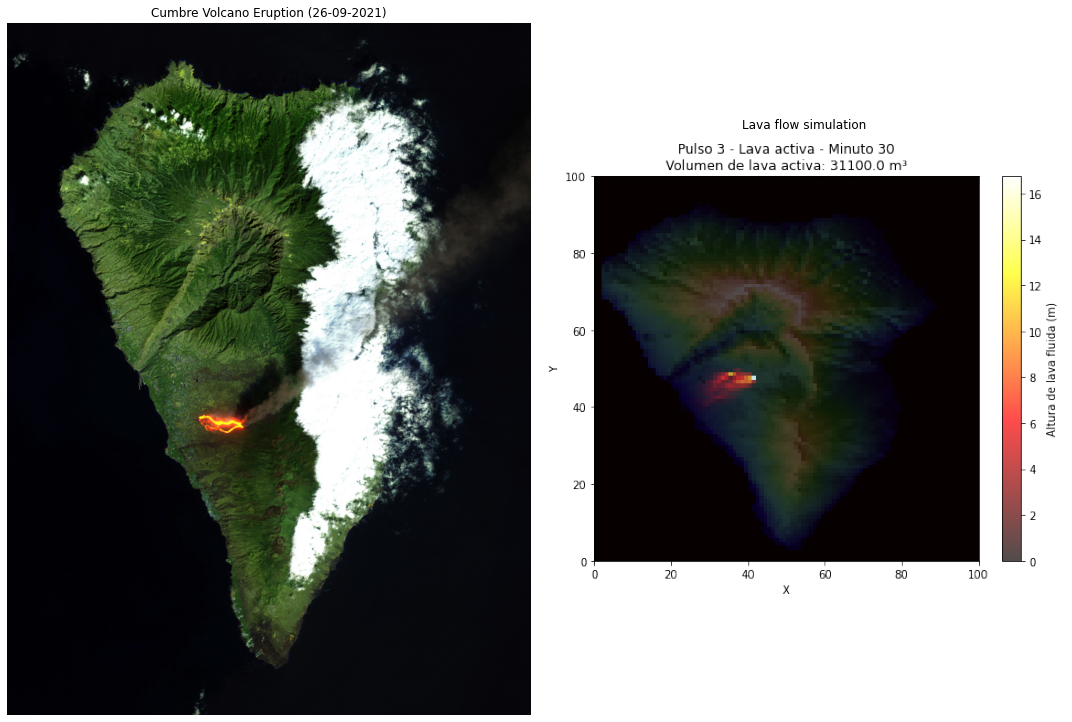

In [10]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Paths to the image files
path_img1 = '../data/Erupcion-Volcan-Cumbre-Vieja-La-Palma-Landsat8-26-09-21.jpg'
path_img2 = '../data/output.png'

# Load images
img1 = mpimg.imread(path_img1)
img2 = mpimg.imread(path_img2)

# Create a figure with subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 10))  # Adjust figure size as needed

# Display the first image
axs[0].imshow(img1)
axs[0].axis('off')  # Turn off axes for the first image
axs[0].set_title('Cumbre Volcano Eruption (26-09-2021)')

# Display the second image
axs[1].imshow(img2)
axs[1].axis('off')  # Turn off axes for the second image
axs[1].set_title('Lava flow simulation')

plt.tight_layout()
plt.show()
